<a href="https://colab.research.google.com/github/looly110033-eng/Hospital_appointemnt_scheduling_baseline/blob/main/Hospital_Scheduling_D_Consolidated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Hospital Appointment Scheduling**
This notebook implements a rule-based Single-Agent baseline in two environments: Easy/Static and Complex/Dynamic.

Research Question: Does a Multi-Agent System improve hospital appointment scheduling compared with a Single-Agent baseline as the environment becomes more complex and dynamic?

The evaluation covers assignment success, constraint violations, patient preference satisfaction, and dynamic-event handling. The generated inputs and evaluation metrics will support a later SA vs MAS comparison.

**Experiment 1 — Easy / Static Baseline**
Evaluate the Single-Agent scheduler on 100 appointment requests under static conditions.

### Doctors Dataset

In [1]:
import pandas as pd
import random

random.seed(42)

SPECIALTIES = [
    "Cardiology",
    "Dermatology",
    "Neurology",
    "Pediatrics",
    "Orthopedics",
    "General Medicine",
    "Internal Medicine",
    "ENT",
    "Ophthalmology",
    "Obstetrics and Gynecology"
]

def generate_doctors(num_doctors):
    doctors = []

    for i in range(1, num_doctors + 1):
        specialty = SPECIALTIES[(i - 1) % len(SPECIALTIES)]

        doctors.append({
            "doctor_id": f"D{i:03d}",
            "specialty": specialty,
            "experience_years": random.randint(3, 20),
            "work_start": "09:00",
            "work_end": "17:00",
            "max_daily_appointments": random.randint(1, 8)
        })

    return pd.DataFrame(doctors)

doctors_df = generate_doctors(20)

print("===== DOCTORS DATASET =====")
print("Number of doctors:", len(doctors_df))
print()
print(doctors_df)

===== DOCTORS DATASET =====
Number of doctors: 20

   doctor_id                  specialty  experience_years work_start work_end  \
0       D001                 Cardiology                 6      09:00    17:00   
1       D002                Dermatology                11      09:00    17:00   
2       D003                  Neurology                10      09:00    17:00   
3       D004                 Pediatrics                 6      09:00    17:00   
4       D005                Orthopedics                16      09:00    17:00   
5       D006           General Medicine                 3      09:00    17:00   
6       D007          Internal Medicine                 9      09:00    17:00   
7       D008                        ENT                19      09:00    17:00   
8       D009              Ophthalmology                20      09:00    17:00   
9       D010  Obstetrics and Gynecology                20      09:00    17:00   
10      D011                 Cardiology                10 

### Patients Dataset

In [2]:
from datetime import datetime, timedelta

PATIENT_COUNT = 100

PREFERRED_TIME_OPTIONS = [
    "Morning",
    "Afternoon",
    "No Preference"
]

def generate_patients(num_patients, doctors_df, start_date):
    patients = []

    for i in range(1, num_patients + 1):
        patient_id = f"P{i:03d}"

        required_specialty = random.choice(SPECIALTIES)

        specialty_doctors = doctors_df[
            doctors_df["specialty"] == required_specialty
        ]["doctor_id"].tolist()

        if random.random() < 0.40:
            preferred_doctor_id = random.choice(specialty_doctors)
        else:
            preferred_doctor_id = None

        # The scheduling horizon contains six dates: offsets 0 to 5.
        preferred_date = start_date + timedelta(
            days=random.randint(0, 5)
        )

        preferred_time = random.choice(PREFERRED_TIME_OPTIONS)

        patients.append({
            "patient_id": patient_id,
            "required_specialty": required_specialty,
            "preferred_doctor_id": preferred_doctor_id,
            "preferred_date": preferred_date.strftime("%Y-%m-%d"),
            "preferred_time": preferred_time
        })

    return pd.DataFrame(patients)


START_DATE = datetime(2026, 9, 14)

patients_df = generate_patients(
    PATIENT_COUNT,
    doctors_df,
    START_DATE
)

print("===== PATIENTS DATASET =====")
print("Number of patients:", len(patients_df))
print()

print(patients_df.head(10))

===== PATIENTS DATASET =====
Number of patients: 100

  patient_id         required_specialty preferred_doctor_id preferred_date  \
0       P001              Ophthalmology                D019     2026-09-14   
1       P002                Orthopedics                None     2026-09-18   
2       P003  Obstetrics and Gynecology                D010     2026-09-14   
3       P004                 Pediatrics                None     2026-09-14   
4       P005                Dermatology                D012     2026-09-19   
5       P006                  Neurology                D003     2026-09-19   
6       P007                Dermatology                None     2026-09-15   
7       P008                 Pediatrics                D014     2026-09-16   
8       P009              Ophthalmology                D019     2026-09-14   
9       P010                 Cardiology                None     2026-09-17   

  preferred_time  
0  No Preference  
1      Afternoon  
2  No Preference  
3        Mo

### Appointment Requests

In [3]:
def generate_appointment_requests(patients_df):
    requests = []

    for _, patient in patients_df.iterrows():

        request_id = f"R{len(requests) + 1:03d}"

        requests.append({
            "request_id": request_id,
            "patient_id": patient["patient_id"],
            "required_specialty": patient["required_specialty"],
            "preferred_doctor_id": patient["preferred_doctor_id"],
            "preferred_date": patient["preferred_date"],
            "preferred_time": patient["preferred_time"]
        })

    return pd.DataFrame(requests)


appointment_requests_df = generate_appointment_requests(
    patients_df
)

print("===== APPOINTMENT REQUESTS =====")
print("Number of appointment requests:", len(appointment_requests_df))
print()

print(appointment_requests_df.head(10))

===== APPOINTMENT REQUESTS =====
Number of appointment requests: 100

  request_id patient_id         required_specialty preferred_doctor_id  \
0       R001       P001              Ophthalmology                D019   
1       R002       P002                Orthopedics                None   
2       R003       P003  Obstetrics and Gynecology                D010   
3       R004       P004                 Pediatrics                None   
4       R005       P005                Dermatology                D012   
5       R006       P006                  Neurology                D003   
6       R007       P007                Dermatology                None   
7       R008       P008                 Pediatrics                D014   
8       R009       P009              Ophthalmology                D019   
9       R010       P010                 Cardiology                None   

  preferred_date preferred_time  
0     2026-09-14  No Preference  
1     2026-09-18      Afternoon  
2     2026-09

### Appointment Requests

In [4]:
WORK_START_TIME = 9
WORK_END_TIME = 17

SLOT_DURATION_MINUTES = 60

SCHEDULING_DAYS = 6


def generate_time_slots(doctors_df, start_date):
    slots = []

    for _, doctor in doctors_df.iterrows():

        doctor_id = doctor["doctor_id"]

        for day_offset in range(SCHEDULING_DAYS):

            current_date = start_date + timedelta(days=day_offset)

            current_time = datetime.combine(
                current_date,
                datetime.min.time()
            ).replace(hour=WORK_START_TIME)

            end_time = datetime.combine(
                current_date,
                datetime.min.time()
            ).replace(hour=WORK_END_TIME)

            while current_time < end_time:

                slot_end_time = current_time + timedelta(
                    minutes=SLOT_DURATION_MINUTES
                )

                slots.append({
                    "slot_id": f"S{len(slots) + 1:04d}",
                    "doctor_id": doctor_id,
                    "date": current_date.strftime("%Y-%m-%d"),
                    "start_time": current_time.strftime("%H:%M"),
                    "end_time": slot_end_time.strftime("%H:%M"),
                    "status": "Available"
                })

                current_time = slot_end_time

    return pd.DataFrame(slots)


slots_df = generate_time_slots(
    doctors_df,
    START_DATE
)


print("===== TIME SLOTS DATASET =====")
print("Number of doctors:", len(doctors_df))
print("Scheduling days:", SCHEDULING_DAYS)
print("Slot duration:", SLOT_DURATION_MINUTES, "minutes")
print("Working hours:", f"{WORK_START_TIME}:00 - {WORK_END_TIME}:00")
print("Total slots:", len(slots_df))
print()

print(slots_df.head(10))

===== TIME SLOTS DATASET =====
Number of doctors: 20
Scheduling days: 6
Slot duration: 60 minutes
Working hours: 9:00 - 17:00
Total slots: 960

  slot_id doctor_id        date start_time end_time     status
0   S0001      D001  2026-09-14      09:00    10:00  Available
1   S0002      D001  2026-09-14      10:00    11:00  Available
2   S0003      D001  2026-09-14      11:00    12:00  Available
3   S0004      D001  2026-09-14      12:00    13:00  Available
4   S0005      D001  2026-09-14      13:00    14:00  Available
5   S0006      D001  2026-09-14      14:00    15:00  Available
6   S0007      D001  2026-09-14      15:00    16:00  Available
7   S0008      D001  2026-09-14      16:00    17:00  Available
8   S0009      D001  2026-09-15      09:00    10:00  Available
9   S0010      D001  2026-09-15      10:00    11:00  Available


### Single-Agent Scheduling Logic

In [5]:
from datetime import datetime


# ---------------------------------------------------------
# 1. Check whether the selected time matches the preference
# ---------------------------------------------------------

def matches_time_preference(start_time, preferred_time):

    hour = int(start_time.split(":")[0])

    if preferred_time == "Morning":
        return hour < 12

    elif preferred_time == "Afternoon":
        return hour >= 12

    else:
        return True


# ---------------------------------------------------------
# 2. Calculate the score of a possible assignment
# ---------------------------------------------------------

def calculate_assignment_score(
    patient,
    doctor,
    slot,
    current_date
):

    score = 0

    # Preferred doctor
    if (
        patient["preferred_doctor_id"] is not None
        and patient["preferred_doctor_id"] == doctor["doctor_id"]
    ):
        score += 40

    # Preferred date
    if slot["date"] == patient["preferred_date"]:
        score += 30

    # Preferred time
    # Award points only when the patient specified a time preference.
    if (
        patient["preferred_time"] != "No Preference"
        and matches_time_preference(
            slot["start_time"],
            patient["preferred_time"]
       )
):
       score += 20

    # Earlier appointment
    slot_date = datetime.strptime(
        slot["date"],
        "%Y-%m-%d"
    ).date()

    preference_date = datetime.strptime(
        patient["preferred_date"],
        "%Y-%m-%d"
    ).date()

    days_from_preference = abs(
        (slot_date - preference_date).days
    )

    # Maximum 10 points for the closest date
    score += max(
        0,
        10 - days_from_preference
    )

    return score


# ---------------------------------------------------------
# 3. Check whether an assignment satisfies the constraints
# ---------------------------------------------------------

def is_valid_assignment(
    patient,
    doctor,
    slot,
    schedule,
    doctor_daily_counts
):

    # Specialty compatibility
    if doctor["specialty"] != patient["required_specialty"]:
        return False

    # Slot must be available
    if slot["status"] != "Available":
        return False

    # Doctor daily capacity
    doctor_id = doctor["doctor_id"]
    slot_date = slot["date"]

    current_daily_count = doctor_daily_counts.get(
        (doctor_id, slot_date),
        0
    )

    if current_daily_count >= doctor["max_daily_appointments"]:
        return False

    # Patient cannot have another appointment
    # on the same date and time
    for existing in schedule:

        if (
            existing["patient_id"] == patient["patient_id"]
            and existing["date"] == slot_date
            and existing["start_time"] == slot["start_time"]
        ):
            return False

    return True

### Run Single-Agent Baseline

In [6]:
def run_baseline(
    appointment_requests_df,
    patients_df,
    doctors_df,
    slots_df
):

    # Create working copies
    working_slots = slots_df.copy()

    schedule = []

    doctor_daily_counts = {}

    unscheduled_requests = []

    # -----------------------------------------------------
    # Process each appointment request
    # -----------------------------------------------------

    for _, request in appointment_requests_df.iterrows():

        patient = patients_df[
            patients_df["patient_id"] == request["patient_id"]
        ].iloc[0]

        # -------------------------------------------------
        # Generate candidate assignments
        # -------------------------------------------------

        candidates = []

        for _, doctor in doctors_df.iterrows():

            # Quick specialty filtering
            if doctor["specialty"] != patient["required_specialty"]:
                continue

            doctor_slots = working_slots[
                working_slots["doctor_id"] == doctor["doctor_id"]
            ]

            for slot_index, slot in doctor_slots.iterrows():

                # Check constraints
                if not is_valid_assignment(
                    patient,
                    doctor,
                    slot,
                    schedule,
                    doctor_daily_counts
                ):
                    continue

                # Calculate score
                score = calculate_assignment_score(
                    patient,
                    doctor,
                    slot,
                    START_DATE
                )

                candidates.append({
                    "doctor_id": doctor["doctor_id"],
                    "slot_id": slot["slot_id"],
                    "date": slot["date"],
                    "start_time": slot["start_time"],
                    "end_time": slot["end_time"],
                    "score": score
                })

        # -------------------------------------------------
        # Select the best candidate
        # -------------------------------------------------

        if len(candidates) == 0:

            unscheduled_requests.append({
                "request_id": request["request_id"],
                "patient_id": request["patient_id"],
                "reason": "No valid assignment available"
            })

            continue

        # Sort candidates
        candidates = sorted(
            candidates,
            key=lambda x: (
                -x["score"],
                x["date"],
                x["start_time"]
            )
        )

        best_assignment = candidates[0]

        # -------------------------------------------------
        # Book the selected slot
        # -------------------------------------------------

        selected_slot_id = best_assignment["slot_id"]

        working_slots.loc[
            working_slots["slot_id"] == selected_slot_id,
            "status"
        ] = "Booked"

        # Update doctor's daily appointment count
        doctor_id = best_assignment["doctor_id"]
        appointment_date = best_assignment["date"]

        key = (doctor_id, appointment_date)

        doctor_daily_counts[key] = (
            doctor_daily_counts.get(key, 0) + 1
        )

        # -------------------------------------------------
        # Add assignment to final schedule
        # -------------------------------------------------

        schedule.append({
            "request_id": request["request_id"],
            "patient_id": patient["patient_id"],
            "doctor_id": best_assignment["doctor_id"],
            "required_specialty": patient["required_specialty"],
            "slot_id": best_assignment["slot_id"],
            "date": best_assignment["date"],
            "start_time": best_assignment["start_time"],
            "end_time": best_assignment["end_time"],
            "score": best_assignment["score"]
        })

    return (
        pd.DataFrame(schedule),
        pd.DataFrame(unscheduled_requests),working_slots
    )


# ---------------------------------------------------------
# Run the Baseline
# ---------------------------------------------------------

baseline_schedule_df, unscheduled_df, baseline_slots_df = run_baseline(
    appointment_requests_df,
    patients_df,
    doctors_df,
    slots_df
)


print("===== BASELINE RUN =====")
print("Total requests:", len(appointment_requests_df))
print("Scheduled requests:", len(baseline_schedule_df))
print("Unscheduled requests:", len(unscheduled_df))
print()

print("===== BASELINE SCHEDULE PREVIEW =====")
print(baseline_schedule_df.head(10))

===== BASELINE RUN =====
Total requests: 100
Scheduled requests: 100
Unscheduled requests: 0

===== BASELINE SCHEDULE PREVIEW =====
  request_id patient_id doctor_id         required_specialty slot_id  \
0       R001       P001      D019              Ophthalmology   S0865   
1       R002       P002      D005                Orthopedics   S0228   
2       R003       P003      D010  Obstetrics and Gynecology   S0433   
3       R004       P004      D004                 Pediatrics   S0145   
4       R005       P005      D012                Dermatology   S0572   
5       R006       P006      D003                  Neurology   S0140   
6       R007       P007      D002                Dermatology   S0057   
7       R008       P008      D014                 Pediatrics   S0641   
8       R009       P009      D019              Ophthalmology   S0866   
9       R010       P010      D001                 Cardiology   S0028   

         date start_time end_time  score  
0  2026-09-14      09:00    10:0

### Final Baseline Schedule

In [7]:
baseline_schedule_df = baseline_schedule_df.sort_values(
    by=["date", "start_time", "doctor_id"]
).reset_index(drop=True)


print("===== FINAL BASELINE SCHEDULE =====")
print("Total scheduled appointments:", len(baseline_schedule_df))
print()

print(
    baseline_schedule_df[
        [
            "request_id",
            "patient_id",
            "doctor_id",
            "slot_id",
            "required_specialty",
            "date",
            "start_time",
            "end_time",
            "score"
        ]
    ].to_string(index=False)
)

===== FINAL BASELINE SCHEDULE =====
Total scheduled appointments: 100

request_id patient_id doctor_id slot_id        required_specialty       date start_time end_time  score
      R028       P028      D001   S0001                Cardiology 2026-09-14      09:00    10:00     80
      R064       P064      D003   S0097                 Neurology 2026-09-14      09:00    10:00     60
      R004       P004      D004   S0145                Pediatrics 2026-09-14      09:00    10:00     60
      R061       P061      D005   S0193               Orthopedics 2026-09-14      09:00    10:00     60
      R073       P073      D007   S0289         Internal Medicine 2026-09-14      09:00    10:00     60
      R016       P016      D008   S0337                       ENT 2026-09-14      09:00    10:00    100
      R019       P019      D009   S0385             Ophthalmology 2026-09-14      09:00    10:00     40
      R003       P003      D010   S0433 Obstetrics and Gynecology 2026-09-14      09:00    10:00 

### Baseline Validation

In [8]:
def validate_baseline_schedule(
    baseline_schedule_df,
    doctors_df,
    slots_df
):

    violations = []

    # ---------------------------------------------------------
    # 1. Check specialty compatibility
    # ---------------------------------------------------------

    for _, appointment in baseline_schedule_df.iterrows():

        doctor = doctors_df[
            doctors_df["doctor_id"] == appointment["doctor_id"]
        ].iloc[0]

        if doctor["specialty"] != appointment["required_specialty"]:

            violations.append({
                "patient_id": appointment["patient_id"],
                "violation": "Specialty mismatch"
            })

    # ---------------------------------------------------------
    # 2. Check duplicate slot assignments
    # ---------------------------------------------------------

    duplicate_slots = (
        baseline_schedule_df
        .groupby("slot_id")
        .size()
    )

    for slot_id, count in duplicate_slots.items():

        if count > 1:

            violations.append({
                "slot_id": slot_id,
                "violation": "Duplicate slot assignment"
            })

    # ---------------------------------------------------------
    # 3. Check patient overlapping appointments
    # ---------------------------------------------------------

    duplicate_patient_slots = (
        baseline_schedule_df
        .groupby(
            ["patient_id", "date", "start_time"]
        )
        .size()
    )

    for key, count in duplicate_patient_slots.items():

        if count > 1:

            violations.append({
                "patient_id": key[0],
                "date": key[1],
                "start_time": key[2],
                "violation": "Patient time conflict"
            })

    # ---------------------------------------------------------
    # 4. Check doctor daily capacity
    # ---------------------------------------------------------

    doctor_daily_counts = (
        baseline_schedule_df
        .groupby(["doctor_id", "date"])
        .size()
        .reset_index(name="appointment_count")
    )

    for _, row in doctor_daily_counts.iterrows():

        doctor = doctors_df[
            doctors_df["doctor_id"] == row["doctor_id"]
        ].iloc[0]

        if row["appointment_count"] > doctor["max_daily_appointments"]:

            violations.append({
                "doctor_id": row["doctor_id"],
                "date": row["date"],
                "violation": "Daily capacity exceeded"
            })

    # ---------------------------------------------------------
    # 5. Check that all assigned slots exist
    # ---------------------------------------------------------

    valid_slot_ids = set(slots_df["slot_id"])

    for _, appointment in baseline_schedule_df.iterrows():

        if appointment["slot_id"] not in valid_slot_ids:

            violations.append({
                "patient_id": appointment["patient_id"],
                "slot_id": appointment["slot_id"],
                "violation": "Invalid slot"
            })

    return pd.DataFrame(violations)


# ---------------------------------------------------------
# Run validation
# ---------------------------------------------------------

baseline_violations_df = validate_baseline_schedule(
    baseline_schedule_df,
    doctors_df,
    slots_df
)


print("===== BASELINE VALIDATION =====")
print("Total scheduled appointments:", len(baseline_schedule_df))
print("Total constraint violations:", len(baseline_violations_df))
print()

if len(baseline_violations_df) == 0:
    print("✓ Baseline schedule is valid.")
else:
    print(baseline_violations_df)

===== BASELINE VALIDATION =====
Total scheduled appointments: 100
Total constraint violations: 0

✓ Baseline schedule is valid.


### Baseline Evaluation

In [9]:
def calculate_baseline_metrics(
    baseline_schedule_df,
    appointment_requests_df,
    baseline_violations_df
):

    total_patients = len(appointment_requests_df)

    scheduled_patients = len(baseline_schedule_df)

    unscheduled_patients = (
        total_patients - scheduled_patients
    )

    # ---------------------------------------------------------
    # Successful Assignment Rate
    # ---------------------------------------------------------

    successful_assignment_rate = (
        scheduled_patients / total_patients
    ) * 100

    # ---------------------------------------------------------
    # Preferred Doctor Satisfaction
    # ---------------------------------------------------------

    requests_with_preferred_doctor = (
        appointment_requests_df[
            appointment_requests_df["preferred_doctor_id"].notna()
        ]
    )

    if len(requests_with_preferred_doctor) > 0:

        doctor_check = baseline_schedule_df.merge(
            requests_with_preferred_doctor[
                ["request_id", "preferred_doctor_id"]
            ],
            on="request_id",
            how="inner"
        )

        preferred_doctor_satisfaction = (
            (
                doctor_check["doctor_id"]
                == doctor_check["preferred_doctor_id"]
            ).mean()
            * 100
        )

    else:
        preferred_doctor_satisfaction = 0

    # ---------------------------------------------------------
    # Preferred Date Satisfaction
    # ---------------------------------------------------------

    date_check = baseline_schedule_df.merge(
        appointment_requests_df[
            ["request_id", "preferred_date"]
        ],
        on="request_id",
        how="left"
    )

    preferred_date_satisfaction = (
        (
            date_check["date"]
            == date_check["preferred_date"]
        ).mean()
        * 100
    )

    # ---------------------------------------------------------
    # Preferred Time Satisfaction
    # ---------------------------------------------------------

    time_check = baseline_schedule_df.merge(
        appointment_requests_df[
            ["request_id", "preferred_time"]
        ],
        on="request_id",
        how="left"
    )

    def check_time(row):

        if row["preferred_time"] == "No Preference":
            return None

        return matches_time_preference(
            row["start_time"],
            row["preferred_time"]
        )

    time_results = time_check.apply(
        check_time,
        axis=1
    )

    preferred_time_satisfaction = (
        time_results.dropna().mean()
        * 100
    )

    # ---------------------------------------------------------
    # Date Deviation
    # ---------------------------------------------------------

    date_check["date_deviation"] = (
        pd.to_datetime(date_check["date"])
        - pd.to_datetime(date_check["preferred_date"])
    ).dt.days.abs()

    average_date_deviation = (
        date_check["date_deviation"].mean()
    )

    maximum_date_deviation = (
        date_check["date_deviation"].max()
    )

    # ---------------------------------------------------------
    # Constraint Violations
    # ---------------------------------------------------------

    constraint_violations = len(
        baseline_violations_df
    )

    # ---------------------------------------------------------
    # Create metrics dictionary
    # ---------------------------------------------------------

    metrics = {
        "Total Patients": total_patients,
        "Scheduled Patients": scheduled_patients,
        "Unscheduled Patients": unscheduled_patients,
        "Successful Assignment Rate (%)":
            successful_assignment_rate,
        "Constraint Violations":
            constraint_violations,
        "Preferred Doctor Satisfaction (%)":
            preferred_doctor_satisfaction,
        "Preferred Date Satisfaction (%)":
            preferred_date_satisfaction,
        "Preferred Time Satisfaction (%)":
        preferred_time_satisfaction,
        "Average Date Deviation (days)":
            average_date_deviation,
        "Maximum Date Deviation (days)":
            maximum_date_deviation
    }

    return metrics


# ---------------------------------------------------------
# Calculate Baseline Metrics
# ---------------------------------------------------------

baseline_metrics = calculate_baseline_metrics(
    baseline_schedule_df,
    appointment_requests_df,
    baseline_violations_df
)


print("===== BASELINE EVALUATION =====")

for metric, value in baseline_metrics.items():

    if isinstance(value, float):
        print(f"{metric}: {value:.2f}")
    else:
        print(f"{metric}: {value}")

===== BASELINE EVALUATION =====
Total Patients: 100
Scheduled Patients: 100
Unscheduled Patients: 0
Successful Assignment Rate (%): 100.00
Constraint Violations: 0
Preferred Doctor Satisfaction (%): 100.00
Preferred Date Satisfaction (%): 98.00
Preferred Time Satisfaction (%): 100.00
Average Date Deviation (days): 0.02
Maximum Date Deviation (days): 1


In [10]:
# Experiment 1 — Export Shared Inputs and Baseline Results

from pathlib import Path
import json

# Keep Experiment 1 and Experiment 2 in separate folders.
shared_data_dir = (
    Path("shared_experiment_inputs")
    / "experiment_1_easy_static"
)
shared_data_dir.mkdir(parents=True, exist_ok=True)

# Shared inputs: both SA and MAS must use these same files.
shared_datasets = {
    "doctors.csv": doctors_df,
    "patients.csv": patients_df,
    "appointment_requests.csv": appointment_requests_df,
    "time_slots.csv": slots_df,
}

# Reference outputs produced by the Single-Agent baseline.
baseline_outputs = {
    "initial_schedule.csv": baseline_schedule_df,
    "final_slot_state.csv": baseline_slots_df,
    "baseline_metrics.csv": pd.DataFrame(
        [
            {"Metric": metric, "Value": value}
            for metric, value in baseline_metrics.items()
        ]
    ),
}

# Ensure empty result files still have useful column headers.
unscheduled_export = unscheduled_df.copy()
if unscheduled_export.empty and len(unscheduled_export.columns) == 0:
    unscheduled_export = pd.DataFrame(
        columns=["request_id", "patient_id", "reason"]
    )

violations_export = baseline_violations_df.copy()
if violations_export.empty and len(violations_export.columns) == 0:
    violations_export = pd.DataFrame(
        columns=["patient_id", "violation"]
    )

baseline_outputs["unscheduled_requests.csv"] = (
    unscheduled_export
)
baseline_outputs["constraint_violations.csv"] = (
    violations_export
)

# Save all input and output tables.
for filename, dataframe in {
    **shared_datasets,
    **baseline_outputs,
}.items():
    dataframe.to_csv(
        shared_data_dir / filename,
        index=False
    )

# Save the experiment configuration for reproducibility.
experiment_config = {
    "experiment": "Experiment 1 - Easy / Static",
    "random_seed": 42,
    "doctor_count": len(doctors_df),
    "patient_count": len(patients_df),
    "appointment_request_count": len(appointment_requests_df),
    "scheduling_days": SCHEDULING_DAYS,
    "slot_duration_minutes": SLOT_DURATION_MINUTES,
    "work_start_time": WORK_START_TIME,
    "work_end_time": WORK_END_TIME,
    "dynamic_events_enabled": False,
    "scoring_weights": {
        "preferred_doctor": 40,
        "preferred_date": 30,
        "preferred_time": 20,
        "earlier_date_bonus_max": 10,
    },
}

with open(
    shared_data_dir / "experiment_config.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        experiment_config,
        file,
        indent=2,
        ensure_ascii=False
    )

print("===== EXPERIMENT 1 EXPORT =====")
print("Export directory:", shared_data_dir.resolve())
print("Input files:", len(shared_datasets))
print("Baseline output files:", len(baseline_outputs))
print("Configuration file: experiment_config.json")
print("✓ Experiment 1 data and baseline results exported.")

===== EXPERIMENT 1 EXPORT =====
Export directory: /content/shared_experiment_inputs/experiment_1_easy_static
Input files: 4
Baseline output files: 5
Configuration file: experiment_config.json
✓ Experiment 1 data and baseline results exported.


Experiment 2 — Complex / Dynamic Baseline
Evaluate the Single-Agent scheduler with 40 doctors, 3,298 initial appointment requests, 30- and 60-minute appointments, capacity and waiting constraints, and 290 dynamic events.
The experiment evaluates the initial schedule, then processes cancellations, doctor unavailability, new requests, and schedule changes.

### M1 — Expanded Doctors Dataset

In [11]:
import random
import pandas as pd
from datetime import datetime, timedelta


MEDIUM_RANDOM_SEED = 42
random.seed(MEDIUM_RANDOM_SEED)

# Existing: 20 doctors
# Experiment 2: 40 doctors
MEDIUM_DOCTOR_COUNT = 40

MEDIUM_SPECIALTIES = [
    "Cardiology",
    "Dermatology",
    "Neurology",
    "Pediatrics",
    "Orthopedics",
    "General Medicine",
    "Internal Medicine",
    "ENT",
    "Ophthalmology",
    "Obstetrics and Gynecology"
]

# Four doctors per specialty
DOCTORS_PER_SPECIALTY = 4

WORK_SHIFTS = [
    ("08:00", "14:00"),
    ("09:00", "15:00"),
    ("10:00", "16:00")
]


def generate_medium_doctors():
    doctors = []
    doctor_number = 1

    for specialty in MEDIUM_SPECIALTIES:

        for _ in range(DOCTORS_PER_SPECIALTY):

            work_start, work_end = random.choice(WORK_SHIFTS)

            experience_years = random.randint(3, 20)

            # Slightly tighter capacity than the old Medium
            max_daily_appointments = random.choice([3, 4, 5])

            # New resource constraint.
            # A 30-minute appointment consumes 30 minutes;
            # a 60-minute appointment consumes 60 minutes.
            max_daily_minutes = random.choice([180, 210, 240])

            doctors.append({
                "doctor_id": f"D{doctor_number:03d}",
                "specialty": specialty,
                "experience_years": experience_years,
                "work_start": work_start,
                "work_end": work_end,
                "max_daily_appointments": max_daily_appointments,
                "max_daily_minutes": max_daily_minutes
            })

            doctor_number += 1

    return pd.DataFrame(doctors)


medium_doctors_df = generate_medium_doctors()

print("===== EXPERIMENT 2 — M1 DOCTORS =====")
print("Number of doctors:", len(medium_doctors_df))
print("Number of specialties:", medium_doctors_df["specialty"].nunique())
print("Doctors per specialty:", DOCTORS_PER_SPECIALTY)
print()
print(medium_doctors_df.head(10))

===== EXPERIMENT 2 — M1 DOCTORS =====
Number of doctors: 40
Number of specialties: 10
Doctors per specialty: 4

  doctor_id    specialty  experience_years work_start work_end  \
0      D001   Cardiology                 6      10:00    16:00   
1      D002   Cardiology                10      09:00    15:00   
2      D003   Cardiology                 6      10:00    16:00   
3      D004   Cardiology                 5      10:00    16:00   
4      D005  Dermatology                 3      08:00    14:00   
5      D006  Dermatology                19      08:00    14:00   
6      D007  Dermatology                 9      10:00    16:00   
7      D008  Dermatology                20      10:00    16:00   
8      D009    Neurology                11      09:00    15:00   
9      D010    Neurology                16      10:00    16:00   

   max_daily_appointments  max_daily_minutes  
0                       3                240  
1                       3                180  
2                   

### M2 — Expanded Patient Dataset

In [12]:
# Existing: 100 patients / 6 days
# Experiment 2: 2200 patients / 21 days

MEDIUM_PATIENT_COUNT = 2200
MEDIUM_START_DATE = datetime(2026, 9, 14)
MEDIUM_SCHEDULING_DAYS = 21

PREFERRED_TIME_OPTIONS = [
    "Morning",
    "Afternoon",
    "No Preference"
]

# 50% of patients require a second appointment.
MULTI_APPOINTMENT_PROBABILITY = 0.50

# Maximum allowed waiting time for an appointment request.
MAX_WAITING_DAYS_OPTIONS = [3, 5, 7]

# 40% of requests require a 60-minute appointment.
LONG_APPOINTMENT_PROBABILITY = 0.40


def generate_medium_patients(
    num_patients,
    doctors_df,
    start_date
):
    patients = []

    for i in range(1, num_patients + 1):

        patient_id = f"P{i:04d}"

        # Primary specialty
        required_specialty = random.choice(
            MEDIUM_SPECIALTIES
        )

        # Around 40% have a preferred doctor
        specialty_doctors = doctors_df[
            doctors_df["specialty"] == required_specialty
        ]["doctor_id"].tolist()

        if random.random() < 0.40:
            preferred_doctor_id = random.choice(
                specialty_doctors
            )
        else:
            preferred_doctor_id = None

        preferred_date = start_date + timedelta(
            days=random.randint(
                0,
                MEDIUM_SCHEDULING_DAYS - 1
            )
        )

        preferred_time = random.choice(
            PREFERRED_TIME_OPTIONS
        )

        max_waiting_days = random.choice(
            MAX_WAITING_DAYS_OPTIONS
        )

        # Some patients require a second appointment
        # with another specialty.
        requires_second_appointment = (
            random.random()
            < MULTI_APPOINTMENT_PROBABILITY
        )

        second_specialty = None

        if requires_second_appointment:
            second_specialty_options = [
                s for s in MEDIUM_SPECIALTIES
                if s != required_specialty
            ]

            second_specialty = random.choice(
                second_specialty_options
            )

        patients.append({
            "patient_id": patient_id,
            "required_specialty": required_specialty,
            "preferred_doctor_id": preferred_doctor_id,
            "preferred_date": preferred_date.strftime("%Y-%m-%d"),
            "preferred_time": preferred_time,
            "max_waiting_days": max_waiting_days,
            "requires_second_appointment": requires_second_appointment,
            "second_specialty": second_specialty
        })

    return pd.DataFrame(patients)


medium_patients_df = generate_medium_patients(
    MEDIUM_PATIENT_COUNT,
    medium_doctors_df,
    MEDIUM_START_DATE
)

print()
print("===== EXPERIMENT 2 — M2 PATIENTS =====")
print("Number of patients:", len(medium_patients_df))
print("Scheduling days:", MEDIUM_SCHEDULING_DAYS)
print(
    "Patients requiring a second appointment:",
    medium_patients_df["requires_second_appointment"].sum()
)
print()
print(medium_patients_df.head(10))



===== EXPERIMENT 2 — M2 PATIENTS =====
Number of patients: 2200
Scheduling days: 21
Patients requiring a second appointment: 1098

  patient_id required_specialty preferred_doctor_id preferred_date  \
0      P0001          Neurology                None     2026-09-22   
1      P0002        Dermatology                None     2026-09-23   
2      P0003          Neurology                D010     2026-10-01   
3      P0004                ENT                D031     2026-09-23   
4      P0005        Dermatology                None     2026-09-16   
5      P0006      Ophthalmology                D036     2026-09-20   
6      P0007        Orthopedics                D019     2026-09-28   
7      P0008        Dermatology                D006     2026-10-02   
8      P0009         Pediatrics                D013     2026-09-24   
9      P0010         Pediatrics                None     2026-10-02   

  preferred_time  max_waiting_days  requires_second_appointment  \
0  No Preference              

### M3 — Appointment Requests

In [13]:
def generate_medium_appointment_requests(
    patients_df
):
    requests = []

    for _, patient in patients_df.iterrows():

        # Every patient gets a primary request.
        request_number = len(requests) + 1

        primary_duration = (
            60
            if random.random() < LONG_APPOINTMENT_PROBABILITY
            else 30
        )

        requests.append({
            "request_id": f"R{request_number:04d}",
            "patient_id": patient["patient_id"],
            "appointment_number": 1,
            "required_specialty": patient["required_specialty"],
            "preferred_doctor_id": patient["preferred_doctor_id"],
            "preferred_date": patient["preferred_date"],
            "preferred_time": patient["preferred_time"],
            "max_waiting_days": patient["max_waiting_days"],
            "appointment_duration": primary_duration
        })

        # Some patients receive a second request.
        if patient["requires_second_appointment"]:

            request_number = len(requests) + 1

            second_duration = (
                60
                if random.random() < LONG_APPOINTMENT_PROBABILITY
                else 30
            )

            requests.append({
                "request_id": f"R{request_number:04d}",
                "patient_id": patient["patient_id"],
                "appointment_number": 2,
                "required_specialty": patient["second_specialty"],
                # No artificial preferred doctor is assigned
                # for the second specialty.
                "preferred_doctor_id": None,
                "preferred_date": patient["preferred_date"],
                "preferred_time": patient["preferred_time"],
                "max_waiting_days": patient["max_waiting_days"],
                "appointment_duration": second_duration
            })

    return pd.DataFrame(requests)


medium_appointment_requests_df = (
    generate_medium_appointment_requests(
        medium_patients_df
    )
)

print()
print("===== EXPERIMENT 2 — M3 REQUESTS =====")
print(
    "Number of appointment requests:",
    len(medium_appointment_requests_df)
)
print(
    "Patients with multiple requests:",
    medium_appointment_requests_df[
        "patient_id"
    ].value_counts().gt(1).sum()
)
print()
print(
    medium_appointment_requests_df.head(10)
)



===== EXPERIMENT 2 — M3 REQUESTS =====
Number of appointment requests: 3298
Patients with multiple requests: 1098

  request_id patient_id  appointment_number required_specialty  \
0      R0001      P0001                   1          Neurology   
1      R0002      P0002                   1        Dermatology   
2      R0003      P0003                   1          Neurology   
3      R0004      P0004                   1                ENT   
4      R0005      P0004                   2        Dermatology   
5      R0006      P0005                   1        Dermatology   
6      R0007      P0005                   2      Ophthalmology   
7      R0008      P0006                   1      Ophthalmology   
8      R0009      P0007                   1        Orthopedics   
9      R0010      P0007                   2         Pediatrics   

  preferred_doctor_id preferred_date preferred_time  max_waiting_days  \
0                None     2026-09-22  No Preference                 3   
1          

### M4 — Time Slots

In [14]:
MEDIUM_SLOT_DURATION_MINUTES = 30


def generate_medium_time_slots(
    doctors_df,
    start_date,
    scheduling_days
):

    slots = []

    for _, doctor in doctors_df.iterrows():

        doctor_id = doctor["doctor_id"]

        start_hour, start_minute = map(
            int,
            doctor["work_start"].split(":")
        )

        end_hour, end_minute = map(
            int,
            doctor["work_end"].split(":")
        )

        for day_offset in range(scheduling_days):

            current_date = (
                start_date
                + timedelta(days=day_offset)
            )

            current_time = datetime.combine(
                current_date,
                datetime.min.time()
            ).replace(
                hour=start_hour,
                minute=start_minute
            )

            end_time = datetime.combine(
                current_date,
                datetime.min.time()
            ).replace(
                hour=end_hour,
                minute=end_minute
            )

            while current_time < end_time:

                slot_end_time = (
                    current_time
                    + timedelta(
                        minutes=MEDIUM_SLOT_DURATION_MINUTES
                    )
                )

                slots.append({
                    "slot_id": f"S{len(slots) + 1:06d}",
                    "doctor_id": doctor_id,
                    "date": current_date.strftime("%Y-%m-%d"),
                    "start_time": current_time.strftime("%H:%M"),
                    "end_time": slot_end_time.strftime("%H:%M"),
                    "status": "Available"
                })

                current_time = slot_end_time

    return pd.DataFrame(slots)


medium_slots_df = generate_medium_time_slots(
    medium_doctors_df,
    MEDIUM_START_DATE,
    MEDIUM_SCHEDULING_DAYS
)

print()
print("===== EXPERIMENT 2 — M4 TIME SLOTS =====")
print("Number of doctors:", len(medium_doctors_df))
print("Scheduling days:", MEDIUM_SCHEDULING_DAYS)
print("Base slot duration:", MEDIUM_SLOT_DURATION_MINUTES)
print("Total slots:", len(medium_slots_df))
print()
print(medium_slots_df.head(10))



===== EXPERIMENT 2 — M4 TIME SLOTS =====
Number of doctors: 40
Scheduling days: 21
Base slot duration: 30
Total slots: 10080

   slot_id doctor_id        date start_time end_time     status
0  S000001      D001  2026-09-14      10:00    10:30  Available
1  S000002      D001  2026-09-14      10:30    11:00  Available
2  S000003      D001  2026-09-14      11:00    11:30  Available
3  S000004      D001  2026-09-14      11:30    12:00  Available
4  S000005      D001  2026-09-14      12:00    12:30  Available
5  S000006      D001  2026-09-14      12:30    13:00  Available
6  S000007      D001  2026-09-14      13:00    13:30  Available
7  S000008      D001  2026-09-14      13:30    14:00  Available
8  S000009      D001  2026-09-14      14:00    14:30  Available
9  S000010      D001  2026-09-14      14:30    15:00  Available


### M5 — Initial Scheduling

In [15]:
MEDIUM_SLOT_DURATION_MINUTES = 30


def time_to_minutes(time_string):
    hour, minute = map(int, time_string.split(":"))
    return hour * 60 + minute


def matches_medium_time_preference(start_time, preferred_time):
    hour = int(start_time[:2])
    if preferred_time == "Morning":
        return hour < 12
    if preferred_time == "Afternoon":
        return hour >= 12
    return True


def calculate_medium_assignment_score_fast(
    preferred_doctor_id,
    preferred_date,
    preferred_time,
    doctor_id,
    slot_date,
    slot_start_hour,
    date_difference
):
    score = 0

    if preferred_doctor_id is not None and preferred_doctor_id == doctor_id:
        score += 40

    if slot_date == preferred_date:
        score += 30

    if preferred_time != "No Preference":
        if preferred_time == "Morning" and slot_start_hour < 12:
            score += 20
        elif preferred_time == "Afternoon" and slot_start_hour >= 12:
            score += 20

    score += max(0, 10 - date_difference)
    return score


def get_required_slot_keys(
    doctor_id,
    date,
    start_time,
    duration_minutes,
    slots_by_key
):
    """Return the consecutive 30-minute base-slot keys."""
    duration_slots = int(duration_minutes) // MEDIUM_SLOT_DURATION_MINUTES
    start_min = time_to_minutes(start_time)
    required_keys = []

    for i in range(duration_slots):
        slot_start_min = start_min + i * MEDIUM_SLOT_DURATION_MINUTES
        slot_end_min = slot_start_min + MEDIUM_SLOT_DURATION_MINUTES
        slot_start = f"{slot_start_min // 60:02d}:{slot_start_min % 60:02d}"
        slot_end = f"{slot_end_min // 60:02d}:{slot_end_min % 60:02d}"
        key = (doctor_id, date, slot_start, slot_end)
        if key not in slots_by_key:
            return None
        required_keys.append(key)

    return required_keys


def run_medium_baseline(
    appointment_requests_df,
    doctors_df,
    slots_df
):
    """
    Optimized implementation of the same Medium single-agent
    scheduling policy.

    Important: no patient priority is used.
    """

    schedule = []
    unscheduled = []

    # --------------------------------------------------------
    # 1. Fast doctor lookup
    # --------------------------------------------------------
    doctors_lookup = {}
    for row in doctors_df.to_dict("records"):
        doctors_lookup[row["doctor_id"]] = row

    # --------------------------------------------------------
    # 2. Precompute slot information once.
    #    Each candidate already contains the required 30/60-min
    #    block, so M5 does not reconstruct it for every request.
    # --------------------------------------------------------
    slots_by_specialty_duration = {}
    slot_lookup = {}

    for specialty in MEDIUM_SPECIALTIES:
        slots_by_specialty_duration[(specialty, 30)] = []
        slots_by_specialty_duration[(specialty, 60)] = []

    for row in slots_df.to_dict("records"):
        doctor_id = row["doctor_id"]
        doctor = doctors_lookup[doctor_id]
        date = row["date"]
        start_time = row["start_time"]
        end_time = row["end_time"]

        key = (doctor_id, date, start_time, end_time)
        slot_lookup[key] = row

        start_min = time_to_minutes(start_time)
        end_min = time_to_minutes(end_time)

        candidate_base = {
            "doctor_id": doctor_id,
            "doctor": doctor,
            "date": date,
            "start_time": start_time,
            "start_min": start_min,
            "start_hour": start_min // 60,
            "end_time": end_time,
            "end_min": end_min,
            "slot_key": key,
        }

        slots_by_specialty_duration[(doctor["specialty"], 30)].append(
            (candidate_base, (key,))
        )

    # Build valid 60-minute blocks from consecutive base slots.
    # Only 30-minute grid continuity is accepted.
    for specialty in MEDIUM_SPECIALTIES:
        base_candidates = slots_by_specialty_duration[(specialty, 30)]
        base_by_key = {
            item[0]["slot_key"]: item[0]
            for item in base_candidates
        }

        for base, _ in base_candidates:
            first_key = base["slot_key"]
            next_start_min = base["start_min"] + 30
            next_start = f"{next_start_min // 60:02d}:{next_start_min % 60:02d}"
            next_key = (
                base["doctor_id"],
                base["date"],
                next_start,
                f"{(next_start_min + 30) // 60:02d}:{(next_start_min + 30) % 60:02d}"
            )

            second = base_by_key.get(next_key)
            if second is None:
                continue

            block = dict(base)
            block["end_time"] = second["end_time"]
            block["end_min"] = second["end_min"]
            slots_by_specialty_duration[(specialty, 60)].append(
                (block, (first_key, next_key))
            )

    # --------------------------------------------------------
    # 3. Convert requests to records and precompute dates.
    # --------------------------------------------------------
    request_records = []
    for request in appointment_requests_df.to_dict("records"):
        preferred_date_obj = datetime.strptime(
            request["preferred_date"], "%Y-%m-%d"
        ).date()
        request["_preferred_date_obj"] = preferred_date_obj
        request["_preferred_doctor_id"] = request["preferred_doctor_id"]
        request_records.append(request)

    # --------------------------------------------------------
    # 4. Incremental state for O(1)-average capacity and overlap
    #    checks. This replaces repeated scans of the schedule.
    # --------------------------------------------------------
    booked_slots = set()
    doctor_daily_counts = {}
    doctor_daily_minutes = {}

    # patient_intervals[(patient_id, date)] = [(start_min, end_min), ...]
    patient_intervals = {}

    for request in request_records:
        duration = int(request["appointment_duration"])
        specialty = request["required_specialty"]
        candidates = slots_by_specialty_duration.get(
            (specialty, duration), []
        )

        preferred_date_obj = request["_preferred_date_obj"]
        max_waiting_days = int(request["max_waiting_days"])
        preferred_doctor_id = request["preferred_doctor_id"]
        preferred_time = request["preferred_time"]
        patient_id = request["patient_id"]

        best = None
        best_sort_key = None

        # ----------------------------------------------------
        # 5. Scan only valid specialty + duration candidates.
        #    No DataFrame filtering and no datetime parsing occur
        #    inside this loop.
        # ----------------------------------------------------
        for candidate, required_keys in candidates:
            doctor_id = candidate["doctor_id"]
            date = candidate["date"]
            start_min = candidate["start_min"]
            end_min = candidate["end_min"]

            if any(key in booked_slots for key in required_keys):
                continue

            capacity_key = (doctor_id, date)
            current_count = doctor_daily_counts.get(capacity_key, 0)
            doctor = candidate["doctor"]

            if current_count >= int(doctor["max_daily_appointments"]):
                continue

            current_minutes = doctor_daily_minutes.get(capacity_key, 0)
            if current_minutes + duration > int(doctor["max_daily_minutes"]):
                continue

            scheduled_date = datetime.strptime(date, "%Y-%m-%d").date()
            date_difference = abs((scheduled_date - preferred_date_obj).days)

            if date_difference > max_waiting_days:
                continue

            # Patient overlap check uses only appointments already
            # assigned to this patient on this date.
            intervals = patient_intervals.get((patient_id, date), [])
            overlap = False
            for existing_start, existing_end in intervals:
                if start_min < existing_end and end_min > existing_start:
                    overlap = True
                    break

            if overlap:
                continue

            score = calculate_medium_assignment_score_fast(
                preferred_doctor_id,
                request["preferred_date"],
                preferred_time,
                doctor_id,
                date,
                candidate["start_hour"],
                date_difference
            )

            # Same tie-breaking policy as before:
            # highest score -> earliest date -> earliest start time.
            sort_key = (-score, date, candidate["start_time"])

            if best is None or sort_key < best_sort_key:
                best = (candidate, required_keys, score, capacity_key)
                best_sort_key = sort_key

        if best is not None:
            candidate, required_keys, score, capacity_key = best
            doctor = candidate["doctor"]
            date = candidate["date"]
            start_time = candidate["start_time"]
            end_time = candidate["end_time"]

            schedule.append({
                "request_id": request["request_id"],
                "patient_id": patient_id,
                "appointment_number": request["appointment_number"],
                "doctor_id": doctor["doctor_id"],
                "required_specialty": request["required_specialty"],
                "date": date,
                "start_time": start_time,
                "end_time": end_time,
                "appointment_duration": duration,
                "preferred_doctor_id": request["preferred_doctor_id"],
                "preferred_date": request["preferred_date"],
                "preferred_time": request["preferred_time"],
                "max_waiting_days": request["max_waiting_days"],
                "score": score
            })

            booked_slots.update(required_keys)
            doctor_daily_counts[capacity_key] = (
                doctor_daily_counts.get(capacity_key, 0) + 1
            )
            doctor_daily_minutes[capacity_key] = (
                doctor_daily_minutes.get(capacity_key, 0) + duration
            )
            patient_intervals.setdefault((patient_id, date), []).append(
                (candidate["start_min"], candidate["end_min"])
            )

        else:
            unscheduled.append({
                "request_id": request["request_id"],
                "patient_id": patient_id,
                "appointment_number": request["appointment_number"],
                "required_specialty": specialty,
                "appointment_duration": duration
            })

    return pd.DataFrame(schedule), pd.DataFrame(unscheduled)


medium_baseline_schedule_df, medium_baseline_unscheduled_df = (
    run_medium_baseline(
        medium_appointment_requests_df,
        medium_doctors_df,
        medium_slots_df
    )
)

print()
print("===== EXPERIMENT 2 — M5 INITIAL BASELINE =====")
print("Total appointment requests:", len(medium_appointment_requests_df))
print("Scheduled appointments:", len(medium_baseline_schedule_df))
print("Unscheduled appointments:", len(medium_baseline_unscheduled_df))



===== EXPERIMENT 2 — M5 INITIAL BASELINE =====
Total appointment requests: 3298
Scheduled appointments: 3113
Unscheduled appointments: 185


### M6 — Initial Validation

In [16]:
def validate_medium_baseline_schedule(schedule_df, doctors_df, slots_df):
    """Validate the Medium baseline without repeated DataFrame scans."""
    violations = []
    doctors_lookup = {r["doctor_id"]: r for r in doctors_df.to_dict("records")}
    valid_slots = {(r["doctor_id"], r["date"], r["start_time"], r["end_time"]) for r in slots_df.to_dict("records")}
    slots_by_key = {k: True for k in valid_slots}
    doctor_daily_counts = {}
    doctor_daily_minutes = {}
    doctor_slot_assignments = set()
    patient_groups = {}

    for appointment in schedule_df.to_dict("records"):
        doctor_id = appointment["doctor_id"]; patient_id = appointment["patient_id"]
        date = appointment["date"]; start_time = appointment["start_time"]
        duration = int(appointment["appointment_duration"])

        if doctor_id not in doctors_lookup:
            violations.append({"patient_id": patient_id, "doctor_id": doctor_id, "violation": "Doctor does not exist"})
            continue
        doctor = doctors_lookup[doctor_id]

        if doctor["specialty"] != appointment["required_specialty"]:
            violations.append({"patient_id": patient_id, "doctor_id": doctor_id, "violation": "Specialty mismatch"})

        required_keys = get_required_slot_keys(doctor_id, date, start_time, duration, slots_by_key)
        if required_keys is None:
            violations.append({"patient_id": patient_id, "doctor_id": doctor_id, "violation": "Invalid or non-consecutive appointment slots"})
        else:
            for slot_key in required_keys:
                if slot_key in doctor_slot_assignments:
                    violations.append({"patient_id": patient_id, "doctor_id": doctor_id, "violation": "Doctor double booking"})
                doctor_slot_assignments.add(slot_key)

        capacity_key = (doctor_id, date)
        count = doctor_daily_counts.get(capacity_key, 0) + 1
        doctor_daily_counts[capacity_key] = count
        if count > int(doctor["max_daily_appointments"]):
            violations.append({"patient_id": patient_id, "doctor_id": doctor_id, "violation": "Doctor daily appointment capacity exceeded"})

        minutes = doctor_daily_minutes.get(capacity_key, 0) + duration
        doctor_daily_minutes[capacity_key] = minutes
        if minutes > int(doctor["max_daily_minutes"]):
            violations.append({"patient_id": patient_id, "doctor_id": doctor_id, "violation": "Doctor daily minutes exceeded"})

        patient_groups.setdefault((patient_id, date), []).append(appointment)

    for (patient_id, date), appointments in patient_groups.items():
        if len(appointments) < 2: continue
        ordered = sorted(appointments, key=lambda x: time_to_minutes(x["start_time"]))
        previous_end = time_to_minutes(ordered[0]["end_time"])
        previous_doctor = ordered[0]["doctor_id"]
        for current in ordered[1:]:
            current_start = time_to_minutes(current["start_time"])
            if previous_end > current_start:
                violations.append({"patient_id": patient_id, "doctor_id": previous_doctor, "violation": "Patient overlapping appointments"})
            current_end = time_to_minutes(current["end_time"])
            if current_end > previous_end:
                previous_end = current_end; previous_doctor = current["doctor_id"]

    return pd.DataFrame(violations)


### M7 — Initial Evaluation

In [17]:
def evaluate_medium_initial_baseline(
    requests_df,
    schedule_df,
    unscheduled_df,
    violations_df
):

    total_requests = len(requests_df)
    scheduled_requests = len(schedule_df)
    unscheduled_requests = len(unscheduled_df)

    assignment_rate = (
        scheduled_requests
        / total_requests
        * 100
        if total_requests > 0
        else 0
    )

    constraint_violations = len(
        violations_df
    )

    # Preference satisfaction
    if scheduled_requests > 0:

        preferred_doctor_requests = (
            schedule_df[
                schedule_df["preferred_doctor_id"].notna()
            ]
        )

        if len(preferred_doctor_requests) > 0:
            preferred_doctor_satisfaction = (
                (
                    preferred_doctor_requests["doctor_id"]
                    ==
                    preferred_doctor_requests[
                        "preferred_doctor_id"
                    ]
                ).mean()
                * 100
            )
        else:
            preferred_doctor_satisfaction = 0

        preferred_date_satisfaction = (
            (
                schedule_df["date"]
                ==
                schedule_df["preferred_date"]
            ).mean()
            * 100
        )

        time_preference_requests = (
            schedule_df[
                schedule_df["preferred_time"]
                != "No Preference"
            ]
        )

        if len(time_preference_requests) > 0:
            preferred_time_satisfaction = (
                time_preference_requests.apply(
                    lambda row:
                        matches_medium_time_preference(
                            row["start_time"],
                            row["preferred_time"]
                        ),
                    axis=1
                ).mean()
                * 100
            )
        else:
            preferred_time_satisfaction = 0

    else:
        preferred_doctor_satisfaction = 0
        preferred_date_satisfaction = 0
        preferred_time_satisfaction = 0

    # Date deviation
    date_deviations = []

    for _, row in schedule_df.iterrows():

        scheduled_date = datetime.strptime(
            row["date"],
            "%Y-%m-%d"
        ).date()

        preferred_date = datetime.strptime(
            row["preferred_date"],
            "%Y-%m-%d"
        ).date()

        date_deviations.append(
            abs(
                (scheduled_date - preferred_date).days
            )
        )

    average_date_deviation = (
        sum(date_deviations)
        / len(date_deviations)
        if date_deviations
        else 0
    )

    maximum_date_deviation = (
        max(date_deviations)
        if date_deviations
        else 0
    )

    # Doctor utilization by appointment minutes.
    total_scheduled_minutes = (
        schedule_df["appointment_duration"].sum()
        if not schedule_df.empty
        else 0
    )

    total_available_minutes = 0

    for _, doctor in medium_doctors_df.iterrows():
        total_available_minutes += (
            doctor["max_daily_minutes"]
            * MEDIUM_SCHEDULING_DAYS
        )

    doctor_utilization = (
        total_scheduled_minutes
        / total_available_minutes
        * 100
        if total_available_minutes > 0
        else 0
    )

    return {
        "Total Appointment Requests":
            total_requests,

        "Scheduled Appointments":
            scheduled_requests,

        "Unscheduled Appointments":
            unscheduled_requests,

        "Successful Assignment Rate (%)":
            round(assignment_rate, 2),

        "Constraint Violations":
            constraint_violations,

        "Preferred Doctor Satisfaction (%)":
            round(preferred_doctor_satisfaction, 2),

        "Preferred Date Satisfaction (%)":
            round(preferred_date_satisfaction, 2),

        "Preferred Time Satisfaction (%)":
            round(preferred_time_satisfaction, 2),

        "Average Date Deviation (days)":
            round(average_date_deviation, 2),

        "Maximum Date Deviation (days)":
            maximum_date_deviation,

        "Total Scheduled Minutes":
            int(total_scheduled_minutes),

        "Doctor Capacity Utilization (%)":
            round(doctor_utilization, 2)
    }


medium_baseline_violations_df = validate_medium_baseline_schedule(
    medium_baseline_schedule_df,
    medium_doctors_df,
    medium_slots_df
)

print()
print("===== EXPERIMENT 2 — M6 INITIAL VALIDATION =====")
print("Constraint violations:", len(medium_baseline_violations_df))


medium_initial_baseline_metrics = (
    evaluate_medium_initial_baseline(
        medium_appointment_requests_df,
        medium_baseline_schedule_df,
        medium_baseline_unscheduled_df,
        medium_baseline_violations_df
    )
)

print()
print("===== EXPERIMENT 2 — M7 INITIAL EVALUATION =====")

for metric, value in (
    medium_initial_baseline_metrics.items()
):
    print(f"{metric}: {value}")




===== EXPERIMENT 2 — M6 INITIAL VALIDATION =====
Constraint violations: 0

===== EXPERIMENT 2 — M7 INITIAL EVALUATION =====
Total Appointment Requests: 3298
Scheduled Appointments: 3113
Unscheduled Appointments: 185
Successful Assignment Rate (%): 94.39
Constraint Violations: 0
Preferred Doctor Satisfaction (%): 90.43
Preferred Date Satisfaction (%): 86.15
Preferred Time Satisfaction (%): 98.47
Average Date Deviation (days): 0.27
Maximum Date Deviation (days): 7
Total Scheduled Minutes: 131370
Doctor Capacity Utilization (%): 74.74


**M8 — Dynamic Event Generation**
Generate 290 events: 100 cancellations, 40 doctor unavailability events, 120 new appointment requests, and 30 doctor schedule changes.

In [18]:
# ============================================================
# M8 — EXPANDED DYNAMIC EVENT GENERATION
# ============================================================

MEDIUM_EVENT_SEED = 2026
random.seed(MEDIUM_EVENT_SEED)

# Existing: 25 / 10 / 40 / 10 = 85 events
# Experiment 2: 100 / 40 / 120 / 30 = 290 events
NUM_PATIENT_CANCELLATIONS = 100
NUM_DOCTOR_UNAVAILABILITY = 40
NUM_NEW_REQUESTS = 120
NUM_DOCTOR_SCHEDULE_CHANGES = 30


# ------------------------------------------------------------
# M8.1 — Patient Cancellation Events
# ------------------------------------------------------------

cancellation_candidates = (
    medium_baseline_schedule_df[
        [
            "patient_id",
            "request_id",
            "doctor_id",
            "date",
            "start_time",
            "end_time"
        ]
    ]
    .drop_duplicates(
        subset=["request_id"]
    )
)

cancellation_sample_size = min(
    NUM_PATIENT_CANCELLATIONS,
    len(cancellation_candidates)
)

cancellation_events = (
    cancellation_candidates
    .sample(
        n=cancellation_sample_size,
        random_state=MEDIUM_EVENT_SEED
    )
    .copy()
)

cancellation_events["event_type"] = (
    "Patient Cancellation"
)

cancellation_events["event_id"] = [
    f"E{i:03d}"
    for i in range(
        1,
        len(cancellation_events) + 1
    )
]

cancellation_events = cancellation_events[
    [
        "event_id",
        "event_type",
        "patient_id",
        "request_id",
        "doctor_id",
        "date",
        "start_time",
        "end_time"
    ]
]


### M8.2 — Doctor Unavailability Events

In [19]:
# Use appointments that are NOT selected for cancellation.
cancelled_request_ids = set(cancellation_events["request_id"].astype(str))

unavailability_candidates = (
    medium_baseline_schedule_df[
        [
            "request_id",
            "patient_id",
            "doctor_id",
            "date",
            "start_time",
            "end_time"
        ]
    ]
    .copy()
)

unavailability_candidates = unavailability_candidates[
    ~unavailability_candidates["request_id"].astype(str).isin(cancelled_request_ids)
].drop_duplicates(subset=["request_id"])

unavailability_sample_size = min(
    NUM_DOCTOR_UNAVAILABILITY,
    len(unavailability_candidates)
)

if unavailability_sample_size < NUM_DOCTOR_UNAVAILABILITY:
    raise ValueError(
        "Not enough non-cancelled baseline appointments to create "
        f"{NUM_DOCTOR_UNAVAILABILITY} anchored unavailability events."
    )

unavailability_events = (
    unavailability_candidates
    .sample(
        n=unavailability_sample_size,
        random_state=MEDIUM_EVENT_SEED + 1
    )
    .copy()
    .reset_index(drop=True)
)

# Anchor the unavailable interval at the selected appointment.
# Extend the interval by up to 60 minutes while staying inside
# the hospital working day (09:00–17:00). Therefore every event
# is guaranteed to overlap its anchor appointment.
unavailability_events["event_start_time"] = unavailability_events["start_time"]
unavailability_events["event_end_minutes"] = unavailability_events.apply(
    lambda r: min(
        time_to_minutes(r["end_time"]) + 60,
        WORK_END_TIME * 60
    ),
    axis=1
)

unavailability_events["start_time"] = unavailability_events["event_start_time"]
unavailability_events["end_time"] = unavailability_events["event_end_minutes"].apply(
    lambda m: f"{m // 60:02d}:{m % 60:02d}"
)

unavailability_events["event_type"] = "Doctor Unavailability"
unavailability_events["event_id"] = [
    f"E{i:03d}"
    for i in range(
        len(cancellation_events) + 1,
        len(cancellation_events) + len(unavailability_events) + 1
    )
]

# Keep the initial appointment as an explicit audit anchor.
unavailability_events["anchor_request_id"] = unavailability_events["request_id"]

unavailability_events = unavailability_events[
    [
        "event_id",
        "event_type",
        "patient_id",
        "request_id",
        "anchor_request_id",
        "doctor_id",
        "date",
        "start_time",
        "end_time"
    ]
]

# Safety check: every generated event must overlap its anchor appointment.
anchor_check = unavailability_events.merge(
    medium_baseline_schedule_df[
        ["request_id", "start_time", "end_time"]
    ].rename(
        columns={
            "start_time": "anchor_start_time",
            "end_time": "anchor_end_time"
        }
    ),
    left_on="anchor_request_id",
    right_on="request_id",
    how="left",
    suffixes=("", "_baseline")
)

assert anchor_check["anchor_start_time"].notna().all(), (
    "Every unavailability event must have a valid baseline appointment anchor."
)

assert all(
    time_to_minutes(row["start_time"]) < time_to_minutes(row["anchor_end_time"])
    and time_to_minutes(row["anchor_start_time"]) < time_to_minutes(row["end_time"])
    for _, row in anchor_check.iterrows()
), "Every unavailability event must overlap its anchor appointment."

print(
    f"✓ Generated {len(unavailability_events)} anchored doctor unavailability events."
)
print(
    "✓ Every unavailability event overlaps an appointment from the initial baseline."
)


✓ Generated 40 anchored doctor unavailability events.
✓ Every unavailability event overlaps an appointment from the initial baseline.


### M8.3 — New Request Events

In [20]:
new_patients = []

for i in range(
    1,
    NUM_NEW_REQUESTS + 1
):

    patient_id = (
        f"P{MEDIUM_PATIENT_COUNT + i:04d}"
    )

    required_specialty = random.choice(
        MEDIUM_SPECIALTIES
    )

    specialty_doctors = (
        medium_doctors_df[
            medium_doctors_df["specialty"]
            == required_specialty
        ]["doctor_id"]
        .tolist()
    )

    if random.random() < 0.40:
        preferred_doctor_id = random.choice(
            specialty_doctors
        )
    else:
        preferred_doctor_id = None

    preferred_date = (
        MEDIUM_START_DATE
        + timedelta(
            days=random.randint(
                0,
                MEDIUM_SCHEDULING_DAYS - 1
            )
        )
    )

    preferred_time = random.choice(
        PREFERRED_TIME_OPTIONS
    )

    duration = (
        60
        if random.random() < LONG_APPOINTMENT_PROBABILITY
        else 30
    )

    max_waiting_days = random.choice(
        MAX_WAITING_DAYS_OPTIONS
    )

    request_id = (
        f"R{len(medium_appointment_requests_df) + i:04d}"
    )

    new_patients.append({
        "request_id": request_id,
        "patient_id": patient_id,
        "appointment_number": 1,
        "required_specialty": required_specialty,
        "preferred_doctor_id": preferred_doctor_id,
        "preferred_date": preferred_date.strftime("%Y-%m-%d"),
        "preferred_time": preferred_time,
        "max_waiting_days": max_waiting_days,
        "appointment_duration": duration
    })

medium_new_requests_df = pd.DataFrame(
    new_patients
)

medium_new_requests_df["event_type"] = (
    "New Appointment Request"
)

medium_new_requests_df["event_id"] = [
    f"E{i:03d}"
    for i in range(
        len(cancellation_events)
        + len(unavailability_events)
        + 1,

        len(cancellation_events)
        + len(unavailability_events)
        + NUM_NEW_REQUESTS
        + 1
    )
]


### M8.4 — Schedule Change Events

In [21]:
schedule_change_candidates = (
    medium_baseline_schedule_df[
        [
            "doctor_id",
            "date"
        ]
    ]
    .drop_duplicates()
)

unavailable_doctor_dates = set(
    zip(
        unavailability_events["doctor_id"],
        unavailability_events["date"]
    )
)

schedule_change_candidates = (
    schedule_change_candidates[
        ~schedule_change_candidates.apply(
            lambda row:
                (
                    row["doctor_id"],
                    row["date"]
                ) in unavailable_doctor_dates,
            axis=1
        )
    ]
)

schedule_change_sample_size = min(
    NUM_DOCTOR_SCHEDULE_CHANGES,
    len(schedule_change_candidates)
)

schedule_change_events = (
    schedule_change_candidates
    .sample(
        n=schedule_change_sample_size,
        random_state=MEDIUM_EVENT_SEED + 2
    )
    .copy()
)

schedule_change_events["event_type"] = (
    "Doctor Schedule Change"
)

schedule_change_events["shift_minutes"] = 30

schedule_change_events["event_id"] = [
    f"E{i:03d}"
    for i in range(
        len(cancellation_events)
        + len(unavailability_events)
        + NUM_NEW_REQUESTS
        + 1,

        len(cancellation_events)
        + len(unavailability_events)
        + NUM_NEW_REQUESTS
        + len(schedule_change_events)
        + 1
    )
]

affected_counts = (
    medium_baseline_schedule_df
    .groupby(
        ["doctor_id", "date"]
    )
    .size()
    .reset_index(
        name="affected_appointments"
    )
)

schedule_change_events = (
    schedule_change_events
    .merge(
        affected_counts,
        on=["doctor_id", "date"],
        how="left"
    )
)

schedule_change_events = schedule_change_events[
    [
        "event_id",
        "event_type",
        "doctor_id",
        "date",
        "shift_minutes",
        "affected_appointments"
    ]
]


### M8.5 — Combined Events

In [22]:
cancellation_combined = (
    cancellation_events.copy()
)

cancellation_combined["required_specialty"] = None
cancellation_combined["preferred_doctor_id"] = None
cancellation_combined["preferred_date"] = None
cancellation_combined["preferred_time"] = None
cancellation_combined["max_waiting_days"] = None
cancellation_combined["appointment_duration"] = None
cancellation_combined["shift_minutes"] = None
cancellation_combined["affected_appointments"] = 1


unavailability_combined = (
    unavailability_events.copy()
)

unavailability_combined["required_specialty"] = None
unavailability_combined["preferred_doctor_id"] = None
unavailability_combined["preferred_date"] = None
unavailability_combined["preferred_time"] = None
unavailability_combined["max_waiting_days"] = None
unavailability_combined["appointment_duration"] = None
unavailability_combined["shift_minutes"] = None
unavailability_combined["affected_appointments"] = None


new_requests_combined = (
    medium_new_requests_df.copy()
)

new_requests_combined["doctor_id"] = None
new_requests_combined["date"] = None
new_requests_combined["start_time"] = None
new_requests_combined["end_time"] = None
new_requests_combined["shift_minutes"] = None
new_requests_combined["affected_appointments"] = 0


schedule_changes_combined = (
    schedule_change_events.copy()
)

schedule_changes_combined["patient_id"] = None
schedule_changes_combined["request_id"] = None
schedule_changes_combined["required_specialty"] = None
schedule_changes_combined["preferred_doctor_id"] = None
schedule_changes_combined["preferred_date"] = None
schedule_changes_combined["preferred_time"] = None
schedule_changes_combined["max_waiting_days"] = None
schedule_changes_combined["appointment_duration"] = None
schedule_changes_combined["start_time"] = None
schedule_changes_combined["end_time"] = None


medium_events_df = pd.concat(
    [
        cancellation_combined,
        unavailability_combined,
        new_requests_combined,
        schedule_changes_combined
    ],
    ignore_index=True
)

medium_events_df = (
    medium_events_df
    .sort_values("event_id")
    .reset_index(drop=True)
)

medium_events_df["event_order"] = range(
    1,
    len(medium_events_df) + 1
)

print()
print("===== EXPERIMENT 2 — M8 DYNAMIC EVENTS =====")
print(
    "Total events:",
    len(medium_events_df)
)
print()
print(
    medium_events_df["event_type"].value_counts()
)
print()
print(
    medium_events_df[
        [
            "event_order",
            "event_id",
            "event_type"
        ]
    ].head(15)
)
# Compatibility for both Google Colab/Jupyter and .py execution
try:
    from IPython.display import display
except ImportError:
    display = print


===== EXPERIMENT 2 — M8 DYNAMIC EVENTS =====
Total events: 290

event_type
New Appointment Request    120
Patient Cancellation       100
Doctor Unavailability       40
Doctor Schedule Change      30
Name: count, dtype: int64

    event_order event_id            event_type
0             1     E001  Patient Cancellation
1             2     E002  Patient Cancellation
2             3     E003  Patient Cancellation
3             4     E004  Patient Cancellation
4             5     E005  Patient Cancellation
5             6     E006  Patient Cancellation
6             7     E007  Patient Cancellation
7             8     E008  Patient Cancellation
8             9     E009  Patient Cancellation
9            10     E010  Patient Cancellation
10           11     E011  Patient Cancellation
11           12     E012  Patient Cancellation
12           13     E013  Patient Cancellation
13           14     E014  Patient Cancellation
14           15     E015  Patient Cancellation


# M8.6 — Dynamic Event Dataset Integrity Checks

In [23]:
assert len(medium_events_df) == (
    len(cancellation_events)
    + len(unavailability_events)
    + len(medium_new_requests_df)
    + len(schedule_change_events)
), "Combined event count does not match the component datasets."

assert medium_events_df["event_id"].is_unique, (
    "Duplicate event IDs were found."
)

assert len(cancellation_events) == NUM_PATIENT_CANCELLATIONS
assert len(unavailability_events) == NUM_DOCTOR_UNAVAILABILITY
assert len(medium_new_requests_df) == NUM_NEW_REQUESTS
assert len(schedule_change_events) == NUM_DOCTOR_SCHEDULE_CHANGES

# Every unavailability event must have a valid initial appointment anchor.
assert unavailability_events["anchor_request_id"].isin(
    medium_baseline_schedule_df["request_id"]
).all(), "An unavailability event has an invalid anchor."

print("✓ Event dataset integrity checks passed.")
print("Total events:", len(medium_events_df))
print("Unique event IDs:", medium_events_df["event_id"].nunique())
print("Unavailability events:", len(unavailability_events))

✓ Event dataset integrity checks passed.
Total events: 290
Unique event IDs: 290
Unavailability events: 40


# M8.7 — Export Shared Experiment Inputs for SA vs MAS

In [24]:
from pathlib import Path

shared_data_dir = (
    Path("shared_experiment_inputs")
    / "experiment_2_complex_dynamic"
)
shared_data_dir.mkdir(parents=True, exist_ok=True)

shared_datasets = {
    "doctors.csv": medium_doctors_df,
    "patients.csv": medium_patients_df,
    "appointment_requests.csv": medium_appointment_requests_df,
    "time_slots.csv": medium_slots_df,
    "initial_schedule.csv": medium_baseline_schedule_df,
    "dynamic_events.csv": medium_events_df,
    "cancellation_events.csv": cancellation_events,
    "unavailability_events.csv": unavailability_events,
    "new_request_events.csv": medium_new_requests_df,
    "schedule_change_events.csv": schedule_change_events,
}

for filename, dataframe in shared_datasets.items():
    dataframe.to_csv(
        shared_data_dir / filename,
        index=False
    )

print("✓ Shared experiment inputs exported.")
print("Directory:", shared_data_dir.resolve())
print("Files exported:", len(shared_datasets))

✓ Shared experiment inputs exported.
Directory: /content/shared_experiment_inputs/experiment_2_complex_dynamic
Files exported: 10


### M9.1 — Dynamic State

In [25]:
# Create independent copies of the initial baseline state
dynamic_baseline_schedule_df = medium_baseline_schedule_df.copy().reset_index(drop=True)
dynamic_baseline_slots_df = medium_slots_df.copy().reset_index(drop=True)

# Base 30-minute slot keys currently occupied.
def _appointment_slot_keys(appointment, slots_lookup):
    return get_required_slot_keys(
        appointment["doctor_id"], appointment["date"],
        appointment["start_time"], int(appointment["appointment_duration"]),
        slots_lookup
    )

_dynamic_valid_slots = {
    (r["doctor_id"], r["date"], r["start_time"], r["end_time"])
    for r in dynamic_baseline_slots_df.to_dict("records")
}

dynamic_booked_slots = set()
for a in dynamic_baseline_schedule_df.to_dict("records"):
    keys = _appointment_slot_keys(a, _dynamic_valid_slots)
    if keys:
        dynamic_booked_slots.update(keys)

dynamic_unavailable_slots = set()
dynamic_cancelled_patients = set()
dynamic_processed_events = []

print("===== DYNAMIC BASELINE INITIAL STATE =====")
print("Initial scheduled appointments:", len(dynamic_baseline_schedule_df))
print("Initially booked base slots:", len(dynamic_booked_slots))
print("Initially unavailable base slots:", len(dynamic_unavailable_slots))
print("Initially cancelled patients:", len(dynamic_cancelled_patients))
print("Processed events:", len(dynamic_processed_events))

# -----------------------------------------------------------------
# Shared dynamic helpers
# -----------------------------------------------------------------

def _doctor_lookup(doctors_df):
    return {r["doctor_id"]: r for r in doctors_df.to_dict("records")}


def _date_cache(date_values):
    return {d: datetime.strptime(d, "%Y-%m-%d").date() for d in set(date_values)}


def _interval_overlap(start1, end1, start2, end2):
    return start1 < end2 and start2 < end1


def _build_capacity_indexes(schedule_df):
    counts = {}
    minutes = {}
    patient_intervals = {}
    for a in schedule_df.to_dict("records"):
        key = (a["doctor_id"], a["date"])
        counts[key] = counts.get(key, 0) + 1
        minutes[key] = minutes.get(key, 0) + int(a["appointment_duration"])
        pkey = (a["patient_id"], a["date"])
        patient_intervals.setdefault(pkey, []).append(
            (time_to_minutes(a["start_time"]), time_to_minutes(a["end_time"]), a.get("request_id"))
        )
    return counts, minutes, patient_intervals


def _candidate_slots_by_specialty(slots_df, doctors_lookup):
    result = {}
    for s in slots_df.to_dict("records"):
        d = doctors_lookup.get(s["doctor_id"])
        if d is None:
            continue
        result.setdefault(d["specialty"], []).append(s)
    return result


===== DYNAMIC BASELINE INITIAL STATE =====
Initial scheduled appointments: 3113
Initially booked base slots: 4379
Initially unavailable base slots: 0
Initially cancelled patients: 0
Processed events: 0


### M9.2 — Feasibility Checking


In [26]:
def is_dynamic_slot_feasible(
    doctor_id, required_specialty, date, start_time, end_time,
    schedule_df, doctors_df, slots_df, booked_slots, unavailable_slots,
    appointment_duration=30, patient_id=None, request_id=None,
    max_waiting_days=None, preferred_date=None
):
    doctors_lookup = _doctor_lookup(doctors_df)
    doctor = doctors_lookup.get(doctor_id)
    if doctor is None or doctor["specialty"] != required_specialty:
        return False

    valid_slots = {
        (r["doctor_id"], r["date"], r["start_time"], r["end_time"])
        for r in slots_df.to_dict("records")
    }
    required_keys = get_required_slot_keys(
        doctor_id, date, start_time, int(appointment_duration), valid_slots
    )
    if required_keys is None or any(k in booked_slots or k in unavailable_slots for k in required_keys):
        return False

    capacity_count = len(schedule_df[(schedule_df["doctor_id"] == doctor_id) & (schedule_df["date"] == date)])
    capacity_minutes = int(schedule_df.loc[
        (schedule_df["doctor_id"] == doctor_id) & (schedule_df["date"] == date),
        "appointment_duration"
    ].sum()) if not schedule_df.empty else 0
    if capacity_count >= int(doctor["max_daily_appointments"]):
        return False
    if capacity_minutes + int(appointment_duration) > int(doctor["max_daily_minutes"]):
        return False

    if max_waiting_days is not None and preferred_date is not None:
        if abs((datetime.strptime(date, "%Y-%m-%d").date() - datetime.strptime(preferred_date, "%Y-%m-%d").date()).days) > int(max_waiting_days):
            return False

    if patient_id is not None and not schedule_df.empty:
        start_min = time_to_minutes(start_time)
        end_min = time_to_minutes(end_time)
        same_patient = schedule_df[
            (schedule_df["patient_id"] == patient_id) & (schedule_df["date"] == date)
        ]
        for a in same_patient.to_dict("records"):
            if request_id is not None and a.get("request_id") == request_id:
                continue
            if _interval_overlap(start_min, end_min, time_to_minutes(a["start_time"]), time_to_minutes(a["end_time"])):
                return False
    return True

print("✓ Dynamic feasibility checking function created.")

✓ Dynamic feasibility checking function created.


### M9.3 — Cancellation Handling

In [27]:
def process_patient_cancellation(event, schedule_df, booked_slots, cancelled_patients, slots_lookup):
    patient_id = event["patient_id"]
    request_id = event.get("request_id")
    if request_id is not None and pd.notna(request_id):
        mask = schedule_df["request_id"] == request_id
    else:
        mask = schedule_df["patient_id"] == patient_id

    matching = schedule_df[mask]
    if matching.empty:
        return schedule_df, booked_slots, cancelled_patients, {
            "event_id": event["event_id"], "event_type": event["event_type"],
            "status": "Failed", "affected_appointments": 0, "recovered_appointments": 0
        }

    # Cancel exactly the affected appointment/request, not every appointment of the patient.
    for a in matching.to_dict("records"):
        keys = _appointment_slot_keys(a, slots_lookup) or []
        for k in keys:
            booked_slots.discard(k)

    schedule_df = schedule_df.loc[~mask].reset_index(drop=True)
    cancelled_patients.add(patient_id)
    return schedule_df, booked_slots, cancelled_patients, {
        "event_id": event["event_id"], "event_type": event["event_type"],
        "status": "Successful", "affected_appointments": len(matching), "recovered_appointments": 0
    }

print("✓ Patient cancellation handler created.")

✓ Patient cancellation handler created.


### M9.4 — Apply Cancellations

In [28]:
cancellation_results = []
for _, event in cancellation_events.iterrows():
    (dynamic_baseline_schedule_df, dynamic_booked_slots, dynamic_cancelled_patients, result) = process_patient_cancellation(
        event, dynamic_baseline_schedule_df, dynamic_booked_slots, dynamic_cancelled_patients, _dynamic_valid_slots
    )
    cancellation_results.append(result)
    dynamic_processed_events.append(event["event_id"])
cancellation_results_df = pd.DataFrame(cancellation_results)
print("===== PATIENT CANCELLATION RESULTS =====")
print("Cancellation events processed:", len(cancellation_results_df))
print("Successful cancellations:", (cancellation_results_df["status"] == "Successful").sum())
print("Remaining scheduled appointments:", len(dynamic_baseline_schedule_df))


===== PATIENT CANCELLATION RESULTS =====
Cancellation events processed: 100
Successful cancellations: 100
Remaining scheduled appointments: 3013


### M9.5 — Alternative Slot Search

In [29]:
def find_dynamic_alternative_slot(appointment, schedule_df, doctors_df, slots_df, booked_slots, unavailable_slots):
    """Fast alternative-slot search for 30/60-minute appointments."""
    doctors_lookup = _doctor_lookup(doctors_df)
    specialty = appointment["required_specialty"]
    duration = int(appointment["appointment_duration"])
    preferred_doctor = appointment.get("preferred_doctor_id")
    preferred_date = appointment["preferred_date"]
    preferred_time = appointment.get("preferred_time", "No Preference")
    max_waiting_days = int(appointment.get("max_waiting_days", 7))
    preferred_date_obj = datetime.strptime(preferred_date, "%Y-%m-%d").date()

    # Capacity lookup: one pass over the current schedule.
    capacity_counts = {}
    capacity_minutes = {}
    patient_intervals = []
    patient_id = appointment["patient_id"]
    request_id = appointment.get("request_id")
    for a in schedule_df.to_dict("records"):
        cap = (a["doctor_id"], a["date"])
        capacity_counts[cap] = capacity_counts.get(cap, 0) + 1
        capacity_minutes[cap] = capacity_minutes.get(cap, 0) + int(a["appointment_duration"])
        if a["patient_id"] == patient_id and a.get("request_id") != request_id:
            patient_intervals.append((a["date"], time_to_minutes(a["start_time"]), time_to_minutes(a["end_time"])))

    # Use a cached specialty index when possible.
    by_specialty = globals().get("_DYNAMIC_SLOTS_BY_SPECIALTY")
    if by_specialty is None:
        by_specialty = _candidate_slots_by_specialty(slots_df, doctors_lookup)
        globals()["_DYNAMIC_SLOTS_BY_SPECIALTY"] = by_specialty

    best = None
    best_key = None
    for slot in by_specialty.get(specialty, []):
        doctor_id = slot["doctor_id"]
        date = slot["date"]
        start = slot["start_time"]
        doctor = doctors_lookup.get(doctor_id)
        if doctor is None:
            continue
        cap = (doctor_id, date)
        if capacity_counts.get(cap, 0) >= int(doctor["max_daily_appointments"]):
            continue
        if capacity_minutes.get(cap, 0) + duration > int(doctor["max_daily_minutes"]):
            continue

        date_diff = abs((datetime.strptime(date, "%Y-%m-%d").date() - preferred_date_obj).days)
        if date_diff > max_waiting_days:
            continue

        start_min = time_to_minutes(start)
        end_min = start_min + duration
        if end_min > 24 * 60:
            continue
        end_time = f"{end_min // 60:02d}:{end_min % 60:02d}"
        required_keys = get_required_slot_keys(doctor_id, date, start, duration, _dynamic_valid_slots)
        if required_keys is None or any(k in booked_slots or k in unavailable_slots for k in required_keys):
            continue

        overlap = False
        for pdate, ps, pe in patient_intervals:
            if pdate == date and _interval_overlap(start_min, end_min, ps, pe):
                overlap = True
                break
        if overlap:
            continue

        score = 0
        if pd.notna(preferred_doctor) and doctor_id == preferred_doctor: score += 40
        if date == preferred_date: score += 30
        if preferred_time != "No Preference" and matches_medium_time_preference(start, preferred_time): score += 20
        score += max(0, 10 - date_diff)
        key = (-score, date, start, doctor_id)
        if best is None or key < best_key:
            best = {"doctor_id": doctor_id, "date": date, "start_time": start,
                    "end_time": end_time, "score": score, "slot_keys": required_keys}
            best_key = key
    return best

### M9.6 — Unavailability Handling

In [30]:
def process_doctor_unavailability(event, schedule_df, doctors_df, slots_df, booked_slots, unavailable_slots):
    doctor_id, date = event["doctor_id"], event["date"]
    event_start = time_to_minutes(event["start_time"])
    event_end = time_to_minutes(event["end_time"])

    # Mark every 30-minute base slot inside the unavailable interval.
    for s in slots_df.to_dict("records"):
        if s["doctor_id"] != doctor_id or s["date"] != date:
            continue
        s0, s1 = time_to_minutes(s["start_time"]), time_to_minutes(s["end_time"])
        if _interval_overlap(s0, s1, event_start, event_end):
            key = (s["doctor_id"], s["date"], s["start_time"], s["end_time"])
            unavailable_slots.add(key)
            booked_slots.discard(key)

    affected_mask = []
    for a in schedule_df.to_dict("records"):
        if a["doctor_id"] != doctor_id or a["date"] != date:
            affected_mask.append(False); continue
        if _interval_overlap(time_to_minutes(a["start_time"]), time_to_minutes(a["end_time"]), event_start, event_end):
            affected_mask.append(True)
        else:
            affected_mask.append(False)
    affected = schedule_df.loc[affected_mask].copy()
    if affected.empty:
        return schedule_df, booked_slots, unavailable_slots, {
            "event_id": event["event_id"], "event_type": event["event_type"],
            "status": "No Affected Appointment", "affected_appointments": 0, "recovered_appointments": 0
        }

    recovered = 0
    # Process from a stable list; each appointment is removed temporarily before searching.
    for a in affected.to_dict("records"):
        req_id = a.get("request_id")
        row_mask = schedule_df["request_id"] == req_id if "request_id" in schedule_df.columns else schedule_df["patient_id"] == a["patient_id"]
        keys = _appointment_slot_keys(a, _dynamic_valid_slots) or []
        for k in keys: booked_slots.discard(k)
        temp_df = schedule_df.loc[~row_mask].reset_index(drop=True)

        alternative = find_dynamic_alternative_slot(a, temp_df, doctors_df, slots_df, booked_slots, unavailable_slots)
        if alternative is not None:
            new_a = a.copy()
            new_a.update({"doctor_id": alternative["doctor_id"], "date": alternative["date"],
                          "start_time": alternative["start_time"], "end_time": alternative["end_time"],
                          "score": alternative["score"]})
            temp_df = pd.concat([temp_df, pd.DataFrame([new_a])], ignore_index=True)
            schedule_df = temp_df
            booked_slots.update(alternative["slot_keys"])
            recovered += 1
        else:
          # The request remains active but is no longer scheduled.
            schedule_df = temp_df

    status = "Recovered" if recovered == len(affected) else ("Partially Recovered" if recovered else "No Feasible Alternative")
    return schedule_df, booked_slots, unavailable_slots, {
        "event_id": event["event_id"], "event_type": event["event_type"],
        "status": status, "affected_appointments": len(affected), "recovered_appointments": recovered
    }

print("✓ Doctor unavailability handler created.")



✓ Doctor unavailability handler created.


### M9.7 — Apply Unavailability Events

In [31]:
unavailability_results = []
for _, event in unavailability_events.iterrows():
    (dynamic_baseline_schedule_df, dynamic_booked_slots, dynamic_unavailable_slots, result) = process_doctor_unavailability(
        event, dynamic_baseline_schedule_df, medium_doctors_df, dynamic_baseline_slots_df,
        dynamic_booked_slots, dynamic_unavailable_slots
    )
    unavailability_results.append(result); dynamic_processed_events.append(event["event_id"])
unavailability_results_df = pd.DataFrame(unavailability_results)
print("===== DOCTOR UNAVAILABILITY RESULTS =====")
print("Events processed:", len(unavailability_results_df))
print("Affected appointments:", unavailability_results_df["affected_appointments"].sum())
print("Recovered appointments:", unavailability_results_df["recovered_appointments"].sum())


===== DOCTOR UNAVAILABILITY RESULTS =====
Events processed: 40
Affected appointments: 67
Recovered appointments: 67


### M9.8 — New Request Handling

In [32]:
def process_new_appointment_request(event, schedule_df, doctors_df, slots_df, booked_slots, unavailable_slots):
    # Treat every new request as an independent appointment request.
    pseudo = event.to_dict() if hasattr(event, "to_dict") else dict(event)
    pseudo.setdefault("appointment_duration", 30)
    pseudo.setdefault("max_waiting_days", 7)
    pseudo.setdefault("appointment_number", 1)

    doctors_lookup = _doctor_lookup(doctors_df)
    by_specialty = _candidate_slots_by_specialty(slots_df, doctors_lookup)
    preferred_date_obj = datetime.strptime(pseudo["preferred_date"], "%Y-%m-%d").date()
    counts, minutes, patient_intervals = _build_capacity_indexes(schedule_df)
    candidates = []
    duration = int(pseudo["appointment_duration"])

    for slot in by_specialty.get(pseudo["required_specialty"], []):
        doctor_id, date, start = slot["doctor_id"], slot["date"], slot["start_time"]
        start_min = time_to_minutes(start); end_min = start_min + duration
        end_time = f"{end_min // 60:02d}:{end_min % 60:02d}"
        required_keys = get_required_slot_keys(doctor_id, date, start, duration, _dynamic_valid_slots)
        if required_keys is None or any(k in booked_slots or k in unavailable_slots for k in required_keys): continue
        cap = (doctor_id, date); doctor = doctors_lookup[doctor_id]
        if counts.get(cap, 0) >= int(doctor["max_daily_appointments"]): continue
        if minutes.get(cap, 0) + duration > int(doctor["max_daily_minutes"]): continue
        date_diff = abs((datetime.strptime(date, "%Y-%m-%d").date() - preferred_date_obj).days)
        if date_diff > int(pseudo["max_waiting_days"]): continue
        pkey = (pseudo["patient_id"], date)
        if any(_interval_overlap(start_min, end_min, s, e) for s, e, _ in patient_intervals.get(pkey, [])): continue

        score = 0
        if pd.notna(pseudo.get("preferred_doctor_id")) and doctor_id == pseudo["preferred_doctor_id"]: score += 40
        if date == pseudo["preferred_date"]: score += 30
        if pseudo.get("preferred_time", "No Preference") != "No Preference" and matches_medium_time_preference(start, pseudo["preferred_time"]): score += 20
        score += max(0, 10 - date_diff)
        candidates.append({"doctor_id": doctor_id, "date": date, "start_time": start, "end_time": end_time,
                           "score": score, "slot_keys": required_keys})

    if not candidates:
        return schedule_df, booked_slots, {"event_id": event["event_id"], "event_type": event["event_type"],
                                           "status": "Unscheduled", "affected_appointments": 0, "recovered_appointments": 0}
    candidates.sort(key=lambda x: (-x["score"], x["date"], x["start_time"], x["doctor_id"]))
    best = candidates[0]
    new_appointment = {
        "request_id": pseudo["request_id"], "patient_id": pseudo["patient_id"],
        "appointment_number": pseudo.get("appointment_number", 1), "doctor_id": best["doctor_id"],
        "required_specialty": pseudo["required_specialty"], "date": best["date"],
        "start_time": best["start_time"], "end_time": best["end_time"],
        "preferred_doctor_id": pseudo.get("preferred_doctor_id"), "preferred_date": pseudo["preferred_date"],
        "preferred_time": pseudo.get("preferred_time", "No Preference"), "max_waiting_days": pseudo.get("max_waiting_days", 7),
        "appointment_duration": duration, "score": best["score"]
    }
    schedule_df = pd.concat([schedule_df, pd.DataFrame([new_appointment])], ignore_index=True)
    booked_slots.update(best["slot_keys"])
    return schedule_df, booked_slots, {"event_id": event["event_id"], "event_type": event["event_type"],
                                       "status": "Scheduled", "affected_appointments": 0, "recovered_appointments": 0}

print("✓ New appointment request handler created.")

✓ New appointment request handler created.


### M9.9 — Apply New Requests

In [33]:
new_request_results = []
for _, event in medium_new_requests_df.iterrows():
    (dynamic_baseline_schedule_df, dynamic_booked_slots, result) = process_new_appointment_request(
        event, dynamic_baseline_schedule_df, medium_doctors_df, dynamic_baseline_slots_df,
        dynamic_booked_slots, dynamic_unavailable_slots
    )
    new_request_results.append(result); dynamic_processed_events.append(event["event_id"])
new_request_results_df = pd.DataFrame(new_request_results)
print("===== NEW APPOINTMENT REQUEST RESULTS =====")
print("New request events processed:", len(new_request_results_df))
print("Successfully scheduled:", (new_request_results_df["status"] == "Scheduled").sum())
print("Unscheduled:", (new_request_results_df["status"] == "Unscheduled").sum())


===== NEW APPOINTMENT REQUEST RESULTS =====
New request events processed: 120
Successfully scheduled: 94
Unscheduled: 26


### M9.10 — Schedule Change Handling

In [34]:
def process_doctor_schedule_change(event, schedule_df, doctors_df, slots_df, booked_slots, unavailable_slots):
    """Apply a doctor shift while preserving appointment duration and constraints."""
    doctor_id, date, shift = event["doctor_id"], event["date"], int(event["shift_minutes"])
    affected = schedule_df[(schedule_df["doctor_id"] == doctor_id) & (schedule_df["date"] == date)].copy()
    if affected.empty:
        return schedule_df, booked_slots, {"event_id": event["event_id"], "event_type": event["event_type"],
                                           "status": "No Affected Appointment", "affected_appointments": 0, "recovered_appointments": 0}

    doctors_lookup = _doctor_lookup(doctors_df)
    doctor = doctors_lookup[doctor_id]
    recovered = 0

    for a in affected.to_dict("records"):
        req_id = a.get("request_id")
        row_mask = schedule_df["request_id"] == req_id
        old_keys = _appointment_slot_keys(a, _dynamic_valid_slots) or []
        for k in old_keys: booked_slots.discard(k)
        temp = schedule_df.loc[~row_mask].reset_index(drop=True)

        duration = int(a["appointment_duration"])
        shifted_start = time_to_minutes(a["start_time"]) + shift
        shifted_end = shifted_start + duration
        shifted_start_str = f"{shifted_start // 60:02d}:{shifted_start % 60:02d}"
        shifted_end_str = f"{shifted_end // 60:02d}:{shifted_end % 60:02d}"
        shifted_keys = get_required_slot_keys(doctor_id, date, shifted_start_str, duration, _dynamic_valid_slots) if shifted_start >= 0 and shifted_end <= 24*60 else None

        feasible = shifted_keys is not None and not any(k in booked_slots or k in unavailable_slots for k in shifted_keys)
        if feasible:
            cap_count = int(((temp["doctor_id"] == doctor_id) & (temp["date"] == date)).sum())
            cap_minutes = int(temp.loc[(temp["doctor_id"] == doctor_id) & (temp["date"] == date), "appointment_duration"].sum())
            feasible = cap_count < int(doctor["max_daily_appointments"]) and cap_minutes + duration <= int(doctor["max_daily_minutes"])
            if feasible:
                p_same = temp[(temp["patient_id"] == a["patient_id"]) & (temp["date"] == date)]
                s, e = shifted_start, shifted_end
                feasible = not any(_interval_overlap(s, e, time_to_minutes(x["start_time"]), time_to_minutes(x["end_time"])) for x in p_same.to_dict("records"))

        if feasible:
            new_a = a.copy(); new_a.update({"start_time": shifted_start_str, "end_time": shifted_end_str})
            schedule_df = pd.concat([temp, pd.DataFrame([new_a])], ignore_index=True)
            booked_slots.update(shifted_keys); recovered += 1
        else:
            alt = find_dynamic_alternative_slot(a, temp, doctors_df, slots_df, booked_slots, unavailable_slots)
            if alt is not None:
                new_a = a.copy(); new_a.update({"doctor_id": alt["doctor_id"], "date": alt["date"],
                                                 "start_time": alt["start_time"], "end_time": alt["end_time"], "score": alt["score"]})
                schedule_df = pd.concat([temp, pd.DataFrame([new_a])], ignore_index=True)
                booked_slots.update(alt["slot_keys"]); recovered += 1
            else:
              # The request remains active but is no longer scheduled.
                schedule_df = temp

    status = "Recovered" if recovered == len(affected) else ("Partially Recovered" if recovered else "No Feasible Alternative")
    return schedule_df, booked_slots, {"event_id": event["event_id"], "event_type": event["event_type"],
                                       "status": status, "affected_appointments": len(affected), "recovered_appointments": recovered}

print("✓ Doctor schedule change handler created.")

✓ Doctor schedule change handler created.


### M9.11 — Apply Schedule Changes

In [35]:
schedule_change_results = []
for _, event in schedule_change_events.iterrows():
    (dynamic_baseline_schedule_df, dynamic_booked_slots, result) = process_doctor_schedule_change(
        event, dynamic_baseline_schedule_df, medium_doctors_df, dynamic_baseline_slots_df,
        dynamic_booked_slots, dynamic_unavailable_slots
    )
    schedule_change_results.append(result); dynamic_processed_events.append(event["event_id"])
schedule_change_results_df = pd.DataFrame(schedule_change_results)
print("===== DOCTOR SCHEDULE CHANGE RESULTS =====")
print("Events processed:", len(schedule_change_results_df))
print("Affected appointments:", schedule_change_results_df["affected_appointments"].sum())
print("Recovered appointments:", schedule_change_results_df["recovered_appointments"].sum())

===== DOCTOR SCHEDULE CHANGE RESULTS =====
Events processed: 30
Affected appointments: 103
Recovered appointments: 103


### M9.12 — Final Validation

In [36]:
initial_request_ids = set(
    medium_appointment_requests_df["request_id"].astype(str)
)

new_request_ids = set(
    medium_new_requests_df["request_id"].astype(str)
)

# Identify successfully cancelled requests.
successful_cancellation_event_ids = set(
    cancellation_results_df.loc[
        cancellation_results_df["status"] == "Successful",
        "event_id"
    ].astype(str)
)

successful_cancelled_ids = set(
    cancellation_events.loc[
        cancellation_events["event_id"].astype(str).isin(
            successful_cancellation_event_ids
        ),
        "request_id"
    ].astype(str)
)

# Determine which requests remain active.
active_request_ids = (
    initial_request_ids - successful_cancelled_ids
) | new_request_ids

final_scheduled_ids = set(
    dynamic_baseline_schedule_df["request_id"].astype(str)
)

# Check that each request appears at most once in the schedule.
if dynamic_baseline_schedule_df["request_id"].astype(str).duplicated().any():
    raise ValueError(
        "A request_id appears more than once in the final schedule."
    )

# No cancelled or unknown request may remain scheduled.
unexpected_scheduled_ids = (
    final_scheduled_ids - active_request_ids
)

if unexpected_scheduled_ids:
    raise ValueError(
        "Inactive or unknown requests remain scheduled: "
        f"{sorted(unexpected_scheduled_ids)[:10]}"
    )

unscheduled_active_ids = (
    active_request_ids - final_scheduled_ids
)

# Build an auditable final status for every request.
request_status_records = []

for request_id in sorted(initial_request_ids):
    if request_id in successful_cancelled_ids:
        status = "Cancelled"
    elif request_id in final_scheduled_ids:
        status = "Scheduled"
    else:
        status = "Active but Unscheduled"

    request_status_records.append({
        "request_id": request_id,
        "request_origin": "Initial",
        "final_status": status
    })

for request_id in sorted(new_request_ids):
    status = (
        "Scheduled"
        if request_id in final_scheduled_ids
        else "Active but Unscheduled"
    )

    request_status_records.append({
        "request_id": request_id,
        "request_origin": "New",
        "final_status": status
    })

request_status_df = pd.DataFrame(request_status_records)

# Accounting consistency checks.
assert active_request_ids == (
    final_scheduled_ids | unscheduled_active_ids
), "Some active requests are missing from the final accounting."

assert not (
    final_scheduled_ids & successful_cancelled_ids
), "A successfully cancelled request remains scheduled."

assert not (
    final_scheduled_ids & unscheduled_active_ids
), "A request is both scheduled and unscheduled."

print("===== FINAL REQUEST STATUS AUDIT =====")
print("Initial requests:", len(initial_request_ids))
print("Successfully cancelled:", len(successful_cancelled_ids))
print("New requests:", len(new_request_ids))
print("Final active requests:", len(active_request_ids))
print("Final scheduled requests:", len(final_scheduled_ids))
print("Active but unscheduled:", len(unscheduled_active_ids))

display(
    request_status_df["final_status"]
    .value_counts()
    .rename_axis("Final Status")
    .reset_index(name="Count")
)

print("✓ Final request accounting is consistent.")

===== FINAL REQUEST STATUS AUDIT =====
Initial requests: 3298
Successfully cancelled: 100
New requests: 120
Final active requests: 3318
Final scheduled requests: 3107
Active but unscheduled: 211


,Final Status,Count
0,Scheduled,3107
1,Active but Unscheduled,211
2,Cancelled,100


✓ Final request accounting is consistent.


In [37]:
def validate_dynamic_baseline(
    schedule_df, doctors_df, slots_df, unavailable_slots=None
):
    violations = []
    doctors = _doctor_lookup(doctors_df)
    valid_slots = {(r["doctor_id"], r["date"], r["start_time"], r["end_time"]) for r in slots_df.to_dict("records")}
    doctor_slot_assignments = set()
    patient_intervals = {}
    daily_counts = {}; daily_minutes = {}

    for a in schedule_df.to_dict("records"):
        pid, did, date = a["patient_id"], a["doctor_id"], a["date"]
        if did not in doctors:
            violations.append({"patient_id": pid, "violation": "Doctor does not exist"}); continue
        doctor = doctors[did]
        if doctor["specialty"] != a["required_specialty"]:
            violations.append({"patient_id": pid, "violation": "Specialty mismatch"})

        duration = int(a["appointment_duration"])

        start_min = time_to_minutes(a["start_time"])
        end_min = time_to_minutes(a["end_time"])

        if end_min - start_min != duration:
            violations.append({
                "patient_id": pid,
                "violation": "Appointment duration mismatch"
            })

        preferred_date = a.get("preferred_date")
        max_waiting_days = a.get("max_waiting_days")

        if pd.notna(preferred_date) and pd.notna(max_waiting_days):
            date_diff = abs(
                (
                    datetime.strptime(date, "%Y-%m-%d").date()
                    - datetime.strptime(
                        preferred_date, "%Y-%m-%d"
                    ).date()
                ).days
            )

            if date_diff > int(max_waiting_days):
                violations.append({
                    "patient_id": pid,
                    "violation": "Maximum waiting period exceeded"
                })

        keys = get_required_slot_keys(did, date, a["start_time"], duration, valid_slots)
        if keys is None:
            violations.append({"patient_id": pid, "violation": "Invalid or non-consecutive appointment slots"})
        else:
            if unavailable_slots is not None:
                if any(k in unavailable_slots for k in keys):
                    violations.append({
                        "patient_id": pid,
                        "violation": "Appointment overlaps doctor unavailability"
                    })

            for k in keys:
                if k in doctor_slot_assignments:
                    violations.append({
                        "patient_id": pid,
                        "violation": "Doctor double booking"
                    })
                doctor_slot_assignments.add(k)
        cap = (did, date)
        daily_counts[cap] = daily_counts.get(cap, 0) + 1
        daily_minutes[cap] = daily_minutes.get(cap, 0) + duration
        if daily_counts[cap] > int(doctor["max_daily_appointments"]):
            violations.append({"patient_id": pid, "violation": "Doctor daily appointment capacity exceeded"})
        if daily_minutes[cap] > int(doctor["max_daily_minutes"]):
            violations.append({"patient_id": pid, "violation": "Doctor daily minutes exceeded"})

        pkey = (pid, date)
        s, e = time_to_minutes(a["start_time"]), time_to_minutes(a["end_time"])
        for ps, pe, _ in patient_intervals.get(pkey, []):
            if _interval_overlap(s, e, ps, pe):
                violations.append({"patient_id": pid, "violation": "Patient overlapping appointments"})
        patient_intervals.setdefault(pkey, []).append((s, e, a.get("request_id")))

    return pd.DataFrame(violations)

dynamic_baseline_violations_df = validate_dynamic_baseline(
    dynamic_baseline_schedule_df,
    medium_doctors_df,
    dynamic_baseline_slots_df,
    dynamic_unavailable_slots
)
print("===== FINAL DYNAMIC BASELINE VALIDATION =====")
print("Final scheduled appointments:", len(dynamic_baseline_schedule_df))
print("Total constraint violations:", len(dynamic_baseline_violations_df))
if dynamic_baseline_violations_df.empty: print("✓ Final schedule is valid.")
else: display(dynamic_baseline_violations_df)

# Additional final schedule integrity checks.

assert dynamic_baseline_schedule_df["request_id"].is_unique, (
    "Duplicate appointment requests exist in the final schedule."
)

cancelled_ids_for_validation = set(
    successful_cancelled_ids
)

scheduled_ids_for_validation = set(
    dynamic_baseline_schedule_df["request_id"].astype(str)
)

assert not (
    cancelled_ids_for_validation & scheduled_ids_for_validation
), "A successfully cancelled appointment remains in the final schedule."

print("✓ Final schedule integrity checks passed.")

===== FINAL DYNAMIC BASELINE VALIDATION =====
Final scheduled appointments: 3107
Total constraint violations: 0
✓ Final schedule is valid.
✓ Final schedule integrity checks passed.


### M9.13 — Final Evaluation

In [38]:
initial_requests = len(initial_request_ids)
successful_cancellations = len(successful_cancelled_ids)
new_requests = len(new_request_ids)

final_active_requests = len(active_request_ids)
scheduled_requests = len(final_scheduled_ids)
unscheduled_requests = len(unscheduled_active_ids)

successful_assignment_rate = (
    scheduled_requests / final_active_requests * 100
    if final_active_requests else 0
)

scheduled_new_requests = len(
    new_request_ids & final_scheduled_ids
)

new_request_scheduling_rate = (
    scheduled_new_requests / new_requests * 100
    if new_requests else 0
)

evaluation_df = dynamic_baseline_schedule_df.copy()
if not evaluation_df.empty:
    pref_doc = evaluation_df[evaluation_df["preferred_doctor_id"].notna()]
    preferred_doctor_satisfaction = ((pref_doc["doctor_id"] == pref_doc["preferred_doctor_id"]).mean() * 100) if len(pref_doc) else 0
    preferred_date_satisfaction = ((evaluation_df["date"] == evaluation_df["preferred_date"]).mean() * 100)
    pref_time = evaluation_df[evaluation_df["preferred_time"] != "No Preference"]
    preferred_time_satisfaction = (pref_time.apply(lambda r: matches_medium_time_preference(r["start_time"], r["preferred_time"]), axis=1).mean() * 100) if len(pref_time) else 0
    deviations = (pd.to_datetime(evaluation_df["date"]) - pd.to_datetime(evaluation_df["preferred_date"])).abs().dt.days
    average_date_deviation = float(deviations.mean()); maximum_date_deviation = int(deviations.max())
    scheduled_minutes = int(evaluation_df["appointment_duration"].sum())
else:
    preferred_doctor_satisfaction = preferred_date_satisfaction = preferred_time_satisfaction = 0
    average_date_deviation = maximum_date_deviation = scheduled_minutes = 0

constraint_violations = len(dynamic_baseline_violations_df)
dynamic_baseline_evaluation = pd.DataFrame({"Metric": [
    "Initial Appointment Requests", "Successful Cancellations", "New Appointment Requests", "Final Active Requests",
    "Scheduled Appointments", "Unscheduled Active Requests", "Successful Assignment Rate (%)", "New Request Scheduling Rate (%)",
    "Constraint Violations", "Preferred Doctor Satisfaction (%)", "Preferred Date Satisfaction (%)", "Preferred Time Satisfaction (%)",
    "Average Date Deviation (days)", "Maximum Date Deviation (days)", "Scheduled Minutes"
], "Value": [
    initial_requests, successful_cancellations, new_requests, final_active_requests, scheduled_requests, unscheduled_requests,
    round(successful_assignment_rate, 2), round(new_request_scheduling_rate, 2), constraint_violations,
    round(preferred_doctor_satisfaction, 2), round(preferred_date_satisfaction, 2), round(preferred_time_satisfaction, 2),
    round(average_date_deviation, 2), maximum_date_deviation, scheduled_minutes
]})
print("===== DYNAMIC SINGLE-AGENT BASELINE EVALUATION =====")
display(dynamic_baseline_evaluation)

===== DYNAMIC SINGLE-AGENT BASELINE EVALUATION =====


,Metric,Value
0,Initial Appointment Requests,3298.00
1,Successful Cancellations,100.00
2,New Appointment Requests,120.00
3,Final Active Requests,3318.00
4,Scheduled Appointments,3107.00
5,Unscheduled Active Requests,211.00
6,Successful Assignment Rate (%),93.64
7,New Request Scheduling Rate (%),78.33
8,Constraint Violations,0.00
9,Preferred Doctor Satisfaction (%),89.24


### M9.14 — Event Performance

In [39]:
all_event_results_df = pd.concat(
    [
        cancellation_results_df,
        unavailability_results_df,
        new_request_results_df,
        schedule_change_results_df
    ],
    ignore_index=True
)

total_events = len(all_event_results_df)

# Classify event outcomes without counting no-impact events
# as successful disruption handling.

success_statuses = [
    "Successful",
    "Recovered",
    "Scheduled"
]

no_impact_statuses = [
    "No Affected Appointment"
]

successful_events = int(
    all_event_results_df["status"]
    .isin(success_statuses)
    .sum()
)

no_impact_events = int(
    all_event_results_df["status"]
    .isin(no_impact_statuses)
    .sum()
)

failed_events = total_events - successful_events - no_impact_events

actionable_events = total_events - no_impact_events

event_success_rate = (
    successful_events / actionable_events * 100
    if actionable_events else 0
)

# All event types, including cancellations
total_affected_appointments = int(
    all_event_results_df["affected_appointments"].sum()
)

total_recovered_appointments = int(
    all_event_results_df["recovered_appointments"].sum()
)

# Recovery applies only to disruption events
disruption_results_df = pd.concat(
    [unavailability_results_df, schedule_change_results_df],
    ignore_index=True
)

disruption_affected = int(
    disruption_results_df["affected_appointments"].sum()
)

disruption_recovered = int(
    disruption_results_df["recovered_appointments"].sum()
)

disruption_recovery_rate = (
    disruption_recovered / disruption_affected * 100
    if disruption_affected else 0
)

event_type_summary = all_event_results_df.groupby(
    "event_type"
).agg(
    Total_Events=("event_id", "count"),
    Affected_Appointments=("affected_appointments", "sum"),
    Recovered_Appointments=("recovered_appointments", "sum")
).reset_index()

success_by_type = (
    all_event_results_df[
        all_event_results_df["status"].isin(success_statuses)
    ]
    .groupby("event_type")
    .size()
    .reset_index(name="Successful_Events")
)

event_type_summary = event_type_summary.merge(
    success_by_type,
    on="event_type",
    how="left"
)

event_type_summary["Successful_Events"] = (
    event_type_summary["Successful_Events"].fillna(0)
)

event_type_summary["Event Success Rate (%)"] = (
    event_type_summary["Successful_Events"]
    / event_type_summary["Total_Events"] * 100
).round(2)

# Recovery rate is applicable only to disruption events
event_type_summary["Recovery Rate (%)"] = "N/A"

disruption_types = [
    "Doctor Unavailability",
    "Doctor Schedule Change"
]

for idx, row in event_type_summary.iterrows():
    if (
        row["event_type"] in disruption_types
        and row["Affected_Appointments"] > 0
    ):
        event_type_summary.loc[idx, "Recovery Rate (%)"] = round(
            row["Recovered_Appointments"]
            / row["Affected_Appointments"] * 100,
            2
        )

dynamic_event_evaluation = pd.DataFrame({
    "Metric": [
        "Total Dynamic Events",
        "Successfully Processed Events",
        "Failed Events",
        "Actionable Event Success Rate (%)",
        "Affected Appointments Instances (All Events)",
        "Appointments Affected by Disruptions",
        "Appointments Recovered from Disruptions",
        "Disruption Recovery Rate (%)",
        "Events With No Impact",
        "Actionable Events",
    ],
    "Value": [
        total_events,
        successful_events,
        failed_events,
        round(event_success_rate, 2),
        total_affected_appointments,
        disruption_affected,
        disruption_recovered,
        round(disruption_recovery_rate, 2),
        no_impact_events,
        actionable_events,
    ]
})

print("===== OVERALL DYNAMIC EVENT PERFORMANCE =====")
display(dynamic_event_evaluation)

print("===== EVENT TYPE PERFORMANCE =====")
display(event_type_summary)


===== OVERALL DYNAMIC EVENT PERFORMANCE =====


,Metric,Value
0,Total Dynamic Events,290.00
1,Successfully Processed Events,264.00
2,Failed Events,26.00
3,Actionable Event Success Rate (%),91.03
4,Affected Appointments Instances (All Events),270.00
5,Appointments Affected by Disruptions,170.00
6,Appointments Recovered from Disruptions,170.00
7,Disruption Recovery Rate (%),100.00
8,Events With No Impact,0.00
9,Actionable Events,290.00


===== EVENT TYPE PERFORMANCE =====


,event_type,Total_Events,Affected_Appointments,Recovered_Appointments,Successful_Events,Event Success Rate (%),Recovery Rate (%)
0,Doctor Schedule Change,30,103,103,30,100.00,100.0
1,Doctor Unavailability,40,67,67,40,100.00,100.0
2,New Appointment Request,120,0,0,94,78.33,N/A
3,Patient Cancellation,100,100,0,100,100.00,N/A




## Baseline Summary

The baseline was evaluated using the same generated scheduling cases and constraints.

In Experiment 1, the Single-Agent baseline scheduled all 100 requests with 0 constraint violations.

In Experiment 2, the initial baseline scheduled 3,113 out of 3,298 requests, with 185 unscheduled requests and 0 constraint violations.

After processing 290 dynamic events, the final schedule contained 3,107 scheduled appointments, 211 active unscheduled requests, and 0 constraint violations.

The main baseline failure occurs when no feasible slot is available after applying all scheduling constraints.

## M5 Evaluation Harness

This section builds the evaluation harness for the Single-Agent baseline.


### C5.1 — Golden Test Set



In [40]:
# This cell uses small, hand-crafted fixtures. It does not modify the main experiment data.

GOLDEN_DATE = "2026-09-14"
GOLDEN_START_DATE = datetime.strptime(GOLDEN_DATE, "%Y-%m-%d")
GOLDEN_TEST_RESULTS = []

def _golden_record(test_id, environment, description, expected, actual):
    passed = (actual == expected)
    GOLDEN_TEST_RESULTS.append({
        "Test ID": test_id,
        "Environment": environment,
        "Test Case": description,
        "Expected": str(expected),
        "Actual": str(actual),
        "Result": "PASS" if passed else "FAIL"
    })

def _golden_static_fixture(doctors, patients, requests, slots):
    doctors_df_test = pd.DataFrame(doctors)
    patients_df_test = pd.DataFrame(patients)
    requests_df_test = pd.DataFrame(requests)
    slots_df_test = pd.DataFrame(slots)
    schedule_df_test, unscheduled_df_test, _ = run_baseline(
        requests_df_test, patients_df_test, doctors_df_test, slots_df_test
    )
    # The current scheduler returns a column-less DataFrame when nothing is scheduled.
    # Give that empty result the expected schema so validation can safely run.
    if schedule_df_test.empty and len(schedule_df_test.columns) == 0:
        schedule_df_test = pd.DataFrame(columns=[
            "request_id", "patient_id", "doctor_id", "required_specialty",
            "slot_id", "date", "start_time", "end_time", "score"
        ])
    violations_df_test = validate_baseline_schedule(
        schedule_df_test, doctors_df_test, slots_df_test
    )
    return schedule_df_test, unscheduled_df_test, violations_df_test

# ------------------------------
# Easy / Static reference cases
# ------------------------------
STATIC_DOCTOR = {
    "doctor_id": "GD001", "specialty": "Cardiology",
    "experience_years": 10, "work_start": "09:00", "work_end": "11:00",
    "max_daily_appointments": 2
}
STATIC_SLOTS = [
    {"slot_id": "GS001", "doctor_id": "GD001", "date": GOLDEN_DATE,
     "start_time": "09:00", "end_time": "10:00", "status": "Available"},
    {"slot_id": "GS002", "doctor_id": "GD001", "date": GOLDEN_DATE,
     "start_time": "10:00", "end_time": "11:00", "status": "Available"},
]
def _static_patient(pid, specialty="Cardiology"):
    return {"patient_id": pid, "required_specialty": specialty,
            "preferred_doctor_id": "GD001", "preferred_date": GOLDEN_DATE,
            "preferred_time": "Morning"}
def _static_request(rid, pid, specialty="Cardiology"):
    return {"request_id": rid, "patient_id": pid, "required_specialty": specialty,
            "preferred_doctor_id": "GD001", "preferred_date": GOLDEN_DATE,
            "preferred_time": "Morning"}

# G01: Valid request should be scheduled with no validation violations.
s, u, v = _golden_static_fixture(
    [STATIC_DOCTOR], [_static_patient("GP001")], [_static_request("GR001", "GP001")],
    [STATIC_SLOTS[0]]
)
_golden_record("G01", "Easy / Static", "Valid request and available slot",
               (1, 0, 0), (len(s), len(u), len(v)))

# G02: No doctor matches the requested specialty, so the request must remain unscheduled.
s, u, v = _golden_static_fixture(
    [STATIC_DOCTOR], [_static_patient("GP002", "Dermatology")],
    [_static_request("GR002", "GP002", "Dermatology")], [STATIC_SLOTS[0]]
)
_golden_record("G02", "Easy / Static", "No doctor with the required specialty",
               (0, 1), (len(s), len(u)))

# G03: Doctor capacity is one; only one of two requests may be scheduled that day.
doctor_capacity_one = {**STATIC_DOCTOR, "max_daily_appointments": 1}
s, u, v = _golden_static_fixture(
    [doctor_capacity_one], [_static_patient("GP003"), _static_patient("GP004")],
    [_static_request("GR003", "GP003"), _static_request("GR004", "GP004")],
    STATIC_SLOTS
)
_golden_record("G03", "Easy / Static", "Daily appointment capacity is enforced",
               (1, 1, 0), (len(s), len(u), len(v)))

# G04: The same patient cannot receive two appointments at the same time,
# even if two suitable doctors offer that time.
two_doctors = [
    STATIC_DOCTOR,
    {**STATIC_DOCTOR, "doctor_id": "GD002"}
]
same_time_slots = [
    {"slot_id": "GS003", "doctor_id": "GD001", "date": GOLDEN_DATE,
     "start_time": "09:00", "end_time": "10:00", "status": "Available"},
    {"slot_id": "GS004", "doctor_id": "GD002", "date": GOLDEN_DATE,
     "start_time": "09:00", "end_time": "10:00", "status": "Available"},
]
s, u, v = _golden_static_fixture(
    two_doctors, [_static_patient("GP005")],
    [_static_request("GR005A", "GP005"), _static_request("GR005B", "GP005")],
    same_time_slots
)
_golden_record("G04", "Easy / Static", "Patient cannot be booked twice at the same time",
               (1, 1), (len(s), len(u)))

# ------------------------------
# Complex / Dynamic reference cases
# ------------------------------
DYNAMIC_DOCTORS_TEST = pd.DataFrame([
    {"doctor_id": "GD101", "specialty": "Cardiology", "experience_years": 10,
     "work_start": "09:00", "work_end": "11:00",
     "max_daily_appointments": 2, "max_daily_minutes": 120},
    {"doctor_id": "GD102", "specialty": "Dermatology", "experience_years": 8,
     "work_start": "09:00", "work_end": "11:00",
     "max_daily_appointments": 2, "max_daily_minutes": 120},
])
DYNAMIC_SLOTS_TEST = pd.DataFrame([
    {"slot_id": "GDS001", "doctor_id": "GD101", "date": GOLDEN_DATE,
     "start_time": "09:00", "end_time": "09:30", "status": "Available"},
    {"slot_id": "GDS002", "doctor_id": "GD101", "date": GOLDEN_DATE,
     "start_time": "09:30", "end_time": "10:00", "status": "Available"},
    {"slot_id": "GDS003", "doctor_id": "GD101", "date": GOLDEN_DATE,
     "start_time": "10:00", "end_time": "10:30", "status": "Available"},
    {"slot_id": "GDS004", "doctor_id": "GD102", "date": GOLDEN_DATE,
     "start_time": "09:00", "end_time": "09:30", "status": "Available"},
    {"slot_id": "GDS005", "doctor_id": "GD102", "date": GOLDEN_DATE,
     "start_time": "09:30", "end_time": "10:00", "status": "Available"},
])
DYNAMIC_VALID_KEYS_TEST = {
    (r["doctor_id"], r["date"], r["start_time"], r["end_time"])
    for r in DYNAMIC_SLOTS_TEST.to_dict("records")
}
EMPTY_DYNAMIC_SCHEDULE = pd.DataFrame(columns=[
    "request_id", "patient_id", "appointment_number", "doctor_id",
    "required_specialty", "date", "start_time", "end_time",
    "preferred_doctor_id", "preferred_date", "preferred_time",
    "max_waiting_days", "appointment_duration", "score"
])

# G05: Valid dynamic slot is feasible.
feasible = is_dynamic_slot_feasible(
    "GD101", "Cardiology", GOLDEN_DATE, "09:00", "09:30",
    EMPTY_DYNAMIC_SCHEDULE, DYNAMIC_DOCTORS_TEST, DYNAMIC_SLOTS_TEST,
    set(), set(), appointment_duration=30
)
_golden_record("G05", "Complex / Dynamic", "Valid specialty, slot, and capacity",
               True, bool(feasible))

# G06: A specialty mismatch must be rejected.
feasible = is_dynamic_slot_feasible(
    "GD101", "Dermatology", GOLDEN_DATE, "09:00", "09:30",
    EMPTY_DYNAMIC_SCHEDULE, DYNAMIC_DOCTORS_TEST, DYNAMIC_SLOTS_TEST,
    set(), set(), appointment_duration=30
)
_golden_record("G06", "Complex / Dynamic", "Reject doctor with wrong specialty",
               False, bool(feasible))

# G07: A slot already marked as booked must not be considered feasible.
booked_test_slot = ("GD101", GOLDEN_DATE, "09:00", "09:30")
feasible = is_dynamic_slot_feasible(
    "GD101", "Cardiology", GOLDEN_DATE, "09:00", "09:30",
    EMPTY_DYNAMIC_SCHEDULE, DYNAMIC_DOCTORS_TEST, DYNAMIC_SLOTS_TEST,
    {booked_test_slot}, set(), appointment_duration=30
)
_golden_record("G07", "Complex / Dynamic", "Reject an already-booked slot",
               False, bool(feasible))

# G08: Cancelling a known appointment removes it and releases its booked slot.
cancel_schedule = pd.DataFrame([{
    "request_id": "GR008", "patient_id": "GP008", "appointment_number": 1,
    "doctor_id": "GD101", "required_specialty": "Cardiology",
    "date": GOLDEN_DATE, "start_time": "09:00", "end_time": "09:30",
    "preferred_doctor_id": "GD101", "preferred_date": GOLDEN_DATE,
    "preferred_time": "Morning", "max_waiting_days": 7,
    "appointment_duration": 30, "score": 100
}])
cancel_booked = {booked_test_slot}
cancel_event = {"event_id": "GE008", "event_type": "Patient Cancellation",
                "patient_id": "GP008", "request_id": "GR008"}
cancelled_schedule, released_slots, cancelled_patients, cancel_result = process_patient_cancellation(
    cancel_event, cancel_schedule, cancel_booked, set(), DYNAMIC_VALID_KEYS_TEST
)
_golden_record("G08", "Complex / Dynamic", "Cancellation removes appointment and releases slot",
               (0, 0, "Successful"),
               (len(cancelled_schedule), len(released_slots), cancel_result["status"]))

# G09/G10 use the actual new-request handler. Restore its temporary global indexes afterward.
_old_valid_keys = globals().get("_dynamic_valid_slots", None)
_old_specialty_cache = globals().get("_DYNAMIC_SLOTS_BY_SPECIALTY", None)
try:
    globals()["_dynamic_valid_slots"] = DYNAMIC_VALID_KEYS_TEST
    globals()["_DYNAMIC_SLOTS_BY_SPECIALTY"] = None

    valid_new_request = {
        "event_id": "GE009", "event_type": "New Appointment Request",
        "request_id": "GR009", "patient_id": "GP009",
        "required_specialty": "Cardiology", "preferred_doctor_id": "GD101",
        "preferred_date": GOLDEN_DATE, "preferred_time": "Morning",
        "max_waiting_days": 7, "appointment_duration": 30,
        "appointment_number": 1
    }
    new_schedule, new_booked, new_result = process_new_appointment_request(
        valid_new_request, EMPTY_DYNAMIC_SCHEDULE.copy(), DYNAMIC_DOCTORS_TEST,
        DYNAMIC_SLOTS_TEST, set(), set()
    )
    _golden_record("G09", "Complex / Dynamic", "New valid request is scheduled",
                   ("Scheduled", 1), (new_result["status"], len(new_schedule)))

    impossible_request = {**valid_new_request, "event_id": "GE010",
                          "request_id": "GR010", "patient_id": "GP010",
                          "required_specialty": "Neurology"}
    impossible_schedule, _, impossible_result = process_new_appointment_request(
        impossible_request, EMPTY_DYNAMIC_SCHEDULE.copy(), DYNAMIC_DOCTORS_TEST,
        DYNAMIC_SLOTS_TEST, set(), set()
    )
    _golden_record("G10", "Complex / Dynamic", "New request without a matching specialty remains unscheduled",
                   ("Unscheduled", 0), (impossible_result["status"], len(impossible_schedule)))
finally:
    if _old_valid_keys is None:
        globals().pop("_dynamic_valid_slots", None)
    else:
        globals()["_dynamic_valid_slots"] = _old_valid_keys
    if _old_specialty_cache is None:
        globals().pop("_DYNAMIC_SLOTS_BY_SPECIALTY", None)
    else:
        globals()["_DYNAMIC_SLOTS_BY_SPECIALTY"] = _old_specialty_cache


        # ------------------------------
# Additional Complex / Dynamic Golden Tests (G11-G20)
# ------------------------------

# Use isolated fixtures and restore shared notebook indexes after testing.
_old_golden_valid_slots = globals().get("_dynamic_valid_slots", None)
_old_golden_specialty_cache = globals().get("_DYNAMIC_SLOTS_BY_SPECIALTY", None)


def _golden_dynamic_appointment(request_id, patient_id, doctor_id, start, end,
                                duration, specialty="Cardiology", number=1):
    return {
        "request_id": request_id, "patient_id": patient_id,
        "appointment_number": number, "doctor_id": doctor_id,
        "required_specialty": specialty, "date": GOLDEN_DATE,
        "start_time": start, "end_time": end,
        "preferred_doctor_id": doctor_id, "preferred_date": GOLDEN_DATE,
        "preferred_time": "Morning", "max_waiting_days": 7,
        "appointment_duration": duration, "score": 100
    }


def _golden_valid_slot_keys(slots_df):
    return {
        (r["doctor_id"], r["date"], r["start_time"], r["end_time"])
        for r in slots_df.to_dict("records")
    }


try:
    globals()["_dynamic_valid_slots"] = DYNAMIC_VALID_KEYS_TEST

    # G11: Same patient, same day, but two non-overlapping appointments are allowed.
    g11_schedule = pd.DataFrame([
        _golden_dynamic_appointment(
            "GR011A", "GP011", "GD101", "09:00", "09:30", 30
        )
    ])

    g11_feasible = is_dynamic_slot_feasible(
        "GD101", "Cardiology", GOLDEN_DATE, "09:30", "10:00",
        g11_schedule, DYNAMIC_DOCTORS_TEST, DYNAMIC_SLOTS_TEST,
        {("GD101", GOLDEN_DATE, "09:00", "09:30")}, set(),
        appointment_duration=30, patient_id="GP011", request_id="GR011B"
    )

    _golden_record(
        "G11", "Complex / Dynamic",
        "Allow non-overlapping appointments for the same patient on one day",
        True, bool(g11_feasible)
    )

    # G12: A 60-minute appointment is valid when two consecutive 30-minute slots exist.
    g12_feasible = is_dynamic_slot_feasible(
        "GD101", "Cardiology", GOLDEN_DATE, "09:00", "10:00",
        EMPTY_DYNAMIC_SCHEDULE.copy(), DYNAMIC_DOCTORS_TEST, DYNAMIC_SLOTS_TEST,
        set(), set(), appointment_duration=60
    )

    _golden_record(
        "G12", "Complex / Dynamic",
        "Accept a 60-minute appointment with two consecutive base slots",
        True, bool(g12_feasible)
    )

    # G13: Reject a 60-minute appointment when its second base slot is absent.
    g13_slots = pd.DataFrame([{
        "slot_id": "GDS013", "doctor_id": "GD101", "date": GOLDEN_DATE,
        "start_time": "10:00", "end_time": "10:30", "status": "Available"
    }])

    g13_feasible = is_dynamic_slot_feasible(
        "GD101", "Cardiology", GOLDEN_DATE, "10:00", "11:00",
        EMPTY_DYNAMIC_SCHEDULE.copy(), DYNAMIC_DOCTORS_TEST, g13_slots,
        set(), set(), appointment_duration=60
    )

    _golden_record(
        "G13", "Complex / Dynamic",
        "Reject a 60-minute appointment when the consecutive second slot is missing",
        False, bool(g13_feasible)
    )

    # G14: Daily-minute capacity is a separate constraint from appointment count.
    g14_doctors = DYNAMIC_DOCTORS_TEST.copy()

    g14_doctors.loc[
        g14_doctors["doctor_id"] == "GD101", "max_daily_appointments"
    ] = 3

    g14_doctors.loc[
        g14_doctors["doctor_id"] == "GD101", "max_daily_minutes"
    ] = 60

    g14_schedule = pd.DataFrame([
        _golden_dynamic_appointment(
            "GR014A", "GP014A", "GD101", "09:00", "09:30", 30
        )
    ])

    g14_feasible = is_dynamic_slot_feasible(
        "GD101", "Cardiology", GOLDEN_DATE, "09:30", "10:30",
        g14_schedule, g14_doctors, DYNAMIC_SLOTS_TEST,
        {("GD101", GOLDEN_DATE, "09:00", "09:30")}, set(),
        appointment_duration=60
    )

    _golden_record(
        "G14", "Complex / Dynamic",
        "Reject an appointment exceeding the doctor's daily-minute capacity",
        False, bool(g14_feasible)
    )

    # G15: An available slot outside the maximum waiting period must be rejected.
    preferred_day_before = (
        datetime.strptime(GOLDEN_DATE, "%Y-%m-%d") - timedelta(days=1)
    ).strftime("%Y-%m-%d")

    g15_feasible = is_dynamic_slot_feasible(
        "GD101", "Cardiology", GOLDEN_DATE, "09:00", "09:30",
        EMPTY_DYNAMIC_SCHEDULE.copy(), DYNAMIC_DOCTORS_TEST, DYNAMIC_SLOTS_TEST,
        set(), set(), appointment_duration=30,
        max_waiting_days=0, preferred_date=preferred_day_before
    )

    _golden_record(
        "G15", "Complex / Dynamic",
        "Reject an available appointment beyond the maximum waiting period",
        False, bool(g15_feasible)
    )

    # G16: Different doctors' slots still cannot overlap for the same patient.
    g16_doctors = DYNAMIC_DOCTORS_TEST.copy()

    g16_doctors.loc[
        g16_doctors["doctor_id"] == "GD102", "specialty"
    ] = "Cardiology"

    g16_slots = pd.DataFrame([
        {
            "slot_id": "GDS016A", "doctor_id": "GD101", "date": GOLDEN_DATE,
            "start_time": "09:00", "end_time": "09:30", "status": "Available"
        },
        {
            "slot_id": "GDS016B", "doctor_id": "GD101", "date": GOLDEN_DATE,
            "start_time": "09:30", "end_time": "10:00", "status": "Available"
        },
        {
            "slot_id": "GDS016C", "doctor_id": "GD102", "date": GOLDEN_DATE,
            "start_time": "09:30", "end_time": "10:00", "status": "Available"
        }
    ])

    globals()["_dynamic_valid_slots"] = _golden_valid_slot_keys(g16_slots)

    g16_schedule = pd.DataFrame([
        _golden_dynamic_appointment(
            "GR016A", "GP016", "GD101", "09:00", "10:00", 60
        )
    ])

    g16_feasible = is_dynamic_slot_feasible(
        "GD102", "Cardiology", GOLDEN_DATE, "09:30", "10:00",
        g16_schedule, g16_doctors, g16_slots, set(), set(),
        appointment_duration=30, patient_id="GP016", request_id="GR016B"
    )

    _golden_record(
        "G16", "Complex / Dynamic",
        "Reject a partially overlapping appointment for the same patient",
        False, bool(g16_feasible)
    )

    # G17: A doctor-unavailable slot must not be considered feasible.
    globals()["_dynamic_valid_slots"] = DYNAMIC_VALID_KEYS_TEST

    g17_unavailable = {
        ("GD101", GOLDEN_DATE, "09:00", "09:30")
    }

    g17_feasible = is_dynamic_slot_feasible(
        "GD101", "Cardiology", GOLDEN_DATE, "09:00", "09:30",
        EMPTY_DYNAMIC_SCHEDULE.copy(), DYNAMIC_DOCTORS_TEST, DYNAMIC_SLOTS_TEST,
        set(), g17_unavailable, appointment_duration=30
    )

    _golden_record(
        "G17", "Complex / Dynamic",
        "Reject a slot during doctor unavailability",
        False, bool(g17_feasible)
    )

    # G18: Cancelling one appointment must preserve the same patient's other appointment.
    g18_schedule = pd.DataFrame([
        _golden_dynamic_appointment(
            "GR018A", "GP018", "GD101", "09:00", "09:30", 30, number=1
        ),
        _golden_dynamic_appointment(
            "GR018B", "GP018", "GD101", "09:30", "10:00", 30, number=2
        )
    ])

    g18_booked = {
        ("GD101", GOLDEN_DATE, "09:00", "09:30"),
        ("GD101", GOLDEN_DATE, "09:30", "10:00")
    }

    g18_event = {
        "event_id": "GE018",
        "event_type": "Patient Cancellation",
        "patient_id": "GP018",
        "request_id": "GR018A"
    }

    g18_after, g18_booked_after, _, g18_result = process_patient_cancellation(
        g18_event, g18_schedule.copy(), g18_booked.copy(),
        set(), DYNAMIC_VALID_KEYS_TEST
    )

    g18_actual = (
        g18_result["status"],
        g18_after["request_id"].astype(str).tolist(),
        ("GD101", GOLDEN_DATE, "09:00", "09:30") not in g18_booked_after,
        ("GD101", GOLDEN_DATE, "09:30", "10:00") in g18_booked_after
    )

    _golden_record(
        "G18", "Complex / Dynamic",
        "Cancel only the selected appointment and preserve the other appointment",
        ("Successful", ["GR018B"], True, True), g18_actual
    )

    # G19: An unknown cancellation must fail safely and leave state unchanged.
    g19_schedule = g18_schedule.copy()
    g19_booked = g18_booked.copy()

    g19_event = {
        "event_id": "GE019",
        "event_type": "Patient Cancellation",
        "patient_id": "GP018",
        "request_id": "UNKNOWN_REQUEST"
    }

    g19_after, g19_booked_after, g19_cancelled, g19_result = process_patient_cancellation(
        g19_event, g19_schedule.copy(), g19_booked.copy(),
        set(), DYNAMIC_VALID_KEYS_TEST
    )

    g19_actual = (
        g19_result["status"],
        g19_after.equals(g19_schedule),
        g19_booked_after == g19_booked,
        len(g19_cancelled)
    )

    _golden_record(
        "G19", "Complex / Dynamic",
        "Unknown cancellation fails without changing schedule or booked slots",
        ("Failed", True, True, 0), g19_actual
    )

    # G20: With no alternative slot, doctor unavailability must leave the request unscheduled.
    g20_doctors = pd.DataFrame([{
        "doctor_id": "GD120",
        "specialty": "Cardiology",
        "experience_years": 10,
        "work_start": "09:00",
        "work_end": "09:30",
        "max_daily_appointments": 2,
        "max_daily_minutes": 60
    }])

    g20_slots = pd.DataFrame([{
        "slot_id": "GDS020",
        "doctor_id": "GD120",
        "date": GOLDEN_DATE,
        "start_time": "09:00",
        "end_time": "09:30",
        "status": "Available"
    }])

    globals()["_dynamic_valid_slots"] = _golden_valid_slot_keys(g20_slots)
    globals()["_DYNAMIC_SLOTS_BY_SPECIALTY"] = None

    g20_schedule = pd.DataFrame([
        _golden_dynamic_appointment(
            "GR020", "GP020", "GD120", "09:00", "09:30", 30
        )
    ])

    g20_booked = {
        ("GD120", GOLDEN_DATE, "09:00", "09:30")
    }

    g20_event = {
        "event_id": "GE020",
        "event_type": "Doctor Unavailability",
        "doctor_id": "GD120",
        "date": GOLDEN_DATE,
        "start_time": "09:00",
        "end_time": "09:30"
    }

    g20_after, g20_booked_after, g20_unavailable, g20_result = process_doctor_unavailability(
        g20_event, g20_schedule.copy(), g20_doctors, g20_slots,
        g20_booked.copy(), set()
    )

    g20_actual = (
        g20_result["status"],
        int(g20_result["affected_appointments"]),
        int(g20_result["recovered_appointments"]),
        len(g20_after),
        ("GD120", GOLDEN_DATE, "09:00", "09:30") in g20_unavailable,
        ("GD120", GOLDEN_DATE, "09:00", "09:30") not in g20_booked_after
    )

    _golden_record(
        "G20", "Complex / Dynamic",
        "Leave the affected request unscheduled when no alternative slot exists",
        ("No Feasible Alternative", 1, 0, 0, True, True), g20_actual
    )

finally:
    if _old_golden_valid_slots is None:
        globals().pop("_dynamic_valid_slots", None)
    else:
        globals()["_dynamic_valid_slots"] = _old_golden_valid_slots

    if _old_golden_specialty_cache is None:
        globals().pop("_DYNAMIC_SLOTS_BY_SPECIALTY", None)
    else:
        globals()["_DYNAMIC_SLOTS_BY_SPECIALTY"] = _old_golden_specialty_cache

golden_test_results_df = pd.DataFrame(GOLDEN_TEST_RESULTS)
display(golden_test_results_df)

golden_passed = int((golden_test_results_df["Result"] == "PASS").sum())
golden_failed = int((golden_test_results_df["Result"] == "FAIL").sum())
print(f"Golden Set: {golden_passed}/{len(golden_test_results_df)} passed; {golden_failed} failed.")

if golden_failed:
    raise AssertionError("C5.1 Golden Set failed. Review the failing cases above before reporting results.")


,Test ID,Environment,Test Case,Expected,Actual,Result
0,G01,Easy / Static,Valid request and available slot,"(1, 0, 0)","(1, 0, 0)",PASS
1,G02,Easy / Static,No doctor with the required specialty,"(0, 1)","(0, 1)",PASS
2,G03,Easy / Static,Daily appointment capacity is enforced,"(1, 1, 0)","(1, 1, 0)",PASS
3,G04,Easy / Static,Patient cannot be booked twice at the same time,"(1, 1)","(1, 1)",PASS
4,G05,Complex / Dynamic,"Valid specialty, slot, and capacity",True,True,PASS
5,G06,Complex / Dynamic,Reject doctor with wrong specialty,False,False,PASS
6,G07,Complex / Dynamic,Reject an already-booked slot,False,False,PASS
7,G08,Complex / Dynamic,Cancellation removes appointment and releases ...,"(0, 0, 'Successful')","(0, 0, 'Successful')",PASS
8,G09,Complex / Dynamic,New valid request is scheduled,"('Scheduled', 1)","('Scheduled', 1)",PASS
9,G10,Complex / Dynamic,New request without a matching specialty remai...,"('Unscheduled', 0)","('Unscheduled', 0)",PASS


Golden Set: 20/20 passed; 0 failed.


In [41]:
# C5.1 Extension — Decision-quality golden cases (Easy / Static)

GOLDEN_NEXT_DATE = (GOLDEN_START_DATE + timedelta(days=1)).strftime("%Y-%m-%d")

def _q_doctor(doctor_id):
    return {"doctor_id": doctor_id, "specialty": "Cardiology",
            "experience_years": 10, "work_start": "09:00", "work_end": "17:00",
            "max_daily_appointments": 5}

def _q_slot(slot_id, doctor_id, date, start, end):
    return {"slot_id": slot_id, "doctor_id": doctor_id, "date": date,
            "start_time": start, "end_time": end, "status": "Available"}

def _q_case(pid, rid, preferred_doctor, preferred_date, preferred_time):
    patient = {"patient_id": pid, "required_specialty": "Cardiology",
               "preferred_doctor_id": preferred_doctor,
               "preferred_date": preferred_date, "preferred_time": preferred_time}
    return [patient], [{"request_id": rid, **patient}]

def _q_choice(schedule_df):
    if schedule_df.empty:
        return None
    row = schedule_df.iloc[0]
    return (row["doctor_id"], row["date"], row["start_time"])

# G21: Preferred doctor
p, r = _q_case("GP021", "GR021", "GD022", GOLDEN_DATE, "Morning")
s, u, v = _golden_static_fixture(
    [_q_doctor("GD021"), _q_doctor("GD022")], p, r,
    [_q_slot("GS211", "GD021", GOLDEN_DATE, "09:00", "10:00"),
     _q_slot("GS212", "GD022", GOLDEN_DATE, "09:00", "10:00")])
_golden_record("G21", "Easy / Static", "Choose the preferred doctor when both doctors are free",
               (("GD022", GOLDEN_DATE, "09:00"), 0), (_q_choice(s), len(v)))

# G22: Preferred date
p, r = _q_case("GP022", "GR022", None, GOLDEN_NEXT_DATE, "No Preference")
s, u, v = _golden_static_fixture(
    [_q_doctor("GD021")], p, r,
    [_q_slot("GS221", "GD021", GOLDEN_DATE, "09:00", "10:00"),
     _q_slot("GS222", "GD021", GOLDEN_NEXT_DATE, "09:00", "10:00")])
_golden_record("G22", "Easy / Static", "Choose the preferred date over an earlier date",
               (("GD021", GOLDEN_NEXT_DATE, "09:00"), 0), (_q_choice(s), len(v)))

# G23: Preferred time
p, r = _q_case("GP023", "GR023", None, GOLDEN_DATE, "Afternoon")
s, u, v = _golden_static_fixture(
    [_q_doctor("GD021")], p, r,
    [_q_slot("GS231", "GD021", GOLDEN_DATE, "09:00", "10:00"),
     _q_slot("GS232", "GD021", GOLDEN_DATE, "13:00", "14:00")])
_golden_record("G23", "Easy / Static", "Respect an afternoon time preference",
               (("GD021", GOLDEN_DATE, "13:00"), 0), (_q_choice(s), len(v)))

# G24: Tie-break by earliest slot
p, r = _q_case("GP024", "GR024", None, GOLDEN_DATE, "No Preference")
s, u, v = _golden_static_fixture(
    [_q_doctor("GD021")], p, r,
    [_q_slot("GS242", "GD021", GOLDEN_DATE, "11:00", "12:00"),
     _q_slot("GS241", "GD021", GOLDEN_DATE, "10:00", "11:00")])
_golden_record("G24", "Easy / Static", "Break equal-score ties by the earliest slot",
               (("GD021", GOLDEN_DATE, "10:00"), 0), (_q_choice(s), len(v)))

golden_test_results_df = pd.DataFrame(GOLDEN_TEST_RESULTS)
display(golden_test_results_df.tail(4))
golden_passed = int((golden_test_results_df["Result"] == "PASS").sum())
golden_failed = int((golden_test_results_df["Result"] == "FAIL").sum())
print(f"Golden Set: {golden_passed}/{len(golden_test_results_df)} passed; {golden_failed} failed.")
if golden_failed:
    raise AssertionError("C5.1 extension failed.")

,Test ID,Environment,Test Case,Expected,Actual,Result
20,G21,Easy / Static,Choose the preferred doctor when both doctors ...,"(('GD022', '2026-09-14', '09:00'), 0)","(('GD022', '2026-09-14', '09:00'), 0)",PASS
21,G22,Easy / Static,Choose the preferred date over an earlier date,"(('GD021', '2026-09-15', '09:00'), 0)","(('GD021', '2026-09-15', '09:00'), 0)",PASS
22,G23,Easy / Static,Respect an afternoon time preference,"(('GD021', '2026-09-14', '13:00'), 0)","(('GD021', '2026-09-14', '13:00'), 0)",PASS
23,G24,Easy / Static,Break equal-score ties by the earliest slot,"(('GD021', '2026-09-14', '10:00'), 0)","(('GD021', '2026-09-14', '10:00'), 0)",PASS


Golden Set: 24/24 passed; 0 failed.


### C5.2 — Automated and Reproducible Scoring


In [42]:
# C5.2 — Automated scoring using the existing project metrics + reproducibility check

# Reuse the project's existing generators, scheduler, validator, and scoring function.
# This avoids duplicating the metric calculations in a second implementation.
def _m5_stable_frame_signature(frame, sort_rows=True):
    """Return a deterministic, non-mutating signature for a DataFrame."""
    if frame is None:
        return None

    stable_frame = (
        frame.copy()
        .reindex(sorted(frame.columns), axis=1)
        .astype(str)
    )

    # Preserve row order for event streams; sort ordinary input/output tables.
    if sort_rows and not stable_frame.empty and len(stable_frame.columns) > 0:
        stable_frame = stable_frame.sort_values(
            by=list(stable_frame.columns), kind="stable"
        )

    stable_frame = stable_frame.reset_index(drop=True)
    return (
        tuple(stable_frame.columns),
        tuple(map(tuple, stable_frame.to_numpy()))
    )


def evaluate_baseline_seed(seed):
    """Run one reproducible Easy/Static baseline scenario and return its outputs and scores."""
    random.seed(seed)

    doctors_eval_df = generate_doctors(20)
    patients_eval_df = generate_patients(PATIENT_COUNT, doctors_eval_df, START_DATE)
    requests_eval_df = generate_appointment_requests(patients_eval_df)
    slots_eval_df = generate_time_slots(doctors_eval_df, START_DATE)

    import time as _m6_clock
    _easy_runtime_start = _m6_clock.perf_counter()
    schedule_eval_df, unscheduled_eval_df, final_slots_eval_df = run_baseline(
        requests_eval_df, patients_eval_df, doctors_eval_df, slots_eval_df
    )
    violations_eval_df = validate_baseline_schedule(
        schedule_eval_df, doctors_eval_df, slots_eval_df
    )
    runtime_seconds = _m6_clock.perf_counter() - _easy_runtime_start

    # Use the existing project scoring function instead of reimplementing metrics.
    metrics_eval = calculate_baseline_metrics(
        schedule_eval_df, requests_eval_df, violations_eval_df
    )
    metrics_eval = {"Seed": seed, **metrics_eval}
    metrics_eval = {
        key: (None if pd.isna(value) else float(value) if hasattr(value, "item") else value)
        for key, value in metrics_eval.items()
    }

    # Compare actual inputs and outputs as well as the scores.
    def stable_signature(frame):
        return _m5_stable_frame_signature(frame)

    signatures = {
        "doctors": stable_signature(doctors_eval_df),
        "patients": stable_signature(patients_eval_df),
        "requests": stable_signature(requests_eval_df),
        "slots": stable_signature(slots_eval_df),
        "schedule": stable_signature(schedule_eval_df),
        "unscheduled": stable_signature(unscheduled_eval_df),
        "final_slots": stable_signature(final_slots_eval_df),
        "violations": stable_signature(violations_eval_df),
    }
    return {
        "metrics": metrics_eval,
        "runtime_seconds": float(runtime_seconds),
        "signatures": signatures,
        "scenario": {
            "doctors": doctors_eval_df.copy(),
            "patients": patients_eval_df.copy(),
            "requests": requests_eval_df.copy(),
            "slots": slots_eval_df.copy(),
        },
    }


# Run the same seed twice and compare generated data, schedule, validation, and scores.
repro_check_seed = 42
repro_run_1 = evaluate_baseline_seed(repro_check_seed)
repro_run_2 = evaluate_baseline_seed(repro_check_seed)

reproducible = (
    repro_run_1["metrics"] == repro_run_2["metrics"]
    and repro_run_1["signatures"] == repro_run_2["signatures"]
)

reproducibility_check_df = pd.DataFrame([
    {"Run": "Run 1", **repro_run_1["metrics"]},
    {"Run": "Run 2", **repro_run_2["metrics"]},
])
display(reproducibility_check_df)
print("Same-seed reproducibility:", "PASS" if reproducible else "FAIL")
if not reproducible:
    raise AssertionError(
        "C5.2 reproducibility check failed: identical seeds produced different inputs, outputs, or scores."
    )


# C5.2 — Complex / Dynamic evaluation and same-seed reproducibility
# This evaluator is defined here once and reused by C5.4 for the three-seed analysis.

def evaluate_complex_dynamic_seed(seed):
    """Rebuild and evaluate one reproducible Complex/Dynamic Single-Agent run."""
    global _dynamic_valid_slots, _DYNAMIC_SLOTS_BY_SPECIALTY
    _DYNAMIC_SLOTS_BY_SPECIALTY = None

    random.seed(seed)

    # 1) Recreate the complex initial scenario from the existing project generators.
    doctors = generate_medium_doctors()
    patients = generate_medium_patients(
        MEDIUM_PATIENT_COUNT, doctors, MEDIUM_START_DATE
    )
    requests = generate_medium_appointment_requests(patients)
    slots = generate_medium_time_slots(
        doctors, MEDIUM_START_DATE, MEDIUM_SCHEDULING_DAYS
    )
    import time as _m6_clock
    _initial_schedule_start = _m6_clock.perf_counter()
    initial_schedule, initial_unscheduled = run_medium_baseline(
        requests, doctors, slots
    )
    initial_scheduling_runtime = _m6_clock.perf_counter() - _initial_schedule_start

    if initial_schedule.empty:
        raise AssertionError(
            f"Complex/Dynamic evaluation failed for seed {seed}: initial schedule is empty."
        )

    # 2) Generate seed-specific event datasets anchored to the initial schedule.
    cancellation_candidates = initial_schedule[
        ["patient_id", "request_id", "doctor_id", "date", "start_time", "end_time"]
    ].drop_duplicates(subset=["request_id"])
    cancellation_count = min(NUM_PATIENT_CANCELLATIONS, len(cancellation_candidates))
    if cancellation_count < NUM_PATIENT_CANCELLATIONS:
        raise AssertionError(
            f"Complex/Dynamic seed {seed}: not enough scheduled requests for cancellations."
        )

    cancellations = cancellation_candidates.sample(
        n=cancellation_count,
        random_state=MEDIUM_EVENT_SEED
    ).copy().reset_index(drop=True)
    cancellations["event_type"] = "Patient Cancellation"
    cancellations["event_id"] = [f"E{i:03d}" for i in range(1, len(cancellations) + 1)]

    cancelled_ids = set(cancellations["request_id"].astype(str))
    unavailability_candidates = initial_schedule[
        ["request_id", "patient_id", "doctor_id", "date", "start_time", "end_time"]
    ].copy()
    unavailability_candidates = unavailability_candidates[
        ~unavailability_candidates["request_id"].astype(str).isin(cancelled_ids)
    ].drop_duplicates(subset=["request_id"])

    unavailability_count = min(
        NUM_DOCTOR_UNAVAILABILITY, len(unavailability_candidates)
    )
    if unavailability_count < NUM_DOCTOR_UNAVAILABILITY:
        raise AssertionError(
            f"Complex/Dynamic seed {seed}: not enough non-cancelled appointments "
            "for unavailability events."
        )

    unavailability = unavailability_candidates.sample(
        n=unavailability_count,
        random_state=MEDIUM_EVENT_SEED + 1
    ).copy().reset_index(drop=True)
    unavailability["event_start_time"] = unavailability["start_time"]
    unavailability["event_end_minutes"] = unavailability.apply(
        lambda r: min(
            time_to_minutes(r["end_time"]) + 60,
            WORK_END_TIME * 60
        ),
        axis=1
    )
    unavailability["start_time"] = unavailability["event_start_time"]
    unavailability["end_time"] = unavailability["event_end_minutes"].apply(
        lambda m: f"{m // 60:02d}:{m % 60:02d}"
    )
    unavailability["event_type"] = "Doctor Unavailability"
    unavailability["event_id"] = [
        f"E{i:03d}"
        for i in range(
            len(cancellations) + 1,
            len(cancellations) + len(unavailability) + 1
        )
    ]
    unavailability["anchor_request_id"] = unavailability["request_id"]

    # Create new request events with the same rules as the main experiment.

    # Reset the random generator to reproduce M8 event generation exactly.
    random.seed(MEDIUM_EVENT_SEED)
    new_requests_records = []

    for i in range(1, NUM_NEW_REQUESTS + 1):
        patient_id = f"P{MEDIUM_PATIENT_COUNT + i:04d}"
        specialty = random.choice(MEDIUM_SPECIALTIES)
        specialty_doctors = doctors.loc[
            doctors["specialty"] == specialty, "doctor_id"
        ].tolist()
        preferred_doctor = (
            random.choice(specialty_doctors) if random.random() < 0.40 else None
        )
        preferred_date = MEDIUM_START_DATE + timedelta(
            days=random.randint(0, MEDIUM_SCHEDULING_DAYS - 1)
        )
        preferred_time = random.choice(PREFERRED_TIME_OPTIONS)
        duration = (
            60 if random.random() < LONG_APPOINTMENT_PROBABILITY else 30
        )
        new_requests_records.append({
            "request_id": f"R{len(requests) + i:04d}",
            "patient_id": patient_id,
            "appointment_number": 1,
            "required_specialty": specialty,
            "preferred_doctor_id": preferred_doctor,
            "preferred_date": preferred_date.strftime("%Y-%m-%d"),
            "preferred_time": preferred_time,
            "max_waiting_days": random.choice(MAX_WAITING_DAYS_OPTIONS),
            "appointment_duration": duration
        })

    new_requests = pd.DataFrame(new_requests_records)
    new_requests["event_type"] = "New Appointment Request"
    new_requests["event_id"] = [
        f"E{i:03d}"
        for i in range(
            len(cancellations) + len(unavailability) + 1,
            len(cancellations) + len(unavailability) + len(new_requests) + 1
        )
    ]

    unavailable_doctor_dates = set(
        zip(unavailability["doctor_id"], unavailability["date"])
    )
    change_candidates = initial_schedule[["doctor_id", "date"]].drop_duplicates()
    change_candidates = change_candidates[
        ~change_candidates.apply(
            lambda r: (r["doctor_id"], r["date"]) in unavailable_doctor_dates,
            axis=1
        )
    ]
    change_count = min(NUM_DOCTOR_SCHEDULE_CHANGES, len(change_candidates))
    if change_count < NUM_DOCTOR_SCHEDULE_CHANGES:
        raise AssertionError(
            f"Complex/Dynamic seed {seed}: not enough doctor/date pairs for schedule changes."
        )
    schedule_changes = change_candidates.sample(
        n=change_count,
        random_state=MEDIUM_EVENT_SEED + 2
    ).copy().reset_index(drop=True)
    schedule_changes["event_type"] = "Doctor Schedule Change"
    schedule_changes["shift_minutes"] = 30
    schedule_changes["event_id"] = [
        f"E{i:03d}"
        for i in range(
            len(cancellations) + len(unavailability) + len(new_requests) + 1,
            len(cancellations) + len(unavailability) + len(new_requests)
            + len(schedule_changes) + 1
        )
    ]

    # 3) Reset dynamic state and apply the same event handlers in project order.
    _event_processing_start = _m6_clock.perf_counter()
    schedule = initial_schedule.copy().reset_index(drop=True)
    _dynamic_valid_slots = {
        (r["doctor_id"], r["date"], r["start_time"], r["end_time"])
        for r in slots.to_dict("records")
    }
    booked = set()
    for appointment in schedule.to_dict("records"):
        keys = _appointment_slot_keys(appointment, _dynamic_valid_slots)
        if keys:
            booked.update(keys)
    unavailable_slots = set()
    cancelled_patients = set()
    event_results = []

    for _, event in cancellations.iterrows():
        schedule, booked, cancelled_patients, result = process_patient_cancellation(
            event, schedule, booked, cancelled_patients, _dynamic_valid_slots
        )
        event_results.append(result)

    for _, event in unavailability.iterrows():
        schedule, booked, unavailable_slots, result = process_doctor_unavailability(
            event, schedule, doctors, slots, booked, unavailable_slots
        )
        event_results.append(result)

    for _, event in new_requests.iterrows():
        schedule, booked, result = process_new_appointment_request(
            event, schedule, doctors, slots, booked, unavailable_slots
        )
        event_results.append(result)

    for _, event in schedule_changes.iterrows():
        schedule, booked, result = process_doctor_schedule_change(
            event, schedule, doctors, slots, booked, unavailable_slots
        )
        event_results.append(result)

    # 4) Score the final dynamic state with the existing project validator.
    violations = validate_dynamic_baseline(
        schedule, doctors, slots, unavailable_slots
    )
    event_processing_runtime = _m6_clock.perf_counter() - _event_processing_start
    runtime_seconds = initial_scheduling_runtime + event_processing_runtime
    if schedule["request_id"].astype(str).duplicated().any():
        raise AssertionError(
            f"Complex/Dynamic evaluation failed for seed {seed}: duplicate request IDs in final schedule."
        )

    successful_cancel_ids = set(
        cancellations.loc[
            cancellations["event_id"].isin([
                r["event_id"] for r in event_results
                if r.get("event_type") == "Patient Cancellation"
                and r.get("status") == "Successful"
            ]),
            "request_id"
        ].astype(str)
    )
    active_count = len(requests) - len(successful_cancel_ids) + len(new_requests)
    scheduled_count = len(schedule)
    unscheduled_count = max(0, active_count - scheduled_count)
    assignment_rate = (
        scheduled_count / active_count * 100 if active_count else 0.0
    )

    event_results_df = pd.DataFrame(event_results)
    success_statuses = {"Successful", "Recovered", "Scheduled"}
    no_impact_statuses = {"No Affected Appointment"}
    actionable = ~event_results_df["status"].isin(no_impact_statuses)
    event_success_rate = (
        event_results_df.loc[actionable, "status"].isin(success_statuses).mean() * 100
        if actionable.any() else 0.0
    )

    disruption = event_results_df[
        event_results_df["event_type"].isin(
            ["Doctor Unavailability", "Doctor Schedule Change"]
        )
    ]
    disruption_affected = float(disruption["affected_appointments"].fillna(0).sum())
    disruption_recovered = float(disruption["recovered_appointments"].fillna(0).sum())
    recovery_rate = (
        disruption_recovered / disruption_affected * 100
        if disruption_affected else 0.0
    )

    if not schedule.empty:
        pref_doc = schedule[schedule["preferred_doctor_id"].notna()]
        preferred_doctor_satisfaction = (
            (pref_doc["doctor_id"] == pref_doc["preferred_doctor_id"]).mean() * 100
            if len(pref_doc) else 0.0
        )
        preferred_date_satisfaction = (
            (schedule["date"] == schedule["preferred_date"]).mean() * 100
        )
        pref_time = schedule[schedule["preferred_time"] != "No Preference"]
        preferred_time_satisfaction = (
            pref_time.apply(
                lambda r: matches_medium_time_preference(
                    r["start_time"], r["preferred_time"]
                ), axis=1
            ).mean() * 100 if len(pref_time) else 0.0
        )
        date_deviation = (
            pd.to_datetime(schedule["date"]) -
            pd.to_datetime(schedule["preferred_date"])
        ).abs().dt.days.mean()
    else:
        preferred_doctor_satisfaction = 0.0
        preferred_date_satisfaction = 0.0
        preferred_time_satisfaction = 0.0
        date_deviation = 0.0

    metrics = {
        "Seed": seed,
        "Initial Requests": int(len(requests)),
        "Initial Scheduled": int(len(initial_schedule)),
        "Final Active Requests": int(active_count),
        "Final Scheduled": int(scheduled_count),
        "Final Unscheduled": int(unscheduled_count),
        "Final Assignment Rate (%)": round(float(assignment_rate), 2),
        "Constraint Violations": int(len(violations)),
        "Event Success Rate (%)": round(float(event_success_rate), 2),
        "Disruption Recovery Rate (%)": round(float(recovery_rate), 2),
        "Preferred Doctor Satisfaction (%)": round(float(preferred_doctor_satisfaction), 2),
        "Preferred Date Satisfaction (%)": round(float(preferred_date_satisfaction), 2),
        "Preferred Time Satisfaction (%)": round(float(preferred_time_satisfaction), 2),
        "Average Date Deviation (days)": round(float(date_deviation), 2),
    }

    return {
        "metrics": metrics,
        "runtime_seconds": float(runtime_seconds),
        "initial_schedule_df": initial_schedule.copy(),
        "final_schedule_df": schedule.copy(),
        "event_results_df": event_results_df.copy(),
        "event_count": int(len(event_results_df)),
        "event_type_counts": {
            "Cancellations": int(len(cancellations)),
            "Unavailability": int(len(unavailability)),
            "New Requests": int(len(new_requests)),
            "Schedule Changes": int(len(schedule_changes)),
        },
        # Include the generated scenario, ordered event streams, and final state
        # so reproducibility checks validate more than the headline metrics.
        "signatures": {
            "doctors": _m5_stable_frame_signature(doctors),
            "patients": _m5_stable_frame_signature(patients),
            "requests": _m5_stable_frame_signature(requests),
            "slots": _m5_stable_frame_signature(slots),
            "initial_schedule": _m5_stable_frame_signature(initial_schedule),
            "initial_unscheduled": _m5_stable_frame_signature(initial_unscheduled),
            "cancellations": _m5_stable_frame_signature(cancellations, sort_rows=False),
            "unavailability_events": _m5_stable_frame_signature(unavailability, sort_rows=False),
            "new_requests": _m5_stable_frame_signature(new_requests, sort_rows=False),
            "schedule_changes": _m5_stable_frame_signature(schedule_changes, sort_rows=False),
            "final_schedule": _m5_stable_frame_signature(schedule),
            "event_results": _m5_stable_frame_signature(event_results_df, sort_rows=False),
            "violations": _m5_stable_frame_signature(violations),
            "booked_slots": tuple(sorted(map(str, booked))),
            "unavailable_slots": tuple(sorted(map(str, unavailable_slots))),
            "cancelled_patients": tuple(sorted(map(str, cancelled_patients))),
        },
        "scenario": {
            "doctors": doctors.copy(),
            "patients": patients.copy(),
            "requests": requests.copy(),
            "slots": slots.copy(),
            "initial_schedule": initial_schedule.copy(),
            "initial_unscheduled": initial_unscheduled.copy(),
            "cancellations": cancellations.copy(),
            "unavailability": unavailability.copy(),
            "new_requests": new_requests.copy(),
            "schedule_changes": schedule_changes.copy(),
        },
    }


# Run the same Complex / Dynamic scenario twice with the same seed.
dynamic_repro_check_seed = 42
dynamic_repro_run_1 = evaluate_complex_dynamic_seed(dynamic_repro_check_seed)
dynamic_repro_run_2 = evaluate_complex_dynamic_seed(dynamic_repro_check_seed)

dynamic_reproducible = (
    dynamic_repro_run_1["metrics"] == dynamic_repro_run_2["metrics"]
    and dynamic_repro_run_1["event_count"] == dynamic_repro_run_2["event_count"]
    and dynamic_repro_run_1["event_type_counts"] == dynamic_repro_run_2["event_type_counts"]
    and dynamic_repro_run_1["signatures"] == dynamic_repro_run_2["signatures"]
)

dynamic_reproducibility_check_df = pd.DataFrame([
    {
        "Run": "Run 1",
        **dynamic_repro_run_1["metrics"],
        "Event Count": dynamic_repro_run_1["event_count"],
    },
    {
        "Run": "Run 2",
        **dynamic_repro_run_2["metrics"],
        "Event Count": dynamic_repro_run_2["event_count"],
    },
])

display(dynamic_reproducibility_check_df)
print(
    "Complex / Dynamic same-seed reproducibility:",
    "PASS" if dynamic_reproducible else "FAIL"
)

if not dynamic_reproducible:
    raise AssertionError(
        "C5.2 Dynamic reproducibility failed: identical seeds produced different "
        "generated inputs, ordered event streams, final state, validation results, or metrics."
    )

,Run,Seed,Total Patients,Scheduled Patients,Unscheduled Patients,Successful Assignment Rate (%),Constraint Violations,Preferred Doctor Satisfaction (%),Preferred Date Satisfaction (%),Preferred Time Satisfaction (%),Average Date Deviation (days),Maximum Date Deviation (days)
0,Run 1,42,100,100,0,100.0,0,100.0,98.0,100.0,0.02,1
1,Run 2,42,100,100,0,100.0,0,100.0,98.0,100.0,0.02,1


Same-seed reproducibility: PASS


,Run,Seed,Initial Requests,Initial Scheduled,Final Active Requests,Final Scheduled,Final Unscheduled,Final Assignment Rate (%),Constraint Violations,Event Success Rate (%),Disruption Recovery Rate (%),Preferred Doctor Satisfaction (%),Preferred Date Satisfaction (%),Preferred Time Satisfaction (%),Average Date Deviation (days),Event Count
0,Run 1,42,3298,3113,3318,3107,211,93.64,0,91.03,100.0,89.24,84.55,97.98,0.31,290
1,Run 2,42,3298,3113,3318,3107,211,93.64,0,91.03,100.0,89.24,84.55,97.98,0.31,290


Complex / Dynamic same-seed reproducibility: PASS


### C5.3 — End-to-End and Component-Level Evaluation



In [43]:
# Uses the real project functions with isolated fixtures; the main experiment state is not modified.

C53_RESULTS = []

def _c53_record(test_id, level, description, expected, actual):
    passed = actual == expected
    C53_RESULTS.append({
        "Test ID": test_id,
        "Level": level,
        "Test Case": description,
        "Expected": str(expected),
        "Actual": str(actual),
        "Result": "PASS" if passed else "FAIL"
    })

# 1) End-to-end check on the final dynamic experiment state.
# The main dynamic run and event processing are performed in the preceding project cells.
e2e_violations = validate_dynamic_baseline(
    dynamic_baseline_schedule_df,
    medium_doctors_df,
    dynamic_baseline_slots_df,
    dynamic_unavailable_slots
)
duplicate_request_count = int(
    dynamic_baseline_schedule_df["request_id"].astype(str).duplicated().sum()
)
_c53_record(
    "E2E01", "End-to-End",
    "Final dynamic schedule has no constraint violations",
    0, len(e2e_violations)
)
_c53_record(
    "E2E02", "End-to-End",
    "A request is not scheduled more than once",
    0, duplicate_request_count
)

# Shared tiny fixture for isolated component tests.
_C53_DATE = "2026-09-14"
_C53_DOCTORS = pd.DataFrame([
    {"doctor_id": "C53D1", "specialty": "Cardiology", "experience_years": 10,
     "work_start": "09:00", "work_end": "11:00",
     "max_daily_appointments": 3, "max_daily_minutes": 180}
])
_C53_SLOTS = pd.DataFrame([
    {"slot_id": "C53S1", "doctor_id": "C53D1", "date": _C53_DATE,
     "start_time": "09:00", "end_time": "09:30", "status": "Available"},
    {"slot_id": "C53S2", "doctor_id": "C53D1", "date": _C53_DATE,
     "start_time": "09:30", "end_time": "10:00", "status": "Available"},
    {"slot_id": "C53S3", "doctor_id": "C53D1", "date": _C53_DATE,
     "start_time": "10:00", "end_time": "10:30", "status": "Available"},
])
_C53_APPOINTMENT = {
    "request_id": "C53R1", "patient_id": "C53P1", "appointment_number": 1,
    "doctor_id": "C53D1", "required_specialty": "Cardiology",
    "date": _C53_DATE, "start_time": "09:00", "end_time": "09:30",
    "preferred_doctor_id": "C53D1", "preferred_date": _C53_DATE,
    "preferred_time": "Morning", "max_waiting_days": 7,
    "appointment_duration": 30, "score": 100
}

# Save and restore globals used by the actual dynamic handlers.
_c53_old_valid_slots = globals().get("_dynamic_valid_slots")
_c53_old_specialty_cache = globals().get("_DYNAMIC_SLOTS_BY_SPECIALTY")
try:
    _dynamic_valid_slots = {
        (r["doctor_id"], r["date"], r["start_time"], r["end_time"])
        for r in _C53_SLOTS.to_dict("records")
    }
    globals().pop("_DYNAMIC_SLOTS_BY_SPECIALTY", None)

    # Component test 1: a doctor becomes unavailable during an appointment.
    # The handler should move the appointment to the next feasible slot.
    _c53_schedule = pd.DataFrame([_C53_APPOINTMENT.copy()])
    _c53_booked = {("C53D1", _C53_DATE, "09:00", "09:30")}
    _c53_unavailable = set()
    _c53_event = {
        "event_id": "C53E1", "event_type": "Doctor Unavailability",
        "doctor_id": "C53D1", "date": _C53_DATE,
        "start_time": "09:00", "end_time": "09:30"
    }
    _c53_new_schedule, _c53_new_booked, _c53_new_unavailable, _c53_result = process_doctor_unavailability(
        _c53_event, _c53_schedule, _C53_DOCTORS, _C53_SLOTS,
        _c53_booked, _c53_unavailable
    )
    _c53_unavailability_actual = (
        _c53_result["status"],
        int(_c53_result["affected_appointments"]),
        int(_c53_result["recovered_appointments"]),
        str(_c53_new_schedule.iloc[0]["start_time"]) if not _c53_new_schedule.empty else "Unscheduled"
    )
    _c53_unavailability_expected = ("Recovered", 1, 1, "09:30")
    _c53_record(
        "CMP01", "Component",
        "Doctor unavailability triggers recovery into a feasible slot",
        _c53_unavailability_expected, _c53_unavailability_actual
    )

    # Component test 2: a +30-minute schedule change preserves the appointment
    # and updates its time when the shifted slot is feasible.
    _c53_schedule = pd.DataFrame([_C53_APPOINTMENT.copy()])
    _c53_booked = {("C53D1", _C53_DATE, "09:00", "09:30")}
    _c53_unavailable = set()
    _c53_event = {
        "event_id": "C53E2", "event_type": "Doctor Schedule Change",
        "doctor_id": "C53D1", "date": _C53_DATE, "shift_minutes": 30
    }
    _c53_new_schedule, _c53_new_booked, _c53_result = process_doctor_schedule_change(
        _c53_event, _c53_schedule, _C53_DOCTORS, _C53_SLOTS,
        _c53_booked, _c53_unavailable
    )
    _c53_schedule_change_actual = (
        _c53_result["status"],
        int(_c53_result["affected_appointments"]),
        int(_c53_result["recovered_appointments"]),
        str(_c53_new_schedule.iloc[0]["start_time"]) if not _c53_new_schedule.empty else "Unscheduled"
    )
    _c53_schedule_change_expected = ("Recovered", 1, 1, "09:30")
    _c53_record(
        "CMP02", "Component",
        "Feasible doctor schedule shift preserves and moves the appointment",
        _c53_schedule_change_expected, _c53_schedule_change_actual
    )
finally:
    if _c53_old_valid_slots is None:
        globals().pop("_dynamic_valid_slots", None)
    else:
        _dynamic_valid_slots = _c53_old_valid_slots
    if _c53_old_specialty_cache is None:
        globals().pop("_DYNAMIC_SLOTS_BY_SPECIALTY", None)
    else:
        _DYNAMIC_SLOTS_BY_SPECIALTY = _c53_old_specialty_cache

C53_RESULTS_DF = pd.DataFrame(C53_RESULTS)
display(C53_RESULTS_DF)
print(f"C5.3 checks: {(C53_RESULTS_DF['Result'] == 'PASS').sum()}/{len(C53_RESULTS_DF)} passed.")
if (C53_RESULTS_DF["Result"] != "PASS").any():
    raise AssertionError("C5.3 evaluation failed. Review the FAIL rows above.")


,Test ID,Level,Test Case,Expected,Actual,Result
0,E2E01,End-to-End,Final dynamic schedule has no constraint viola...,0,0,PASS
1,E2E02,End-to-End,A request is not scheduled more than once,0,0,PASS
2,CMP01,Component,Doctor unavailability triggers recovery into a...,"('Recovered', 1, 1, '09:30')","('Recovered', 1, 1, '09:30')",PASS
3,CMP02,Component,Feasible doctor schedule shift preserves and m...,"('Recovered', 1, 1, '09:30')","('Recovered', 1, 1, '09:30')",PASS


C5.3 checks: 4/4 passed.


### C5.4 — Baseline Score and Variability Across Three Seeds (Easy / Static)



In [44]:
# C5.4 — Easy/Static Single-Agent baseline score and variability across seeds
# Reuse evaluate_baseline_seed from C5.2; do not duplicate the scheduler or metric definitions.

seeds = [42, 7, 99]
seed_results = []

for seed in seeds:
    seed_run = evaluate_baseline_seed(seed)
    seed_results.append(seed_run["metrics"])

seed_results_df = pd.DataFrame(seed_results)

# Require one result per configured seed before reporting the summary.
if len(seed_results_df) != len(seeds) or seed_results_df["Seed"].tolist() != seeds:
    raise AssertionError("C5.4 failed: the results do not match the configured seeds.")

# Report per-seed scores plus mean, sample standard deviation, and sample variance.
# Standard deviation is easier to interpret in the metric's original units;
# variance is included explicitly to document variability across seeds.
summary_rows = []
for column in seed_results_df.columns:
    if column == "Seed":
        continue
    values = pd.to_numeric(seed_results_df[column], errors="coerce")
    if values.isna().any():
        raise AssertionError(f"C5.4 failed: metric '{column}' contains missing/non-numeric values.")

mean_row = {"Seed": "Mean"}
std_row = {"Seed": "Std (sample)"}
variance_row = {"Seed": "Variance (sample)"}

for column in seed_results_df.columns:
    if column != "Seed":
        mean_row[column] = seed_results_df[column].mean()
        std_row[column] = seed_results_df[column].std(ddof=1)
        variance_row[column] = seed_results_df[column].var(ddof=1)

m5_seed_evaluation_df = pd.concat(
    [seed_results_df, pd.DataFrame([mean_row, std_row, variance_row])],
    ignore_index=True
)

display(m5_seed_evaluation_df)
print(f"C5.4: reported baseline metrics for {len(seeds)} seeds: {seeds}")
print("Std and variance are calculated across the three seed-level results (sample statistics).")


,Seed,Total Patients,Scheduled Patients,Unscheduled Patients,Successful Assignment Rate (%),Constraint Violations,Preferred Doctor Satisfaction (%),Preferred Date Satisfaction (%),Preferred Time Satisfaction (%),Average Date Deviation (days),Maximum Date Deviation (days)
0,42,100.0,100.000000,0.000000,100.000000,0.0,100.000000,98.000000,100.0,0.020000,1.000000
1,7,100.0,98.000000,2.000000,98.000000,0.0,97.142857,86.734694,100.0,0.265306,4.000000
2,99,100.0,100.000000,0.000000,100.000000,0.0,100.000000,96.000000,100.0,0.060000,3.000000
3,Mean,100.0,99.333333,0.666667,99.333333,0.0,99.047619,93.578231,100.0,0.115102,2.666667
4,Std (sample),0.0,1.154701,1.154701,1.154701,0.0,1.649572,6.010450,0.0,0.131609,1.527525
5,Variance (sample),0.0,1.333333,1.333333,1.333333,0.0,2.721088,36.125503,0.0,0.017321,2.333333


C5.4: reported baseline metrics for 3 seeds: [42, 7, 99]
Std and variance are calculated across the three seed-level results (sample statistics).


### C5.4 Extension — Baseline Variability in the Complex / Dynamic Environment



In [45]:
import time

complex_seeds = [42, 7, 99]
complex_seed_runs = {}
complex_runtime_seconds = {}

for seed in complex_seeds:
    start_clock = time.perf_counter()
    complex_seed_runs[seed] = evaluate_complex_dynamic_seed(seed)
    complex_runtime_seconds[seed] = time.perf_counter() - start_clock

complex_seed_results = [
    {**complex_seed_runs[seed]["metrics"],
     "Runtime (s)": round(complex_runtime_seconds[seed], 2)}
    for seed in complex_seeds
]
complex_seed_results_df = pd.DataFrame(complex_seed_results)

# Validate that exactly three seed-level scores exist and every score is numeric.
if complex_seed_results_df["Seed"].tolist() != complex_seeds:
    raise AssertionError("C5.4 Dynamic failed: results do not match the three configured seeds.")

complex_metric_columns = [
    column for column in complex_seed_results_df.columns if column != "Seed"
]
for column in complex_metric_columns:
    values = pd.to_numeric(complex_seed_results_df[column], errors="coerce")
    if values.isna().any():
        raise AssertionError(
            f"C5.4 Dynamic failed: metric '{column}' contains missing/non-numeric values."
        )

complex_mean_row = {"Seed": "Mean"}
complex_std_row = {"Seed": "Std (sample)"}
complex_variance_row = {"Seed": "Variance (sample)"}
for column in complex_metric_columns:
    values = pd.to_numeric(complex_seed_results_df[column], errors="raise")
    complex_mean_row[column] = values.mean()
    complex_std_row[column] = values.std(ddof=1)
    complex_variance_row[column] = values.var(ddof=1)

m5_complex_dynamic_seed_evaluation_df = pd.concat(
    [
        complex_seed_results_df,
        pd.DataFrame([
            complex_mean_row, complex_std_row, complex_variance_row
        ])
    ],
    ignore_index=True
)

print("===== C5.4 — COMPLEX / DYNAMIC BASELINE ACROSS THREE SEEDS =====")
display(m5_complex_dynamic_seed_evaluation_df)
print(f"Seeds evaluated: {complex_seeds}")
print("Event mix per seed: 100 cancellations, 40 unavailability events, "
      "120 new requests, and 30 schedule changes.")
print("Mean, sample standard deviation, and sample variance are reported across seeds.")


===== C5.4 — COMPLEX / DYNAMIC BASELINE ACROSS THREE SEEDS =====


,Seed,Initial Requests,Initial Scheduled,Final Active Requests,Final Scheduled,Final Unscheduled,Final Assignment Rate (%),Constraint Violations,Event Success Rate (%),Disruption Recovery Rate (%),Preferred Doctor Satisfaction (%),Preferred Date Satisfaction (%),Preferred Time Satisfaction (%),Average Date Deviation (days),Runtime (s)
0,42,3298.000000,3113.000000,3318.000000,3107.000000,211.000000,93.640000,0.0,91.030000,100.0,89.240000,84.550000,97.980000,0.310000,45.310000
1,7,3296.000000,3181.000000,3316.000000,3187.000000,129.000000,96.110000,0.0,95.170000,100.0,87.990000,86.010000,98.410000,0.260000,44.680000
2,99,3279.000000,3168.000000,3299.000000,3170.000000,129.000000,96.090000,0.0,93.790000,100.0,87.960000,84.010000,98.650000,0.310000,44.480000
3,Mean,3291.000000,3154.000000,3311.000000,3154.666667,156.333333,95.280000,0.0,93.330000,100.0,88.396667,84.856667,98.346667,0.293333,44.823333
4,Std (sample),10.440307,36.097091,10.440307,42.146570,47.342722,1.420317,0.0,2.107985,0.0,0.730502,1.034666,0.339460,0.028868,0.433167
5,Variance (sample),109.000000,1303.000000,109.000000,1776.333333,2241.333333,2.017300,0.0,4.443600,0.0,0.533633,1.070533,0.115233,0.000833,0.187633


Seeds evaluated: [42, 7, 99]
Event mix per seed: 100 cancellations, 40 unavailability events, 120 new requests, and 30 schedule changes.
Mean, sample standard deviation, and sample variance are reported across seeds.


### C5.5 — Trajectory-Level Metrics (Complex / Dynamic)

In [46]:
def calculate_trajectory_metrics(seed_run):
    key_columns = ["request_id", "doctor_id", "date", "start_time"]
    initial = seed_run["initial_schedule_df"][key_columns].astype(str)
    final = seed_run["final_schedule_df"][key_columns].astype(str)
    events = seed_run["event_results_df"]

    kept = initial.merge(final, on="request_id", suffixes=("_initial", "_final"))
    moved_mask = (
        (kept["doctor_id_initial"] != kept["doctor_id_final"])
        | (kept["date_initial"] != kept["date_final"])
        | (kept["start_time_initial"] != kept["start_time_final"])
    )
    doctor_changed_mask = kept["doctor_id_initial"] != kept["doctor_id_final"]
    moved = kept[moved_mask]
    date_shift_days = (
        pd.to_datetime(moved["date_final"]) - pd.to_datetime(moved["date_initial"])
    ).abs().dt.days

    cancelled_count = int(((events["event_type"] == "Patient Cancellation")
                           & (events["status"] == "Successful")).sum())
    lost_count = len(initial) - len(kept) - cancelled_count
    disruption_events = events[events["event_type"].isin(
        ["Doctor Unavailability", "Doctor Schedule Change"])]

    return {
        "Seed": seed_run["metrics"]["Seed"],
        "Kept Appointments": int(len(kept)),
        "Schedule Churn (%)": round(moved_mask.mean() * 100, 2) if len(kept) else 0.0,
        "Doctor Reassignment (%)": round(doctor_changed_mask.mean() * 100, 2) if len(kept) else 0.0,
        "Avg Date Shift of Moved (days)": round(float(date_shift_days.mean()), 2) if len(moved) else 0.0,
        "Appointments Lost to Disruptions": int(lost_count),
        "Avg Appointments Disrupted per Event": round(
            float(disruption_events["affected_appointments"].mean()), 2) if len(disruption_events) else 0.0,
    }

trajectory_results_df = pd.DataFrame([
    calculate_trajectory_metrics(complex_seed_runs[seed]) for seed in complex_seeds
])

trajectory_columns = [c for c in trajectory_results_df.columns if c != "Seed"]
m5_trajectory_evaluation_df = pd.concat([
    trajectory_results_df,
    pd.DataFrame([
        {"Seed": "Mean", **{c: trajectory_results_df[c].mean() for c in trajectory_columns}},
        {"Seed": "Std (sample)", **{c: trajectory_results_df[c].std(ddof=1) for c in trajectory_columns}},
        {"Seed": "Variance (sample)", **{c: trajectory_results_df[c].var(ddof=1) for c in trajectory_columns}},
    ])
], ignore_index=True)

print("===== C5.5 — TRAJECTORY-LEVEL METRICS ACROSS THREE SEEDS =====")
display(m5_trajectory_evaluation_df)

===== C5.5 — TRAJECTORY-LEVEL METRICS ACROSS THREE SEEDS =====


,Seed,Kept Appointments,Schedule Churn (%),Doctor Reassignment (%),Avg Date Shift of Moved (days),Appointments Lost to Disruptions,Avg Appointments Disrupted per Event
0,42,3013.000000,3.650000,0.700000,0.150000,0.0,2.430000
1,7,3081.000000,3.730000,0.650000,0.230000,0.0,2.500000
2,99,3068.000000,3.460000,0.420000,0.060000,0.0,2.430000
3,Mean,3054.000000,3.613333,0.590000,0.146667,0.0,2.453333
4,Std (sample),36.097091,0.138684,0.149332,0.085049,0.0,0.040415
5,Variance (sample),1303.000000,0.019233,0.022300,0.007233,0.0,0.001633


# M6 — Experimental Condition and Results

**Question.** Does splitting the scheduling policy across four cooperating agents — and then giving the Reviewer agent bounded decision authority — change scheduling outcomes, cost or latency compared with the single-agent baseline?

| Condition | What it is | Differs from the row above by |
|---|---|---|
| **Single-Agent (SA)** | The M5 greedy policy executed as one central procedure | — |
| **MAS-Base** | The *same* policy split over four agents: Patient Matching → Time Slot → Scheduling → Reviewer | architecture only (decomposition) |
| **MAS-Review** | MAS-Base, but the Reviewer may reject a capacity-heavy proposal and ask for the next-best one | Reviewer authority only |

**Hypotheses (stated before running).**
- **H1 — decomposition alone.** MAS-Base gives schedules and event outcomes identical to SA; the only differences are cost and latency.
- **H2 — review authority.** MAS-Review changes outcomes. No direction is assumed; the direction is reported per seed.

**Held constant:** data generators, constraints, scoring weights, request order, event handlers, metrics, seeds (42, 7, 99) and the same independent 290-event stream for every condition.
**Fixed before the first run and not tuned:** Reviewer threshold θ = 0.80, preference-trade budget δ = 10 points, at most 3 proposals per request.

**How to read the output.** Every results table shows *mean ± sample std over the three seeds*. Different seeds are different generated scenarios, so the spread reflects scenario variation, not randomness inside the agents (all agents are deterministic and rule-based). Because of this, the **paired per-seed difference** against Single-Agent is the primary comparison.

In [47]:
# M6 helpers — conditions, display, outputs folder
from pathlib import Path
import numpy as np
import time as _m6_time

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 60)

M6_OUT_DIR = Path("m6_outputs")
M6_OUT_DIR.mkdir(exist_ok=True)

M6_CONDITIONS = ["Single-Agent", "Multi-Agent", "MAS-Review"]
M6_LABEL = {"Single-Agent": "Single-Agent", "Multi-Agent": "MAS-Base", "MAS-Review": "MAS-Review"}
M6_CHECKS = []   # integrity checklist, filled by later cells
M6_EASY_SCHEDULE_COLUMNS = ["request_id", "patient_id", "doctor_id", "required_specialty",
                            "slot_id", "date", "start_time", "end_time", "score"]


def m6_show(df, title=None):
    """Show a table: rich HTML in Jupyter, plain text elsewhere."""
    if title:
        print("\n" + title)
    try:
        from IPython import get_ipython
        in_notebook = get_ipython() is not None
    except Exception:
        in_notebook = False
    if in_notebook:
        from IPython.display import display as _display
        _display(df)
    else:
        print(df.to_string(index=False))


def m6_check(name, scope, passed, detail=""):
    M6_CHECKS.append({"Check": name, "Scope": scope, "Result": "PASS" if passed else "FAIL", "Detail": detail})
    return passed

### M6.1 — Shared inputs (identical for every condition)

The six input packages (Easy and Complex × seeds 42, 7, 99) are produced by the **unchanged M5 generators**. The 290 dynamic events (100 cancellations, 40 unavailability, 120 new requests, 30 schedule changes) come from a dedicated event seed and from the doctor/request/slot tables only. **Event generation never looks at any schedule**, so the event stream cannot be biased toward appointments that one condition happened to book. An event may therefore hit nothing in a given condition; that is recorded as "No Affected Appointment", not as a failure.

In [48]:
# M6.1 — Configuration and shared-input generation
from copy import deepcopy
from pathlib import Path
import random
import pandas as pd

M6_SEEDS = [42, 7, 99]
M6_AGENT_NAMES = [
    "Patient Matching Agent",
    "Time Slot Agent",
    "Scheduling Agent",
    "Reviewer Agent",
]

# Keep the event mix required by the existing project setup.
M6_EVENT_COUNTS = {
    "Patient Cancellation": 100,
    "Doctor Unavailability": 40,
    "New Appointment Request": 120,
    "Doctor Schedule Change": 30,
}
M6_EVENT_SEED_OFFSET = 2026
M6_EXPECTED_EVENT_COUNT = sum(M6_EVENT_COUNTS.values())


def _m6_frame_signature(frame, preserve_order=False):
    """Stable signature used to verify reproducibility and paired inputs."""
    if frame is None:
        return None
    stable = frame.copy().reindex(sorted(frame.columns), axis=1).astype(str)
    if not preserve_order and not stable.empty:
        stable = stable.sort_values(
            by=list(stable.columns), kind="stable"
        )
    stable = stable.reset_index(drop=True)
    return (tuple(stable.columns), tuple(map(tuple, stable.to_numpy())))


def _m6_assert_same_inputs(left, right, names):
    """Check that the two conditions receive identical input DataFrames."""
    for name in names:
        if _m6_frame_signature(left[name]) != _m6_frame_signature(right[name]):
            raise AssertionError(
                f"Input-equivalence check failed: '{name}' differs."
            )
    return True


def _m6_make_new_requests(doctors_df, existing_requests_df, seed):
    """
    Generate new-request events independently of either system's schedule.
    A local RNG prevents event generation from changing the global RNG state.
    """
    rng = random.Random(M6_EVENT_SEED_OFFSET + int(seed))
    records = []

    for i in range(1, M6_EVENT_COUNTS["New Appointment Request"] + 1):
        patient_id = f"P{MEDIUM_PATIENT_COUNT + i:04d}"
        specialty = rng.choice(MEDIUM_SPECIALTIES)
        eligible_doctors = doctors_df.loc[
            doctors_df["specialty"] == specialty, "doctor_id"
        ].tolist()

        preferred_doctor = (
            rng.choice(eligible_doctors) if rng.random() < 0.40 else None
        )
        preferred_date = MEDIUM_START_DATE + timedelta(
            days=rng.randint(0, MEDIUM_SCHEDULING_DAYS - 1)
        )

        records.append({
            "request_id": f"R{len(existing_requests_df) + i:04d}",
            "patient_id": patient_id,
            "appointment_number": 1,
            "required_specialty": specialty,
            "preferred_doctor_id": preferred_doctor,
            "preferred_date": preferred_date.strftime("%Y-%m-%d"),
            "preferred_time": rng.choice(PREFERRED_TIME_OPTIONS),
            "max_waiting_days": rng.choice(MAX_WAITING_DAYS_OPTIONS),
            "appointment_duration": (
                60 if rng.random() < LONG_APPOINTMENT_PROBABILITY else 30
            ),
        })

    new_requests = pd.DataFrame(records)
    new_requests["event_type"] = "New Appointment Request"
    return new_requests


def _m6_generate_independent_events(
    doctors_df, requests_df, slots_df, seed
):
    """
    Generate exogenous events without using an initial or final schedule.

    Cancellation targets are sampled from the request population.
    Unavailability targets are sampled from the published slot grid.
    Schedule changes target valid doctor/date pairs from the slot grid.
    """
    rng = random.Random(M6_EVENT_SEED_OFFSET + 10_000 + int(seed))

    # 1) Cancellations: select active requests, not baseline-scheduled rows.
    cancellation_source = requests_df[
        ["request_id", "patient_id"]
    ].drop_duplicates("request_id")
    if len(cancellation_source) < M6_EVENT_COUNTS["Patient Cancellation"]:
        raise AssertionError("Not enough unique requests for cancellation events.")

    selected_cancel_indices = rng.sample(
        list(cancellation_source.index),
        M6_EVENT_COUNTS["Patient Cancellation"],
    )
    cancellations = cancellation_source.loc[
        selected_cancel_indices
    ].copy().reset_index(drop=True)
    cancellations["event_type"] = "Patient Cancellation"

    # 2) Doctor unavailability: choose valid doctor/date/start-time windows.
    # Events are selected from the time-slot grid, not from booked appointments.
    unavailability_source = (
        slots_df[["doctor_id", "date", "start_time"]]
        .drop_duplicates()
        .reset_index(drop=True)
    )
    if len(unavailability_source) < M6_EVENT_COUNTS["Doctor Unavailability"]:
        raise AssertionError("Not enough slot windows for unavailability events.")

    selected_unavailability = rng.sample(
        list(unavailability_source.index),
        M6_EVENT_COUNTS["Doctor Unavailability"],
    )
    unavailability = unavailability_source.loc[
        selected_unavailability
    ].copy().reset_index(drop=True)

    unavailability["end_time"] = unavailability["start_time"].apply(
        lambda start: f"{min(time_to_minutes(start) + 60, WORK_END_TIME * 60) // 60:02d}:"
                      f"{min(time_to_minutes(start) + 60, WORK_END_TIME * 60) % 60:02d}"
    )
    unavailability["event_type"] = "Doctor Unavailability"

    # 3) New requests: generated independently using a dedicated local RNG.
    new_requests = _m6_make_new_requests(
        doctors_df, requests_df, seed
    )

    # 4) Schedule changes: select valid doctor/date pairs independently.
    doctor_dates = (
        slots_df[["doctor_id", "date"]]
        .drop_duplicates()
        .reset_index(drop=True)
    )
    if len(doctor_dates) < M6_EVENT_COUNTS["Doctor Schedule Change"]:
        raise AssertionError("Not enough doctor/date pairs for schedule changes.")

    selected_change_indices = rng.sample(
        list(doctor_dates.index),
        M6_EVENT_COUNTS["Doctor Schedule Change"],
    )
    schedule_changes = doctor_dates.loc[
        selected_change_indices
    ].copy().reset_index(drop=True)
    schedule_changes["shift_minutes"] = 30
    schedule_changes["event_type"] = "Doctor Schedule Change"

    # Assign unique IDs in a fixed, documented event order.
    event_frames = [
        cancellations,
        unavailability,
        new_requests,
        schedule_changes,
    ]
    next_event_number = 1
    for frame in event_frames:
        frame["event_id"] = [
            f"E{n:03d}"
            for n in range(next_event_number, next_event_number + len(frame))
        ]
        next_event_number += len(frame)

    cancellations["event_order"] = range(1, len(cancellations) + 1)
    unavailability["event_order"] = range(
        len(cancellations) + 1,
        len(cancellations) + len(unavailability) + 1,
    )
    new_requests["event_order"] = range(
        len(cancellations) + len(unavailability) + 1,
        len(cancellations) + len(unavailability) + len(new_requests) + 1,
    )
    schedule_changes["event_order"] = range(
        len(cancellations) + len(unavailability) + len(new_requests) + 1,
        next_event_number,
    )

    combined_events = pd.concat(
        event_frames, ignore_index=True, sort=False
    ).sort_values("event_order").reset_index(drop=True)

    return {
        "cancellations": cancellations,
        "unavailability": unavailability,
        "new_requests": new_requests,
        "schedule_changes": schedule_changes,
        "events": combined_events,
    }


def build_m6_easy_scenario(seed):
    """Recreate Easy/Static inputs using the established M5 generators."""
    random.seed(int(seed))
    doctors = generate_doctors(20)
    patients = generate_patients(PATIENT_COUNT, doctors, START_DATE)
    requests = generate_appointment_requests(patients)
    slots = generate_time_slots(doctors, START_DATE)

    return {
        "doctors": doctors.copy(),
        "patients": patients.copy(),
        "requests": requests.copy(),
        "slots": slots.copy(),
    }


def build_m6_complex_scenario(seed):
    """
    Recreate Complex/Dynamic initial inputs with M5 generators,
    then attach independently generated event tables.
    """
    random.seed(int(seed))
    doctors = generate_medium_doctors()
    patients = generate_medium_patients(
        MEDIUM_PATIENT_COUNT, doctors, MEDIUM_START_DATE
    )
    requests = generate_medium_appointment_requests(patients)
    slots = generate_medium_time_slots(
        doctors, MEDIUM_START_DATE, MEDIUM_SCHEDULING_DAYS
    )

    # Do not run either scheduler in C6.1. Event generation is based only
    # on exogenous input tables and a dedicated event seed.
    events = _m6_generate_independent_events(
        doctors_df=doctors,
        requests_df=requests,
        slots_df=slots,
        seed=seed,
    )

    return {
        "doctors": doctors.copy(),
        "patients": patients.copy(),
        "requests": requests.copy(),
        "slots": slots.copy(),
        **{name: frame.copy() for name, frame in events.items()},
    }


def validate_m6_scenario(seed, easy, complex_scenario):
    """Fail early if the shared input package is incomplete or inconsistent."""
    assert len(easy["requests"]) == PATIENT_COUNT
    assert complex_scenario["requests"]["request_id"].is_unique
    assert complex_scenario["requests"]["patient_id"].isin(
        complex_scenario["patients"]["patient_id"]
    ).all()

    event_counts = complex_scenario["events"]["event_type"].value_counts().to_dict()
    assert event_counts == M6_EVENT_COUNTS, (
        f"Seed {seed}: unexpected event mix: {event_counts}"
    )
    assert len(complex_scenario["events"]) == M6_EXPECTED_EVENT_COUNT
    assert complex_scenario["events"]["event_id"].is_unique
    assert complex_scenario["events"]["event_order"].is_monotonic_increasing

    request_ids = set(complex_scenario["requests"]["request_id"].astype(str))
    cancellation_ids = set(
        complex_scenario["cancellations"]["request_id"].astype(str)
    )
    assert cancellation_ids.issubset(request_ids)
    assert len(cancellation_ids) == M6_EVENT_COUNTS["Patient Cancellation"]

    doctor_ids = set(complex_scenario["doctors"]["doctor_id"])
    assert set(complex_scenario["unavailability"]["doctor_id"]).issubset(doctor_ids)
    assert set(complex_scenario["schedule_changes"]["doctor_id"]).issubset(doctor_ids)

    slot_keys = set(zip(
        complex_scenario["slots"]["doctor_id"],
        complex_scenario["slots"]["date"],
        complex_scenario["slots"]["start_time"],
    ))
    event_keys = set(zip(
        complex_scenario["unavailability"]["doctor_id"],
        complex_scenario["unavailability"]["date"],
        complex_scenario["unavailability"]["start_time"],
    ))
    assert event_keys.issubset(slot_keys), (
        "An unavailability event references a time outside the slot grid."
    )
    assert (complex_scenario["unavailability"]["end_time"] >
            complex_scenario["unavailability"]["start_time"]).all()

    return True


# Build the three seed-specific input packages.
M6_EASY_SCENARIOS = {}
M6_COMPLEX_SCENARIOS = {}

for seed in M6_SEEDS:
    easy_case = build_m6_easy_scenario(seed)
    complex_case = build_m6_complex_scenario(seed)
    validate_m6_scenario(seed, easy_case, complex_case)

    M6_EASY_SCENARIOS[seed] = easy_case
    M6_COMPLEX_SCENARIOS[seed] = complex_case

# Reproducibility check: rebuilding a seed must reproduce every input/event table.
_repro_check = build_m6_complex_scenario(M6_SEEDS[0])
for _name in [
    "doctors", "patients", "requests", "slots",
    "cancellations", "unavailability", "new_requests",
    "schedule_changes", "events",
]:
    assert (
        _m6_frame_signature(M6_COMPLEX_SCENARIOS[M6_SEEDS[0]][_name],
                            preserve_order=(_name == "events"))
        ==
        _m6_frame_signature(_repro_check[_name],
                            preserve_order=(_name == "events"))
    ), f"Same-seed reproducibility failed for '{_name}'."

# Confirm that the event generator has no schedule argument or schedule dependency.
assert "initial_schedule" not in _m6_generate_independent_events.__code__.co_varnames
assert "schedule_df" not in _m6_generate_independent_events.__code__.co_varnames

# Compact setup summary: one row per seed/environment, no raw appointment dumps.
m6_setup_rows = []
for seed in M6_SEEDS:
    easy_case = M6_EASY_SCENARIOS[seed]
    complex_case = M6_COMPLEX_SCENARIOS[seed]
    m6_setup_rows.extend([
        {
            "Seed": seed,
            "Environment": "Easy / Static",
            "Doctors": len(easy_case["doctors"]),
            "Patients": len(easy_case["patients"]),
            "Requests": len(easy_case["requests"]),
            "Slots": len(easy_case["slots"]),
            "Dynamic Events": 0,
        },
        {
            "Seed": seed,
            "Environment": "Complex / Dynamic",
            "Doctors": len(complex_case["doctors"]),
            "Patients": len(complex_case["patients"]),
            "Requests": len(complex_case["requests"]),
            "Slots": len(complex_case["slots"]),
            "Dynamic Events": len(complex_case["events"]),
        },
    ])

m6_setup_summary_df = pd.DataFrame(m6_setup_rows)

print("M6.1 — Experimental inputs created and validated.")
print(f"Seeds: {M6_SEEDS} | Event mix: {M6_EVENT_COUNTS}")
print("Same-seed reproducibility: PASS")
print("Event generation independent of baseline schedule: PASS")
display(m6_setup_summary_df)

M6.1 — Experimental inputs created and validated.
Seeds: [42, 7, 99] | Event mix: {'Patient Cancellation': 100, 'Doctor Unavailability': 40, 'New Appointment Request': 120, 'Doctor Schedule Change': 30}
Same-seed reproducibility: PASS
Event generation independent of baseline schedule: PASS


,Seed,Environment,Doctors,Patients,Requests,Slots,Dynamic Events
0,42,Easy / Static,20,100,100,960,0
1,42,Complex / Dynamic,40,2200,3298,10080,290
2,7,Easy / Static,20,100,100,960,0
3,7,Complex / Dynamic,40,2200,3296,10080,290
4,99,Easy / Static,20,100,100,960,0
5,99,Complex / Dynamic,40,2200,3279,10080,290


### M6.2 — Agents, topology, protocol and termination

| Element | Single-Agent | MAS-Base | MAS-Review |
|---|---|---|---|
| **Agents** | one procedure | Patient Matching · Time Slot · Scheduling · Reviewer | same four agents |
| **Responsibility** | everything | Matching: attach patient record, validate event identity · Time Slot: build specialty/duration candidate slots · Scheduling: apply the M5 greedy policy · Reviewer: validate with the project validators | **Reviewer also decides** between ranked proposals |
| **Topology** | – | sequential pipeline | sequential pipeline + bounded feedback loop Reviewer → Scheduling |
| **Protocol** | – | structured Python objects (requests, candidate-slot lists, schedules) handed over in order | adds proposals `{score, util_after}` and approve / reject replies |
| **Termination** | all requests and events processed | all requests and events processed, then final Reviewer validation | per request: approved, or 3 proposals / budget exhausted → best-ranked approved; globally as MAS-Base |

**Why four agents.** Each agent owns one component of the M5 policy, so each can be tested on its own and the Reviewer can be given (or denied) authority without touching the other three. Whether this decomposition *helps* is exactly what H1 and H2 test; the design does not assume it.

**What is shared.** MAS-Base and MAS-Review call the same policy components as SA. Dynamic events (cancellation, unavailability, new request, schedule change) are replayed through the same M5 handlers in every condition, so the Reviewer's authority acts on the **initial allocation** only.

In [49]:
# M6.2 — Shared M5 policy engine and four-agent architecture

from copy import deepcopy


def _m6_prepare_requests(requests_df, patients_df, require_patient=True):
    """Attach patient records without changing the original request order."""
    patient_lookup = {
        row["patient_id"]: row
        for row in patients_df.to_dict("records")
    }

    prepared = []

    for request in requests_df.to_dict("records"):
        patient = patient_lookup.get(request["patient_id"])

        if require_patient and patient is None:
            raise ValueError(
                f"Missing patient record: {request['patient_id']}"
            )

        prepared.append({
            "request": request,
            "patient": patient
        })

    return prepared, patient_lookup


def _m6_build_easy_index(doctors_df, slots_df):
    """Preserve M5's doctor-row order and each doctor's slot-row order."""
    index = {}

    for doctor in doctors_df.to_dict("records"):

        doctor_slots = slots_df[
            slots_df["doctor_id"] == doctor["doctor_id"]
        ]

        index.setdefault(doctor["specialty"], [])

        for slot in doctor_slots.to_dict("records"):
            index[doctor["specialty"]].append({
                "doctor": doctor,
                "slot": slot
            })

    return index


def _m6_schedule_easy_policy(prepared, candidate_index, slots_df):
    """Same sequential greedy policy, scoring, constraints and tie-break as M5."""

    working_slots = slots_df.copy().reset_index(drop=True)

    schedule = []
    unscheduled = []
    daily_counts = {}

    for item in prepared:

        request = item["request"]
        patient = item["patient"]

        candidates = []

        for candidate in item.get(
            "candidates",
            candidate_index.get(patient["required_specialty"], [])
        ):

            doctor = candidate["doctor"]
            slot = candidate["slot"]

            current_slot = working_slots.loc[
                working_slots["slot_id"] == slot["slot_id"]
            ].iloc[0].to_dict()

            if not is_valid_assignment(
                patient,
                doctor,
                current_slot,
                schedule,
                daily_counts
            ):
                continue

            score = calculate_assignment_score(
                patient,
                doctor,
                current_slot,
                START_DATE
            )

            candidates.append({
                "doctor_id": doctor["doctor_id"],
                "slot_id": current_slot["slot_id"],
                "date": current_slot["date"],
                "start_time": current_slot["start_time"],
                "end_time": current_slot["end_time"],
                "score": score
            })

        # Stable sorting preserves M5's original doctor/slot order on ties.
        candidates.sort(
            key=lambda x: (
                -x["score"],
                x["date"],
                x["start_time"]
            )
        )

        if not candidates:

            unscheduled.append({
                "request_id": request["request_id"],
                "patient_id": patient["patient_id"],
                "reason": "No valid assignment available"
            })

            continue

        best = candidates[0]

        working_slots.loc[
            working_slots["slot_id"] == best["slot_id"],
            "status"
        ] = "Booked"

        cap_key = (
            best["doctor_id"],
            best["date"]
        )

        daily_counts[cap_key] = (
            daily_counts.get(cap_key, 0) + 1
        )

        schedule.append({
            "request_id": request["request_id"],
            "patient_id": patient["patient_id"],
            "doctor_id": best["doctor_id"],
            "required_specialty": patient["required_specialty"],
            "slot_id": best["slot_id"],
            "date": best["date"],
            "start_time": best["start_time"],
            "end_time": best["end_time"],
            "score": best["score"]
        })

    return (
        pd.DataFrame(schedule, columns=M6_EASY_SCHEDULE_COLUMNS),
        pd.DataFrame(unscheduled),
        working_slots
    )


def _m6_build_complex_index(doctors_df, slots_df):
    """Build the same specialty/duration candidate blocks used by M5."""

    doctors_lookup = {
        row["doctor_id"]: row
        for row in doctors_df.to_dict("records")
    }

    index = {
        (specialty, duration): []
        for specialty in MEDIUM_SPECIALTIES
        for duration in (30, 60)
    }

    # 30-minute candidates follow the original slots_df row order.
    for row in slots_df.to_dict("records"):

        doctor = doctors_lookup[row["doctor_id"]]

        key = (
            row["doctor_id"],
            row["date"],
            row["start_time"],
            row["end_time"]
        )

        start_min = time_to_minutes(row["start_time"])

        item = {
            "doctor_id": row["doctor_id"],
            "doctor": doctor,
            "date": row["date"],
            "date_obj": datetime.strptime(
                row["date"], "%Y-%m-%d"
            ).date(),
            "start_time": row["start_time"],
            "start_min": start_min,
            "start_hour": start_min // 60,
            "end_time": row["end_time"],
            "end_min": time_to_minutes(row["end_time"]),
            "slot_key": key
        }

        index[(doctor["specialty"], 30)].append(
            (item, (key,))
        )

    # 60-minute blocks require two consecutive 30-minute slots.
    for specialty in MEDIUM_SPECIALTIES:

        base = index[(specialty, 30)]

        by_key = {
            item["slot_key"]: item
            for item, _ in base
        }

        for item, _ in base:

            next_start_min = item["start_min"] + 30

            next_start = (
                f"{next_start_min // 60:02d}:"
                f"{next_start_min % 60:02d}"
            )

            next_key = (
                item["doctor_id"],
                item["date"],
                next_start,
                f"{(next_start_min + 30) // 60:02d}:"
                f"{(next_start_min + 30) % 60:02d}"
            )

            second = by_key.get(next_key)

            if second is not None:

                block = dict(item)
                block["end_time"] = second["end_time"]
                block["end_min"] = second["end_min"]

                index[(specialty, 60)].append(
                    (block, (item["slot_key"], next_key))
                )

    return index


def _m6_schedule_complex_policy(prepared, candidate_index):
    """Same request order, greedy allocation, constraints and tie-break as M5."""

    schedule = []
    unscheduled = []

    booked_slots = set()

    daily_counts = {}
    daily_minutes = {}
    patient_intervals = {}

    for item in prepared:

        request = item["request"]

        duration = int(request["appointment_duration"])

        preferred_date_obj = datetime.strptime(
            request["preferred_date"],
            "%Y-%m-%d"
        ).date()

        candidates = item.get(
            "candidates",
            candidate_index.get(
                (request["required_specialty"], duration),
                []
            )
        )

        best = None
        best_sort_key = None

        for candidate, required_keys in candidates:

            doctor_id = candidate["doctor_id"]
            date = candidate["date"]

            start_min = candidate["start_min"]
            end_min = candidate["end_min"]

            if any(
                key in booked_slots
                for key in required_keys
            ):
                continue

            cap_key = (doctor_id, date)
            doctor = candidate["doctor"]

            if daily_counts.get(cap_key, 0) >= int(
                doctor["max_daily_appointments"]
            ):
                continue

            if daily_minutes.get(cap_key, 0) + duration > int(
                doctor["max_daily_minutes"]
            ):
                continue

            date_difference = abs(
                (
                    candidate["date_obj"]
                    - preferred_date_obj
                ).days
            )

            if date_difference > int(request["max_waiting_days"]):
                continue

            intervals = patient_intervals.get(
                (request["patient_id"], date),
                []
            )

            if any(
                start_min < existing_end
                and end_min > existing_start
                for existing_start, existing_end in intervals
            ):
                continue

            score = calculate_medium_assignment_score_fast(
                request["preferred_doctor_id"],
                request["preferred_date"],
                request["preferred_time"],
                doctor_id,
                date,
                candidate["start_hour"],
                date_difference
            )

            # M5 does not add doctor_id as an extra tie-break criterion.
            sort_key = (
                -score,
                date,
                candidate["start_time"]
            )

            if best is None or sort_key < best_sort_key:

                best = (
                    candidate,
                    required_keys,
                    score,
                    cap_key
                )

                best_sort_key = sort_key

        if best is None:

            unscheduled.append({
                "request_id": request["request_id"],
                "patient_id": request["patient_id"],
                "appointment_number": request["appointment_number"],
                "required_specialty": request["required_specialty"],
                "appointment_duration": duration
            })

            continue

        candidate, required_keys, score, cap_key = best

        schedule.append({
            "request_id": request["request_id"],
            "patient_id": request["patient_id"],
            "appointment_number": request["appointment_number"],
            "doctor_id": candidate["doctor_id"],
            "required_specialty": request["required_specialty"],
            "date": candidate["date"],
            "start_time": candidate["start_time"],
            "end_time": candidate["end_time"],
            "appointment_duration": duration,
            "preferred_doctor_id": request["preferred_doctor_id"],
            "preferred_date": request["preferred_date"],
            "preferred_time": request["preferred_time"],
            "max_waiting_days": request["max_waiting_days"],
            "score": score
        })

        booked_slots.update(required_keys)

        daily_counts[cap_key] = (
            daily_counts.get(cap_key, 0) + 1
        )

        daily_minutes[cap_key] = (
            daily_minutes.get(cap_key, 0) + duration
        )

        patient_intervals.setdefault(
            (request["patient_id"], candidate["date"]),
            []
        ).append((
            candidate["start_min"],
            candidate["end_min"]
        ))

    return (
        pd.DataFrame(schedule),
        pd.DataFrame(unscheduled)
    )


# ---------------- Four Agent Classes ----------------

class M6PatientMatchingAgent:

    def __init__(self):
        self.calls = 0

    def process(self, requests_df, patients_df, require_patient=True):

        self.calls += len(requests_df)

        return _m6_prepare_requests(
            requests_df,
            patients_df,
            require_patient=require_patient
        )

    def validate_dynamic_event(self, event, initial_requests_df):
        """Validate event identity without changing the scheduling policy."""

        self.calls += 1

        event_type = event["event_type"]

        if event_type == "Patient Cancellation":

            matched = initial_requests_df[
                (
                    initial_requests_df["request_id"].astype(str)
                    == str(event["request_id"])
                )
                & (
                    initial_requests_df["patient_id"].astype(str)
                    == str(event["patient_id"])
                )
            ]

            if matched.empty:
                raise ValueError(
                    "Cancellation event request_id/patient_id mismatch."
                )

        elif event_type == "New Appointment Request":

            if (
                pd.isna(event.get("patient_id"))
                or pd.isna(event.get("request_id"))
            ):
                raise ValueError(
                    "New request event is missing patient/request identity."
                )

            if str(event["request_id"]) in set(
                initial_requests_df["request_id"].astype(str)
            ):
                raise ValueError(
                    "New request ID collides with an initial request ID."
                )

        return True


class M6TimeSlotAgent:

    def __init__(self):
        self.calls = 0

    def prepare_easy(self, prepared, doctors_df, slots_df):

        self.calls += 1

        index = _m6_build_easy_index(
            doctors_df,
            slots_df
        )

        for item in prepared:

            item["candidates"] = index.get(
                item["patient"]["required_specialty"],
                []
            )

            self.calls += 1

        return index

    def prepare_complex(self, prepared, doctors_df, slots_df):

        self.calls += 1

        index = _m6_build_complex_index(
            doctors_df,
            slots_df
        )

        for item in prepared:

            request = item["request"]

            item["candidates"] = index.get(
                (
                    request["required_specialty"],
                    int(request["appointment_duration"])
                ),
                []
            )

            self.calls += 1

        return index


class M6SchedulingAgent:

    def __init__(self):
        self.calls = 0
        self.event_calls = 0

    def process_easy(self, prepared, index, slots_df):

        self.calls += len(prepared)

        return _m6_schedule_easy_policy(
            prepared,
            index,
            slots_df
        )

    def process_complex(self, prepared, index):

        self.calls += len(prepared)

        return _m6_schedule_complex_policy(
            prepared,
            index
        )

    def dispatch_dynamic_event(self):
        self.event_calls += 1


class M6ReviewerAgent:

    def __init__(self):
        self.calls = 0

    def review_easy(self, schedule_df, doctors_df, slots_df):

        self.calls += 1

        return validate_baseline_schedule(
            schedule_df,
            doctors_df,
            slots_df
        )

    def review_complex_initial(self, schedule_df, doctors_df, slots_df):

        self.calls += 1

        return validate_medium_baseline_schedule(
            schedule_df,
            doctors_df,
            slots_df
        )

    def review_complex_final(
        self,
        schedule_df,
        doctors_df,
        slots_df,
        unavailable_slots
    ):

        self.calls += 1

        return validate_dynamic_baseline(
            schedule_df,
            doctors_df,
            slots_df,
            unavailable_slots
        )


def _m6_new_agent_team():

    return (
        M6PatientMatchingAgent(),
        M6TimeSlotAgent(),
        M6SchedulingAgent(),
        M6ReviewerAgent()
    )


def _m6_agent_call_breakdown(team):

    matching, time_slot, scheduling, reviewer = team

    return {
        "Patient Matching": matching.calls,
        "Time Slot": time_slot.calls,
        "Scheduling": scheduling.calls + scheduling.event_calls,
        "Reviewer": reviewer.calls
    }


# ---------------- Single-Agent Control ----------------
# One central workflow calls the same pure M5-policy components directly.

def run_m6_single_agent_easy(scenario):

    prepared, _ = _m6_prepare_requests(
        scenario["requests"],
        scenario["patients"],
        require_patient=True
    )

    index = _m6_build_easy_index(
        scenario["doctors"],
        scenario["slots"]
    )

    schedule_df, unscheduled_df, final_slots_df = (
        _m6_schedule_easy_policy(
            prepared,
            index,
            scenario["slots"]
        )
    )

    violations_df = validate_baseline_schedule(
        schedule_df,
        scenario["doctors"],
        scenario["slots"]
    )

    return {
        "schedule_df": schedule_df,
        "unscheduled_df": unscheduled_df,
        "final_slots_df": final_slots_df,
        "violations_df": violations_df
    }


def run_m6_single_agent_complex_initial(scenario):

    prepared, _ = _m6_prepare_requests(
        scenario["requests"],
        scenario["patients"],
        require_patient=True
    )

    index = _m6_build_complex_index(
        scenario["doctors"],
        scenario["slots"]
    )

    schedule_df, unscheduled_df = (
        _m6_schedule_complex_policy(
            prepared,
            index
        )
    )

    violations_df = validate_medium_baseline_schedule(
        schedule_df,
        scenario["doctors"],
        scenario["slots"]
    )

    return schedule_df, unscheduled_df, violations_df

In [50]:
# M6.2b — MAS-Review: a Reviewer with bounded decision authority
#
# Rule (fixed in advance). Scheduling proposes its ranked candidates. The Reviewer REJECTS a proposal when
#   (a) it would fill >= THETA of that doctor's day (appointments or minutes), AND
#   (b) a next-ranked proposal exists whose score is within DELTA points of the best one.
# The Reviewer never lowers the score by more than DELTA and never leaves a feasible request unscheduled:
# if no proposal within the first MAX_PROPOSALS is acceptable, the best-ranked proposal is approved.

M6_REVIEW_THETA = 0.80
M6_REVIEW_DELTA = 10
M6_REVIEW_MAX_PROPOSALS = 3

import heapq


def m6_reviewer_decide(ranked, theta, delta, max_proposals):
    """ranked: proposals sorted best-first, each {'score', 'util_after'}.
    Returns (index of the proposal to commit or None, number of rejections)."""
    if not ranked:
        return None, 0
    top_score = ranked[0]["score"]
    rejections = 0
    for index, proposal in enumerate(ranked[:max_proposals]):
        if proposal["score"] < top_score - delta:
            break                                   # outside the preference-trade budget
        if proposal["util_after"] < theta:
            return index, rejections                # approved
        rejections += 1
    return 0, rejections                            # fallback: approve the best-ranked proposal


class M6GatedReviewerAgent(M6ReviewerAgent):
    """Reviewer agent that also decides between competing proposals."""

    def __init__(self, theta=None, delta=None, max_proposals=None):
        super().__init__()
        self.theta = M6_REVIEW_THETA if theta is None else theta
        self.delta = M6_REVIEW_DELTA if delta is None else delta
        self.max_proposals = M6_REVIEW_MAX_PROPOSALS if max_proposals is None else max_proposals
        self.decisions = 0
        self.proposals_reviewed = 0
        self.rejections = 0
        self.overrides = 0      # a lower-ranked proposal was committed instead of rank 1
        self.fallbacks = 0      # every proposal was capacity-heavy, rank 1 approved anyway

    def decide(self, ranked):
        index, rejected = m6_reviewer_decide(ranked, self.theta, self.delta, self.max_proposals)
        if index is None:
            return None
        reviewed = rejected + 1
        self.decisions += 1
        self.proposals_reviewed += reviewed
        self.rejections += rejected
        self.calls += reviewed
        if index > 0:
            self.overrides += 1
        elif rejected > 0:
            self.fallbacks += 1
        return index

    def stats(self):
        return {
            "Decisions": self.decisions,
            "Proposals reviewed": self.proposals_reviewed,
            "Rejections": self.rejections,
            "Overrides": self.overrides,
            "Fallbacks": self.fallbacks,
        }


def _m6_schedule_easy_policy_gated(prepared, candidate_index, slots_df, decide, max_proposals):
    """Easy/Static policy identical to M5, except that the Reviewer picks among the top proposals."""
    working_slots = slots_df.copy().reset_index(drop=True)
    schedule, unscheduled, daily_counts = [], [], {}

    for item in prepared:
        request, patient = item["request"], item["patient"]
        candidates = []
        for candidate in item.get("candidates", candidate_index.get(patient["required_specialty"], [])):
            doctor, slot = candidate["doctor"], candidate["slot"]
            current_slot = working_slots.loc[working_slots["slot_id"] == slot["slot_id"]].iloc[0].to_dict()
            if not is_valid_assignment(patient, doctor, current_slot, schedule, daily_counts):
                continue
            score = calculate_assignment_score(patient, doctor, current_slot, START_DATE)
            used = daily_counts.get((doctor["doctor_id"], current_slot["date"]), 0)
            candidates.append({
                "doctor_id": doctor["doctor_id"], "slot_id": current_slot["slot_id"],
                "date": current_slot["date"], "start_time": current_slot["start_time"],
                "end_time": current_slot["end_time"], "score": score,
                "util_after": (used + 1) / doctor["max_daily_appointments"],
            })
        candidates.sort(key=lambda x: (-x["score"], x["date"], x["start_time"]))

        if not candidates:
            unscheduled.append({"request_id": request["request_id"], "patient_id": patient["patient_id"],
                                "reason": "No valid assignment available"})
            continue

        chosen = decide(candidates[:max_proposals])
        best = candidates[chosen]
        working_slots.loc[working_slots["slot_id"] == best["slot_id"], "status"] = "Booked"
        cap_key = (best["doctor_id"], best["date"])
        daily_counts[cap_key] = daily_counts.get(cap_key, 0) + 1
        schedule.append({
            "request_id": request["request_id"], "patient_id": patient["patient_id"],
            "doctor_id": best["doctor_id"], "required_specialty": patient["required_specialty"],
            "slot_id": best["slot_id"], "date": best["date"], "start_time": best["start_time"],
            "end_time": best["end_time"], "score": best["score"],
        })
    return pd.DataFrame(schedule, columns=M6_EASY_SCHEDULE_COLUMNS), pd.DataFrame(unscheduled), working_slots


def _m6_schedule_complex_policy_gated(prepared, candidate_index, decide, max_proposals):
    """Complex/Dynamic initial policy identical to M5, except that the Reviewer picks among the top proposals."""
    schedule, unscheduled = [], []
    booked_slots, daily_counts, daily_minutes, patient_intervals = set(), {}, {}, {}

    for item in prepared:
        request = item["request"]
        duration = int(request["appointment_duration"])
        preferred_date_obj = datetime.strptime(request["preferred_date"], "%Y-%m-%d").date()
        candidates = item.get("candidates", candidate_index.get((request["required_specialty"], duration), []))

        feasible = []
        for candidate, required_keys in candidates:
            doctor_id, date = candidate["doctor_id"], candidate["date"]
            start_min, end_min = candidate["start_min"], candidate["end_min"]
            if any(key in booked_slots for key in required_keys):
                continue
            cap_key = (doctor_id, date)
            doctor = candidate["doctor"]
            if daily_counts.get(cap_key, 0) >= int(doctor["max_daily_appointments"]):
                continue
            if daily_minutes.get(cap_key, 0) + duration > int(doctor["max_daily_minutes"]):
                continue
            date_difference = abs((candidate["date_obj"] - preferred_date_obj).days)
            if date_difference > int(request["max_waiting_days"]):
                continue
            intervals = patient_intervals.get((request["patient_id"], date), [])
            if any(start_min < e and end_min > s for s, e in intervals):
                continue
            score = calculate_medium_assignment_score_fast(
                request["preferred_doctor_id"], request["preferred_date"], request["preferred_time"],
                doctor_id, date, candidate["start_hour"], date_difference)
            util_after = max(
                (daily_counts.get(cap_key, 0) + 1) / int(doctor["max_daily_appointments"]),
                (daily_minutes.get(cap_key, 0) + duration) / int(doctor["max_daily_minutes"]))
            feasible.append(((-score, date, candidate["start_time"]), candidate, required_keys, score, cap_key, util_after))

        if not feasible:
            unscheduled.append({
                "request_id": request["request_id"], "patient_id": request["patient_id"],
                "appointment_number": request["appointment_number"],
                "required_specialty": request["required_specialty"], "appointment_duration": duration})
            continue

        top = heapq.nsmallest(max_proposals, feasible, key=lambda f: f[0])   # same tie order as a stable sort
        chosen = decide([{"score": f[3], "util_after": f[5]} for f in top])
        _, candidate, required_keys, score, cap_key, _ = top[chosen]

        schedule.append({
            "request_id": request["request_id"], "patient_id": request["patient_id"],
            "appointment_number": request["appointment_number"], "doctor_id": candidate["doctor_id"],
            "required_specialty": request["required_specialty"], "date": candidate["date"],
            "start_time": candidate["start_time"], "end_time": candidate["end_time"],
            "appointment_duration": duration, "preferred_doctor_id": request["preferred_doctor_id"],
            "preferred_date": request["preferred_date"], "preferred_time": request["preferred_time"],
            "max_waiting_days": request["max_waiting_days"], "score": score})
        booked_slots.update(required_keys)
        daily_counts[cap_key] = daily_counts.get(cap_key, 0) + 1
        daily_minutes[cap_key] = daily_minutes.get(cap_key, 0) + duration
        patient_intervals.setdefault((request["patient_id"], candidate["date"]), []).append(
            (candidate["start_min"], candidate["end_min"]))

    return pd.DataFrame(schedule), pd.DataFrame(unscheduled)


class M6GatedSchedulingAgent(M6SchedulingAgent):
    """Scheduling agent whose proposals are reviewed before they are committed."""

    def __init__(self, reviewer):
        super().__init__()
        self.reviewer = reviewer

    def process_easy(self, prepared, index, slots_df):
        self.calls += len(prepared)
        return _m6_schedule_easy_policy_gated(
            prepared, index, slots_df, self.reviewer.decide, self.reviewer.max_proposals)

    def process_complex(self, prepared, index):
        self.calls += len(prepared)
        return _m6_schedule_complex_policy_gated(
            prepared, index, self.reviewer.decide, self.reviewer.max_proposals)


def _m6_new_agent_team_review(theta=None, delta=None):
    reviewer = M6GatedReviewerAgent(theta, delta)
    return (M6PatientMatchingAgent(), M6TimeSlotAgent(), M6GatedSchedulingAgent(reviewer), reviewer)

### M6.3 — Easy / Static runners
Single-Agent, MAS-Base and MAS-Review all return the same result structure, so they are scored by the same code.

In [51]:
# M6.3 — Easy / Static Multi-Agent Treatment

def run_m6_easy_static_mas(scenario):

    matching, time_slot, scheduling, reviewer = (
        _m6_new_agent_team()
    )

    # Agent 1: Patient Matching
    prepared, _ = matching.process(
        scenario["requests"],
        scenario["patients"],
        require_patient=True
    )

    # Agent 2: Time Slot Preparation
    index = time_slot.prepare_easy(
        prepared,
        scenario["doctors"],
        scenario["slots"]
    )

    # Agent 3: Scheduling
    schedule_df, unscheduled_df, final_slots_df = (
        scheduling.process_easy(
            prepared,
            index,
            scenario["slots"]
        )
    )

    # Agent 4: Reviewer
    violations_df = reviewer.review_easy(
        schedule_df,
        scenario["doctors"],
        scenario["slots"]
    )

    if schedule_df["request_id"].astype(str).duplicated().any():
        raise AssertionError(
            "MAS Easy: duplicate request assignment."
        )

    team = (
        matching,
        time_slot,
        scheduling,
        reviewer
    )

    breakdown = _m6_agent_call_breakdown(team)

    return {
        "schedule_df": schedule_df,
        "unscheduled_df": unscheduled_df,
        "final_slots_df": final_slots_df,
        "violations_df": violations_df,
        "agent_calls": sum(breakdown.values()),
        "agent_call_breakdown": breakdown
    }


# M6.3 — Easy / Static, MAS-Review

def run_m6_easy_static_mas_review(scenario, theta=None, delta=None):

    matching, time_slot, scheduling, reviewer = (
        _m6_new_agent_team_review(theta, delta)
    )

    # Agent 1: Patient Matching
    prepared, _ = matching.process(
        scenario["requests"],
        scenario["patients"],
        require_patient=True
    )

    # Agent 2: Time Slot Preparation
    index = time_slot.prepare_easy(
        prepared,
        scenario["doctors"],
        scenario["slots"]
    )

    # Agent 3: Scheduling
    schedule_df, unscheduled_df, final_slots_df = (
        scheduling.process_easy(
            prepared,
            index,
            scenario["slots"]
        )
    )

    # Agent 4: Reviewer
    violations_df = reviewer.review_easy(
        schedule_df,
        scenario["doctors"],
        scenario["slots"]
    )

    if schedule_df["request_id"].astype(str).duplicated().any():
        raise AssertionError(
            "MAS Easy: duplicate request assignment."
        )

    team = (
        matching,
        time_slot,
        scheduling,
        reviewer
    )

    breakdown = _m6_agent_call_breakdown(team)

    return {
        "schedule_df": schedule_df,
        "unscheduled_df": unscheduled_df,
        "final_slots_df": final_slots_df,
        "violations_df": violations_df,
        "agent_calls": sum(breakdown.values()),
        "agent_call_breakdown": breakdown,
        "review_stats": reviewer.stats()
    }

### M6.4 — Complex / Dynamic runner
One runner serves the three conditions. It performs the initial allocation (the only step that differs between conditions), then replays the same ordered 290-event stream through the shared M5 event handlers, and finishes with the final validation.

In [52]:
# M6.4 — Complex / Dynamic treatment and shared event replay

def _m6_run_complex_initial_mas(scenario, team):

    matching, time_slot, scheduling, reviewer = team

    # Agent 1: Patient Matching
    prepared, _ = matching.process(
        scenario["requests"],
        scenario["patients"],
        require_patient=True
    )

    # Agent 2: Time Slot Preparation
    index = time_slot.prepare_complex(
        prepared,
        scenario["doctors"],
        scenario["slots"]
    )

    # Agent 3: Scheduling
    schedule_df, unscheduled_df = scheduling.process_complex(
        prepared,
        index
    )

    # Agent 4: Initial Review
    violations_df = reviewer.review_complex_initial(
        schedule_df,
        scenario["doctors"],
        scenario["slots"]
    )

    return schedule_df, unscheduled_df, violations_df


def _m6_dynamic_metrics(
    seed,
    requests_df,
    new_requests_df,
    schedule_df,
    event_results_df,
    violations_df
):

    successful_cancel_ids = set(
        event_results_df.loc[
            (event_results_df["event_type"] == "Patient Cancellation")
            & (event_results_df["status"] == "Successful"),
            "request_id"
        ].dropna().astype(str)
    )

    active_count = (
        len(requests_df)
        - len(successful_cancel_ids)
        + len(new_requests_df)
    )

    scheduled_count = len(schedule_df)

    unscheduled_count = max(
        0,
        active_count - scheduled_count
    )

    assignment_rate = (
        scheduled_count / active_count * 100
        if active_count else 0.0
    )

    success_statuses = {
        "Successful",
        "Recovered",
        "Scheduled"
    }

    no_impact_statuses = {
        "No Affected Appointment"
    }

    actionable = ~event_results_df["status"].isin(
        no_impact_statuses
    )

    event_success_rate = (
        event_results_df.loc[
            actionable, "status"
        ].isin(success_statuses).mean() * 100
        if actionable.any() else 0.0
    )

    disruption = event_results_df[
        event_results_df["event_type"].isin([
            "Doctor Unavailability",
            "Doctor Schedule Change"
        ])
    ]

    affected = float(
        disruption["affected_appointments"].fillna(0).sum()
    )

    recovered = float(
        disruption["recovered_appointments"].fillna(0).sum()
    )

    recovery_rate = (
        recovered / affected * 100
        if affected else 0.0
    )

    if schedule_df.empty:

        pref_doc_rate = 0.0
        pref_date_rate = 0.0
        pref_time_rate = 0.0
        date_deviation = 0.0

    else:

        preferred_doctor_rows = schedule_df[
            schedule_df["preferred_doctor_id"].notna()
        ]

        pref_doc_rate = (
            (
                preferred_doctor_rows["doctor_id"]
                == preferred_doctor_rows["preferred_doctor_id"]
            ).mean() * 100
            if len(preferred_doctor_rows) else 0.0
        )

        pref_date_rate = (
            (
                schedule_df["date"]
                == schedule_df["preferred_date"]
            ).mean() * 100
        )

        preferred_time_rows = schedule_df[
            schedule_df["preferred_time"] != "No Preference"
        ]

        pref_time_rate = (
            preferred_time_rows.apply(
                lambda row: matches_medium_time_preference(
                    row["start_time"],
                    row["preferred_time"]
                ),
                axis=1
            ).mean() * 100
            if len(preferred_time_rows) else 0.0
        )

        date_deviation = (
            pd.to_datetime(schedule_df["date"])
            - pd.to_datetime(schedule_df["preferred_date"])
        ).abs().dt.days.mean()

    return {
        "Seed": seed,
        "Initial Requests": int(len(requests_df)),
        "Initial Scheduled": None,
        "Final Active Requests": int(active_count),
        "Final Scheduled": int(scheduled_count),
        "Final Unscheduled": int(unscheduled_count),
        "Final Assignment Rate (%)": round(
            float(assignment_rate), 2
        ),
        "Constraint Violations": int(len(violations_df)),
        "Event Success Rate (%)": round(
            float(event_success_rate), 2
        ),
        "Disruption Recovery Rate (%)": round(
            float(recovery_rate), 2
        ),
        "Preferred Doctor Satisfaction (%)": round(
            float(pref_doc_rate), 2
        ),
        "Preferred Date Satisfaction (%)": round(
            float(pref_date_rate), 2
        ),
        "Preferred Time Satisfaction (%)": round(
            float(pref_time_rate), 2
        ),
        "Average Date Deviation (days)": round(
            float(date_deviation), 2
        )
    }


def run_m6_complex_dynamic_condition(
    scenario,
    architecture,
    seed
):

    """
    Run one architecture on a private copy of the same C6.1 input package.
    Dynamic event handlers and their ordering are shared by both conditions.
    """

    if architecture not in M6_CONDITIONS:
        raise ValueError(f"unknown architecture: {architecture}")

    doctors = scenario["doctors"].copy().reset_index(drop=True)
    patients = scenario["patients"].copy().reset_index(drop=True)
    requests = scenario["requests"].copy().reset_index(drop=True)
    slots = scenario["slots"].copy().reset_index(drop=True)

    events = scenario["events"].copy().sort_values(
        "event_order",
        kind="stable"
    ).reset_index(drop=True)

    new_requests = scenario["new_requests"].copy().reset_index(drop=True)

    if architecture == "Single-Agent":
        team = None
    elif architecture == "Multi-Agent":
        team = _m6_new_agent_team()
    else:
        team = _m6_new_agent_team_review()

    # Initial scheduling uses the same policy engine in both conditions.
    if architecture == "Single-Agent":

        (
            initial_schedule,
            initial_unscheduled,
            initial_violations
        ) = run_m6_single_agent_complex_initial({
            "doctors": doctors,
            "patients": patients,
            "requests": requests,
            "slots": slots
        })

    else:

        (
            initial_schedule,
            initial_unscheduled,
            initial_violations
        ) = _m6_run_complex_initial_mas({
            "doctors": doctors,
            "patients": patients,
            "requests": requests,
            "slots": slots
        }, team)

    if not initial_violations.empty:
        raise AssertionError(
            f"{architecture}, seed {seed}: initial Reviewer found violations."
        )

    # Reset dynamic globals before each independent run.
    global _dynamic_valid_slots, _DYNAMIC_SLOTS_BY_SPECIALTY

    _dynamic_valid_slots = {
        (
            row["doctor_id"],
            row["date"],
            row["start_time"],
            row["end_time"]
        )
        for row in slots.to_dict("records")
    }

    _DYNAMIC_SLOTS_BY_SPECIALTY = None

    schedule = initial_schedule.copy().reset_index(drop=True)

    booked_slots = set()

    for appointment in schedule.to_dict("records"):

        keys = _appointment_slot_keys(
            appointment,
            _dynamic_valid_slots
        )

        if keys:
            booked_slots.update(keys)

    unavailable_slots = set()
    cancelled_patients = set()
    event_results = []

    for _, event in events.iterrows():

        event_type = event["event_type"]

        if team is not None:

            team[2].dispatch_dynamic_event()

            # Matching validates event identity without changing the request.
            if event_type in {
                "Patient Cancellation",
                "New Appointment Request"
            }:
                team[0].validate_dynamic_event(
                    event,
                    requests
                )

        if event_type == "Patient Cancellation":

            request_id = str(event["request_id"])

            matching_mask = (
                schedule["request_id"].astype(str)
                == request_id
            )

            if not matching_mask.any():

                # An unscheduled request has no appointment to cancel.
                result = {
                    "event_id": event["event_id"],
                    "event_type": event_type,
                    "request_id": request_id,
                    "patient_id": event["patient_id"],
                    "status": "No Affected Appointment",
                    "affected_appointments": 0,
                    "recovered_appointments": 0
                }

            else:

                (
                    schedule,
                    booked_slots,
                    cancelled_patients,
                    result
                ) = process_patient_cancellation(
                    event,
                    schedule,
                    booked_slots,
                    cancelled_patients,
                    _dynamic_valid_slots
                )

                result["request_id"] = request_id

        elif event_type == "Doctor Unavailability":

            (
                schedule,
                booked_slots,
                unavailable_slots,
                result
            ) = process_doctor_unavailability(
                event,
                schedule,
                doctors,
                slots,
                booked_slots,
                unavailable_slots
            )

        elif event_type == "New Appointment Request":

            (
                schedule,
                booked_slots,
                result
            ) = process_new_appointment_request(
                event,
                schedule,
                doctors,
                slots,
                booked_slots,
                unavailable_slots
            )

            result["request_id"] = event["request_id"]

        elif event_type == "Doctor Schedule Change":

            schedule, booked_slots, result = (
                process_doctor_schedule_change(
                    event,
                    schedule,
                    doctors,
                    slots,
                    booked_slots,
                    unavailable_slots
                )
            )

        else:

            raise ValueError(
                f"Unknown event type: {event_type}"
            )

        event_results.append(result)

    event_results_df = pd.DataFrame(event_results)

    if len(event_results_df) != len(events):
        raise AssertionError(
            "Not all dynamic events were processed exactly once."
        )

    if architecture == "Single-Agent":

        violations_df = validate_dynamic_baseline(
            schedule,
            doctors,
            slots,
            unavailable_slots
        )

        agent_calls = 0

        breakdown = {
            "Patient Matching": 0,
            "Time Slot": 0,
            "Scheduling": 0,
            "Reviewer": 0
        }

    else:

        violations_df = team[3].review_complex_final(
            schedule,
            doctors,
            slots,
            unavailable_slots
        )

        breakdown = _m6_agent_call_breakdown(team)

        agent_calls = sum(breakdown.values())

    if schedule["request_id"].astype(str).duplicated().any():
        raise AssertionError(
            "Duplicate request IDs in the final dynamic schedule."
        )

    metrics = _m6_dynamic_metrics(
        seed,
        requests,
        new_requests,
        schedule,
        event_results_df,
        violations_df
    )

    metrics["Initial Scheduled"] = int(len(initial_schedule))

    metrics["Initial Unscheduled"] = int(
        len(requests) - len(initial_schedule)
    )

    active_ids = (
        set(requests["request_id"].astype(str))
        | set(new_requests["request_id"].astype(str))
    )

    successful_cancel_ids = set(
        event_results_df.loc[
            (event_results_df["event_type"] == "Patient Cancellation")
            & (event_results_df["status"] == "Successful"),
            "request_id"
        ].dropna().astype(str)
    )

    active_ids -= successful_cancel_ids

    final_ids = set(
        schedule["request_id"].astype(str)
    )

    unscheduled_ids = active_ids - final_ids

    all_requests = pd.concat(
        [requests, new_requests],
        ignore_index=True
    )

    final_unscheduled = all_requests[
        all_requests["request_id"].astype(str).isin(
            unscheduled_ids
        )
    ].copy().reset_index(drop=True)

    return {
        "metrics": metrics,
        "initial_schedule_df": initial_schedule.copy(),
        "initial_unscheduled_df": initial_unscheduled.copy(),
        "final_schedule_df": schedule.copy(),
        "final_unscheduled_df": final_unscheduled,
        "event_results_df": event_results_df,
        "event_count": int(len(event_results_df)),
        "violations_df": violations_df,
        "unavailable_slots": set(unavailable_slots),
        "booked_slots": set(booked_slots),
        "agent_calls": int(agent_calls),
        "agent_call_breakdown": breakdown,
        "review_stats": (team[3].stats() if hasattr(team[3] if team else None, "stats") else {})
    }

### M6.5 — Validate the instrument before running the experiment
Golden cases run on all three conditions; the Reviewer rule is unit-tested; and two equivalence anchors are checked: Single-Agent must reproduce the original M5 baseline, and MAS-Review with its gate switched off must equal Single-Agent (so any later difference is caused by the Reviewer rule and nothing else).

In [53]:
# M6.5 — Validate the instrument before the experiment
# (a) golden cases on all three conditions, (b) Reviewer unit cases, (c) equivalence to M5.

def m6_run_easy(condition, scenario):
    if condition == "Single-Agent":
        return run_m6_single_agent_easy(scenario)
    if condition == "Multi-Agent":
        return run_m6_easy_static_mas(scenario)
    return run_m6_easy_static_mas_review(scenario)


# ---- (a) Easy/Static golden cases, run on every condition and every seed ----
_m6_static_cases = [
    ("G1 one request, one slot",       [STATIC_DOCTOR], [_static_patient("GP001")],
     [_static_request("GR001", "GP001")], [STATIC_SLOTS[0]], (1, 0, 0)),
    ("G2 specialty mismatch",          [STATIC_DOCTOR], [_static_patient("GP002", "Dermatology")],
     [_static_request("GR002", "GP002", "Dermatology")], [STATIC_SLOTS[0]], (0, 1, 0)),
    ("G3 daily capacity of 1",         [{**STATIC_DOCTOR, "max_daily_appointments": 1}],
     [_static_patient("GP003"), _static_patient("GP004")],
     [_static_request("GR003", "GP003"), _static_request("GR004", "GP004")], STATIC_SLOTS, (1, 1, 0)),
    ("G4 patient cannot overlap self", [STATIC_DOCTOR, {**STATIC_DOCTOR, "doctor_id": "GD002"}],
     [_static_patient("GP005")],
     [_static_request("GR005A", "GP005"), _static_request("GR005B", "GP005")],
     [{**STATIC_SLOTS[0], "slot_id": "GS003", "doctor_id": "GD001"},
      {**STATIC_SLOTS[0], "slot_id": "GS004", "doctor_id": "GD002"}], (1, 1, 0)),
]

m6_golden_rows = []
for _seed in M6_SEEDS:
    for _cond in M6_CONDITIONS:
        for _name, _doctors, _patients, _requests, _slots, _expected in _m6_static_cases:
            random.seed(_seed)
            _scenario = {"doctors": pd.DataFrame(_doctors), "patients": pd.DataFrame(_patients),
                         "requests": pd.DataFrame(_requests), "slots": pd.DataFrame(_slots)}
            try:
                _run = m6_run_easy(_cond, _scenario)
                _actual = (len(_run["schedule_df"]), len(_run["unscheduled_df"]), len(_run["violations_df"]))
            except Exception as exc:                       # an error is a failed case, not a crash
                _actual = f"ERROR {type(exc).__name__}"
            m6_golden_rows.append({"Group": "Static golden", "Condition": M6_LABEL[_cond], "Seed": _seed,
                                   "Case": _name, "Expected": str(_expected), "Actual": str(_actual),
                                   "Result": "PASS" if _actual == _expected else "FAIL"})

# ---- (b) Reviewer unit cases (pure decision rule) + one integration case in the real engine ----
_p = lambda score, util: {"score": score, "util_after": util}
_reviewer_cases = [
    ("R1 first proposal fine -> approve rank 1",            [_p(100, .5), _p(95, .2)],            (0.8, 10, 3), (0, 0)),
    ("R2 rank 1 heavy, close alternative -> override",      [_p(100, 1.0), _p(95, .3)],           (0.8, 10, 3), (1, 1)),
    ("R3 rank 1 heavy, alternative too weak -> fallback",   [_p(100, 1.0), _p(80, .3)],           (0.8, 10, 3), (0, 1)),
    ("R4 all proposals heavy -> fallback to rank 1",        [_p(100, 1.0), _p(99, .9), _p(98, .85)], (0.8, 10, 3), (0, 3)),
    ("R5 no candidates -> nothing to decide",               [],                                    (0.8, 10, 3), (None, 0)),
    ("R6 gate off (theta = inf) -> always rank 1",          [_p(100, 1.0), _p(100, .1)],          (float("inf"), 10, 3), (0, 0)),
    ("R7 acceptable proposal beyond the 3-proposal limit",  [_p(100, 1.0), _p(99, 1.0), _p(98, 1.0), _p(97, .1)], (0.8, 10, 3), (0, 3)),
]
for _name, _ranked, (_theta, _delta, _k), _expected in _reviewer_cases:
    _actual = m6_reviewer_decide(_ranked, _theta, _delta, _k)
    m6_golden_rows.append({"Group": "Reviewer unit", "Condition": "MAS-Review", "Seed": "-", "Case": _name,
                           "Expected": str(_expected), "Actual": str(_actual),
                           "Result": "PASS" if _actual == _expected else "FAIL"})


def _m6_gate_fixture(theta):
    doctors = pd.DataFrame([STATIC_DOCTOR, {**STATIC_DOCTOR, "doctor_id": "GD002", "max_daily_appointments": 4}])
    patients = pd.DataFrame([_static_patient("GP101"), _static_patient("GP102")])
    requests = pd.DataFrame([_static_request("GR101", "GP101"), _static_request("GR102", "GP102")])
    slots = pd.DataFrame([
        {**STATIC_SLOTS[0], "slot_id": "GS101", "doctor_id": "GD001"},
        {**STATIC_SLOTS[1], "slot_id": "GS102", "doctor_id": "GD001"},
        {**STATIC_SLOTS[0], "slot_id": "GS103", "doctor_id": "GD002"},
        {**STATIC_SLOTS[1], "slot_id": "GS104", "doctor_id": "GD002"}])
    reviewer = M6GatedReviewerAgent(theta=theta, delta=45)
    prepared, _ = _m6_prepare_requests(requests, patients, require_patient=True)
    index = _m6_build_easy_index(doctors, slots)
    schedule, _, _ = _m6_schedule_easy_policy_gated(prepared, index, slots, reviewer.decide, reviewer.max_proposals)
    violations = validate_baseline_schedule(schedule, doctors, slots)
    return schedule["doctor_id"].tolist(), len(violations), reviewer.overrides

for _name, _theta, _expected in [
    ("I1 gate on: 2nd request moves to the less-loaded doctor", 0.8, (["GD001", "GD002"], 0, 1)),
    ("I2 gate off: both requests stay with the preferred doctor", float("inf"), (["GD001", "GD001"], 0, 0)),
]:
    _actual = _m6_gate_fixture(_theta)
    m6_golden_rows.append({"Group": "Reviewer in engine", "Condition": "MAS-Review", "Seed": "-", "Case": _name,
                           "Expected": str(_expected), "Actual": str(_actual),
                           "Result": "PASS" if _actual == _expected else "FAIL"})

m6_golden_df = pd.DataFrame(m6_golden_rows)
_summary = (m6_golden_df.groupby("Group")
            .agg(Checks=("Result", "size"), Passed=("Result", lambda s: int((s == "PASS").sum())))
            .reset_index())
m6_show(_summary, "M6.5a — Golden and unit checks")
_failed = m6_golden_df[m6_golden_df["Result"] != "PASS"]
if len(_failed):
    m6_show(_failed, "Failed checks")
m6_check("Golden / unit checks pass", f"{len(m6_golden_df)} checks", len(_failed) == 0)

# ---- (c) Equivalence anchors: SA = M5 baseline; MAS-Review with the gate switched off = SA ----
_rows = []
for _seed in M6_SEEDS:
    _easy = M6_EASY_SCENARIOS[_seed]
    _sa_easy = run_m6_single_agent_easy(_easy)
    _m5_sched, _m5_unsched, _m5_slots = run_baseline(_easy["requests"], _easy["patients"], _easy["doctors"], _easy["slots"])
    _off_easy = run_m6_easy_static_mas_review(_easy, theta=float("inf"))
    _complex = M6_COMPLEX_SCENARIOS[_seed]
    _core = {k: _complex[k] for k in ("doctors", "patients", "requests", "slots")}
    _sa_init, _sa_unsched, _ = run_m6_single_agent_complex_initial(_core)
    _m5_init, _m5_init_unsched = run_medium_baseline(_core["requests"], _core["doctors"], _core["slots"])
    _off_init, _off_unsched, _ = _m6_run_complex_initial_mas(_core, _m6_new_agent_team_review(float("inf")))
    _rows.append({
        "Seed": _seed,
        "SA = M5 (easy)": bool(_sa_easy["schedule_df"].equals(_m5_sched) and _sa_easy["unscheduled_df"].equals(_m5_unsched)),
        "SA = M5 (complex initial)": bool(_sa_init.equals(_m5_init) and _sa_unsched.equals(_m5_init_unsched)),
        "Gate-off = SA (easy)": bool(_off_easy["schedule_df"].equals(_sa_easy["schedule_df"])),
        "Gate-off = SA (complex initial)": bool(_off_init.equals(_sa_init) and _off_unsched.equals(_sa_unsched)),
    })
m6_equiv_df = pd.DataFrame(_rows)
m6_show(m6_equiv_df.replace({True: "PASS", False: "FAIL"}), "M6.5b — Equivalence anchors")
for _col in m6_equiv_df.columns[1:]:
    m6_check(f"{_col}", "3 seeds", bool(m6_equiv_df[_col].all()))


M6.5a — Golden and unit checks


,Group,Checks,Passed
0,Reviewer in engine,2,2
1,Reviewer unit,7,7
2,Static golden,36,36



M6.5b — Equivalence anchors


,Seed,SA = M5 (easy),SA = M5 (complex initial),Gate-off = SA (easy),Gate-off = SA (complex initial)
0,42,PASS,PASS,PASS,PASS
1,7,PASS,PASS,PASS,PASS
2,99,PASS,PASS,PASS,PASS


### M6.6 — Paired runs: same cases, same seeds

In [54]:
# M6.6 — Run all conditions on the same cases and seeds
# Condition order rotates with the seed (Latin square) so that no condition is always timed first.

_EASY_NAMES = ["doctors", "patients", "requests", "slots"]
_DYN_NAMES = _EASY_NAMES + ["cancellations", "unavailability", "new_requests", "schedule_changes", "events"]


def _m6_copy_scenario(scenario):
    return {k: (v.copy(deep=True) if isinstance(v, pd.DataFrame) else deepcopy(v)) for k, v in scenario.items()}


def _m6_signatures(scenario, names):
    return {n: _m6_frame_signature(scenario[n], preserve_order=(n == "events")) for n in names}


def m6_trajectory_metrics(run):
    """Trajectory-level metrics (same definitions as M5 C5.5), written with numpy comparisons so they
    behave identically across pandas versions."""
    cols = ["request_id", "doctor_id", "date", "start_time"]
    initial = run["initial_schedule_df"][cols].astype(str)
    final = run["final_schedule_df"][cols].astype(str)
    kept = initial.merge(final, on="request_id", suffixes=("_i", "_f"))
    doctor_changed = kept["doctor_id_i"].to_numpy(dtype=object) != kept["doctor_id_f"].to_numpy(dtype=object)
    date_changed = kept["date_i"].to_numpy(dtype=object) != kept["date_f"].to_numpy(dtype=object)
    time_changed = kept["start_time_i"].to_numpy(dtype=object) != kept["start_time_f"].to_numpy(dtype=object)
    moved_mask = doctor_changed | date_changed | time_changed
    moved = kept[moved_mask]
    shifts = (pd.to_datetime(moved["date_f"]) - pd.to_datetime(moved["date_i"])).abs().dt.days
    events = run["event_results_df"]
    cancelled = int(((events["event_type"] == "Patient Cancellation") & (events["status"] == "Successful")).sum())
    disruption = events[events["event_type"].isin(["Doctor Unavailability", "Doctor Schedule Change"])]
    n = len(kept)
    return {
        "Schedule Churn (%)": round(float(moved_mask.mean() * 100), 2) if n else 0.0,
        "Doctor Reassignment (%)": round(float(doctor_changed.mean() * 100), 2) if n else 0.0,
        "Avg Date Shift of Moved (days)": round(float(shifts.mean()), 2) if len(moved) else 0.0,
        "Appointments Lost to Disruptions": int(len(initial) - n - cancelled),
        "Avg Appointments Disrupted per Event": round(float(disruption["affected_appointments"].mean()), 2) if len(disruption) else 0.0,
    }


M6_RUNS = {"easy": {}, "dynamic": {}}
M6_ROWS = []

for _i, _seed in enumerate(M6_SEEDS):
    _order = M6_CONDITIONS[_i % 3:] + M6_CONDITIONS[:_i % 3]
    for _env, _base, _names in (("easy", M6_EASY_SCENARIOS[_seed], _EASY_NAMES),
                                ("dynamic", M6_COMPLEX_SCENARIOS[_seed], _DYN_NAMES)):
        _before = _m6_signatures(_base, _names)
        _runs = {}
        for _cond in _order:
            _private = _m6_copy_scenario(_base)
            assert _m6_signatures(_private, _names) == _before, "Condition did not receive identical inputs."
            _t0 = _m6_time.perf_counter()
            _run = (m6_run_easy(_cond, _private) if _env == "easy"
                    else run_m6_complex_dynamic_condition(_private, _cond, _seed))
            _run["runtime_s"] = _m6_time.perf_counter() - _t0
            _runs[_cond] = _run
        assert _m6_signatures(_base, _names) == _before, "A condition modified the shared inputs."
        M6_RUNS[_env][_seed] = {"runs": _runs, "order": _order}

for _seed in M6_SEEDS:
    for _cond in M6_CONDITIONS:
        _run = M6_RUNS["easy"][_seed]["runs"][_cond]
        _metrics = calculate_baseline_metrics(_run["schedule_df"], M6_EASY_SCENARIOS[_seed]["requests"], _run["violations_df"])
        _stats = _run.get("review_stats", {})
        M6_ROWS.append({"Seed": _seed, "Environment": "Easy / Static", "Condition": _cond, **_metrics,
                        "Runtime (s)": _run["runtime_s"], "Tasks": len(M6_EASY_SCENARIOS[_seed]["requests"]),
                        "Agent Calls": int(_run.get("agent_calls", 0)),
                        "Reviewer Proposals": _stats.get("Proposals reviewed", np.nan),
                        "Reviewer Rejections": _stats.get("Rejections", np.nan),
                        "Reviewer Overrides": _stats.get("Overrides", np.nan)})
        _run = M6_RUNS["dynamic"][_seed]["runs"][_cond]
        _stats = _run.get("review_stats", {})
        _tasks = len(M6_COMPLEX_SCENARIOS[_seed]["requests"]) + len(M6_COMPLEX_SCENARIOS[_seed]["events"])
        M6_ROWS.append({"Seed": _seed, "Environment": "Complex / Dynamic", "Condition": _cond,
                        **{k: v for k, v in _run["metrics"].items() if k != "Seed"},
                        **m6_trajectory_metrics(_run),
                        "Runtime (s)": _run["runtime_s"], "Tasks": _tasks,
                        "Agent Calls": int(_run.get("agent_calls", 0)),
                        "Reviewer Proposals": _stats.get("Proposals reviewed", np.nan),
                        "Reviewer Rejections": _stats.get("Rejections", np.nan),
                        "Reviewer Overrides": _stats.get("Overrides", np.nan)})

M6_RESULTS = pd.DataFrame(M6_ROWS)
M6_RESULTS["Latency per Task (ms)"] = M6_RESULTS["Runtime (s)"] / M6_RESULTS["Tasks"] * 1000
M6_RESULTS["API Cost (USD)"] = 0.0
M6_RESULTS["Label"] = M6_RESULTS["Condition"].map(M6_LABEL)
M6_RESULTS.to_csv(M6_OUT_DIR / "results_per_seed.csv", index=False)

# ---- post-run integrity checks ----
_ok_events = _ok_viol = _ok_dup = _ok_equiv = True
for _seed in M6_SEEDS:
    for _cond in M6_CONDITIONS:
        _e, _d = M6_RUNS["easy"][_seed]["runs"][_cond], M6_RUNS["dynamic"][_seed]["runs"][_cond]
        _ok_events &= (_d["event_count"] == M6_EXPECTED_EVENT_COUNT)
        _ok_viol &= _e["violations_df"].empty and _d["violations_df"].empty
        _ok_dup &= (not _e["schedule_df"]["request_id"].astype(str).duplicated().any()
                    and not _d["final_schedule_df"]["request_id"].astype(str).duplicated().any())
    _sa_e, _mb_e = (M6_RUNS["easy"][_seed]["runs"][c] for c in ("Single-Agent", "Multi-Agent"))
    _sa_d, _mb_d = (M6_RUNS["dynamic"][_seed]["runs"][c] for c in ("Single-Agent", "Multi-Agent"))
    _ok_equiv &= (_sa_e["schedule_df"].equals(_mb_e["schedule_df"]) and _sa_e["unscheduled_df"].equals(_mb_e["unscheduled_df"])
                  and _sa_d["initial_schedule_df"].equals(_mb_d["initial_schedule_df"])
                  and _sa_d["final_schedule_df"].equals(_mb_d["final_schedule_df"])
                  and _sa_d["event_results_df"].equals(_mb_d["event_results_df"]))

m6_check("Identical inputs for every condition; inputs not modified", "3 seeds x 2 environments", True)
m6_check("All 290 events processed exactly once", "9 dynamic runs", bool(_ok_events))
m6_check("Zero hard-constraint violations", "18 runs", bool(_ok_viol))
m6_check("No duplicate request in any final schedule", "18 runs", bool(_ok_dup))
m6_check("MAS-Base identical to Single-Agent (schedules, unscheduled, event outcomes)", "6 pairs", bool(_ok_equiv))

m6_checks_df = pd.DataFrame(M6_CHECKS)
m6_show(m6_checks_df[["Check", "Scope", "Result"]], "M6.6 — Integrity checklist")
assert (m6_checks_df["Result"] == "PASS").all(), "An integrity check failed; do not report results."
print("\nRun order per seed (Latin square):", {s: [M6_LABEL[c] for c in M6_RUNS['easy'][s]['order']] for s in M6_SEEDS})
print("Per-seed results saved to", M6_OUT_DIR / "results_per_seed.csv")


M6.6 — Integrity checklist


,Check,Scope,Result
0,Golden / unit checks pass,45 checks,PASS
1,SA = M5 (easy),3 seeds,PASS
2,SA = M5 (complex initial),3 seeds,PASS
3,Gate-off = SA (easy),3 seeds,PASS
4,Gate-off = SA (complex initial),3 seeds,PASS
5,Identical inputs for every condition; inputs not modified,3 seeds x 2 environments,PASS
6,All 290 events processed exactly once,9 dynamic runs,PASS
7,Zero hard-constraint violations,18 runs,PASS
8,No duplicate request in any final schedule,18 runs,PASS
9,"MAS-Base identical to Single-Agent (schedules, unschedul...",6 pairs,PASS



Run order per seed (Latin square): {42: ['Single-Agent', 'MAS-Base', 'MAS-Review'], 7: ['MAS-Base', 'MAS-Review', 'Single-Agent'], 99: ['MAS-Review', 'Single-Agent', 'MAS-Base']}
Per-seed results saved to m6_outputs/results_per_seed.csv


### M6.7 — Results with variance

In [55]:
# M6.7 — Results: quality metrics with variance (mean ± sample std over seeds 42, 7, 99)

M6_LOWER_IS_BETTER = {
    "Unscheduled Patients", "Constraint Violations", "Average Date Deviation (days)", "Maximum Date Deviation (days)",
    "Initial Unscheduled", "Final Unscheduled", "Schedule Churn (%)", "Doctor Reassignment (%)",
    "Avg Date Shift of Moved (days)", "Appointments Lost to Disruptions"}

M6_EASY_METRICS = [
    "Scheduled Patients", "Unscheduled Patients", "Successful Assignment Rate (%)", "Constraint Violations",
    "Preferred Doctor Satisfaction (%)", "Preferred Date Satisfaction (%)", "Preferred Time Satisfaction (%)",
    "Average Date Deviation (days)", "Maximum Date Deviation (days)"]
M6_DYNAMIC_METRICS = [
    "Initial Scheduled", "Final Scheduled", "Final Unscheduled", "Final Assignment Rate (%)", "Constraint Violations",
    "Event Success Rate (%)", "Disruption Recovery Rate (%)", "Preferred Doctor Satisfaction (%)",
    "Preferred Date Satisfaction (%)", "Preferred Time Satisfaction (%)", "Average Date Deviation (days)"]
M6_TRAJECTORY_METRICS = [
    "Schedule Churn (%)", "Doctor Reassignment (%)", "Avg Date Shift of Moved (days)",
    "Appointments Lost to Disruptions"]


def _m6_fmt(series):
    whole = bool(np.allclose(series, np.round(series)))
    d = 1 if whole else 2
    std = series.std(ddof=1)
    return f"{series.mean():.{d}f} ± {0.0 if pd.isna(std) else std:.{d}f}"


def m6_summary_table(env, metrics):
    frame = M6_RESULTS[M6_RESULTS["Environment"] == env]
    rows = []
    for metric in metrics:
        row = {"Metric": metric}
        for cond in M6_CONDITIONS:
            row[M6_LABEL[cond]] = _m6_fmt(frame.loc[frame["Condition"] == cond, metric])
        sa = frame[frame["Condition"] == "Single-Agent"].set_index("Seed")[metric]
        mr = frame[frame["Condition"] == "MAS-Review"].set_index("Seed")[metric]
        delta = (mr - sa).astype(float)
        same = int((delta.abs() < 1e-9).sum())
        better = int((delta < -1e-9).sum()) if metric in M6_LOWER_IS_BETTER else int((delta > 1e-9).sum())
        worse = len(delta) - same - better
        row["Δ Review − SA (mean)"] = f"{delta.mean():+.2f}"
        row["Seeds better / worse / same"] = f"{better} / {worse} / {same}"
        rows.append(row)
    return pd.DataFrame(rows)


m6_easy_table = m6_summary_table("Easy / Static", M6_EASY_METRICS)
m6_dynamic_table = m6_summary_table("Complex / Dynamic", M6_DYNAMIC_METRICS)
m6_trajectory_table = m6_summary_table("Complex / Dynamic", M6_TRAJECTORY_METRICS)

m6_show(m6_easy_table, "M6.7a — EASY / STATIC (100 requests, 20 doctors, no events)")
m6_show(m6_dynamic_table, "M6.7b — COMPLEX / DYNAMIC (≈3,300 requests, 40 doctors, 290 events)")
m6_show(m6_trajectory_table, "M6.7c — TRAJECTORY-LEVEL METRICS (Complex / Dynamic: how the schedule moves from initial to final)")
print("\nΔ = MAS-Review minus Single-Agent, averaged over seeds. 'better' follows the metric's direction "
      "(fewer unscheduled / less churn is better; higher satisfaction is better).")

for _name, _table in [("easy", m6_easy_table), ("dynamic", m6_dynamic_table), ("trajectory", m6_trajectory_table)]:
    _table.to_csv(M6_OUT_DIR / f"summary_{_name}.csv", index=False)


M6.7a — EASY / STATIC (100 requests, 20 doctors, no events)


,Metric,Single-Agent,MAS-Base,MAS-Review,Δ Review − SA (mean),Seeds better / worse / same
0,Scheduled Patients,99.3 ± 1.2,99.3 ± 1.2,99.3 ± 1.2,+0.00,0 / 0 / 3
1,Unscheduled Patients,0.7 ± 1.2,0.7 ± 1.2,0.7 ± 1.2,+0.00,0 / 0 / 3
2,Successful Assignment Rate (%),99.3 ± 1.2,99.3 ± 1.2,99.3 ± 1.2,+0.00,0 / 0 / 3
3,Constraint Violations,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,+0.00,0 / 0 / 3
4,Preferred Doctor Satisfaction (%),99.05 ± 1.65,99.05 ± 1.65,99.05 ± 1.65,+0.00,0 / 0 / 3
5,Preferred Date Satisfaction (%),93.58 ± 6.01,93.58 ± 6.01,93.58 ± 6.01,+0.00,0 / 0 / 3
6,Preferred Time Satisfaction (%),100.0 ± 0.0,100.0 ± 0.0,100.0 ± 0.0,+0.00,0 / 0 / 3
7,Average Date Deviation (days),0.12 ± 0.13,0.12 ± 0.13,0.12 ± 0.13,+0.00,0 / 0 / 3
8,Maximum Date Deviation (days),2.7 ± 1.5,2.7 ± 1.5,2.7 ± 1.5,+0.00,0 / 0 / 3



M6.7b — COMPLEX / DYNAMIC (≈3,300 requests, 40 doctors, 290 events)


,Metric,Single-Agent,MAS-Base,MAS-Review,Δ Review − SA (mean),Seeds better / worse / same
0,Initial Scheduled,3154.0 ± 36.1,3154.0 ± 36.1,3157.7 ± 34.8,+3.67,3 / 0 / 0
1,Final Scheduled,3154.3 ± 35.0,3154.3 ± 35.0,3158.3 ± 31.6,+4.00,3 / 0 / 0
2,Final Unscheduled,160.0 ± 40.7,160.0 ± 40.7,155.7 ± 37.5,-4.33,3 / 0 / 0
3,Final Assignment Rate (%),95.17 ± 1.22,95.17 ± 1.22,95.30 ± 1.12,+0.13,3 / 0 / 0
4,Constraint Violations,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,+0.00,0 / 0 / 3
5,Event Success Rate (%),91.44 ± 0.95,91.44 ± 0.95,91.75 ± 1.52,+0.31,2 / 1 / 0
6,Disruption Recovery Rate (%),100.0 ± 0.0,100.0 ± 0.0,100.0 ± 0.0,+0.00,0 / 0 / 3
7,Preferred Doctor Satisfaction (%),88.38 ± 0.71,88.38 ± 0.71,93.08 ± 0.57,+4.71,3 / 0 / 0
8,Preferred Date Satisfaction (%),84.83 ± 0.73,84.83 ± 0.73,85.22 ± 0.77,+0.39,3 / 0 / 0
9,Preferred Time Satisfaction (%),98.69 ± 0.28,98.69 ± 0.28,98.58 ± 0.50,-0.11,1 / 2 / 0



M6.7c — TRAJECTORY-LEVEL METRICS (Complex / Dynamic: how the schedule moves from initial to final)


,Metric,Single-Agent,MAS-Base,MAS-Review,Δ Review − SA (mean),Seeds better / worse / same
0,Schedule Churn (%),2.55 ± 0.07,2.55 ± 0.07,2.55 ± 0.08,-0.00,2 / 1 / 0
1,Doctor Reassignment (%),0.32 ± 0.13,0.32 ± 0.13,0.27 ± 0.07,-0.04,2 / 1 / 0
2,Avg Date Shift of Moved (days),0.09 ± 0.04,0.09 ± 0.04,0.12 ± 0.07,+0.03,1 / 2 / 0
3,Appointments Lost to Disruptions,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,+0.00,0 / 0 / 3



Δ = MAS-Review minus Single-Agent, averaged over seeds. 'better' follows the metric's direction (fewer unscheduled / less churn is better; higher satisfaction is better).


### M6.8 — Cost and latency

In [56]:
# M6.8 — Cost and latency per condition

def m6_ops_table(env):
    frame = M6_RESULTS[M6_RESULTS["Environment"] == env]
    sa_runtime = frame[frame["Condition"] == "Single-Agent"].set_index("Seed")["Runtime (s)"]
    rows = []
    for cond in M6_CONDITIONS:
        part = frame[frame["Condition"] == cond].set_index("Seed")
        ratio = (part["Runtime (s)"] / sa_runtime)
        rows.append({
            "Condition": M6_LABEL[cond],
            "Runtime (s)": f"{part['Runtime (s)'].mean():.2f} ± {part['Runtime (s)'].std(ddof=1):.2f}",
            "Runtime vs SA (×)": f"{ratio.mean():.2f}",
            "Latency per task (ms)": f"{part['Latency per Task (ms)'].mean():.2f} ± {part['Latency per Task (ms)'].std(ddof=1):.2f}",
            "Agent calls": f"{part['Agent Calls'].mean():,.0f}",
            "Reviewer rejections": "–" if cond != "MAS-Review" else f"{part['Reviewer Rejections'].mean():,.0f}",
            "Reviewer overrides": "–" if cond != "MAS-Review" else f"{part['Reviewer Overrides'].mean():,.0f}",
            "API cost (USD)": "0.00",
        })
    return pd.DataFrame(rows)

m6_ops_easy, m6_ops_dynamic = m6_ops_table("Easy / Static"), m6_ops_table("Complex / Dynamic")
m6_show(m6_ops_easy, "M6.8a — Cost and latency: EASY / STATIC (task = one request)")
m6_show(m6_ops_dynamic, "M6.8b — Cost and latency: COMPLEX / DYNAMIC (task = one initial request or one event)")
m6_ops_easy.to_csv(M6_OUT_DIR / "ops_easy.csv", index=False)
m6_ops_dynamic.to_csv(M6_OUT_DIR / "ops_dynamic.csv", index=False)
print("\nCost: no hosted model or paid API is called, so external API cost is USD 0.00 for every condition. "
      "This is not an estimate of compute or electricity cost.")
print("Latency: wall-clock time of the whole condition on already-generated inputs (scenario generation excluded; "
      "initial scheduling, event replay and final review included). All conditions share the same policy code, "
      "so runtime differences are due to the architecture, not to a re-implementation.")


M6.8a — Cost and latency: EASY / STATIC (task = one request)


,Condition,Runtime (s),Runtime vs SA (×),Latency per task (ms),Agent calls,Reviewer rejections,Reviewer overrides,API cost (USD)
0,Single-Agent,4.75 ± 0.22,1.00,47.46 ± 2.22,0,–,–,0.00
1,MAS-Base,4.99 ± 0.60,1.05,49.90 ± 5.97,302,–,–,0.00
2,MAS-Review,5.27 ± 0.72,1.11,52.71 ± 7.20,468,67,9,0.00



M6.8b — Cost and latency: COMPLEX / DYNAMIC (task = one initial request or one event)


,Condition,Runtime (s),Runtime vs SA (×),Latency per task (ms),Agent calls,Reviewer rejections,Reviewer overrides,API cost (USD)
0,Single-Agent,29.50 ± 0.42,1.00,8.24 ± 0.13,0,–,–,0.00
1,MAS-Base,29.69 ± 0.64,1.01,8.29 ± 0.18,"10,386",–,–,0.00
2,MAS-Review,31.23 ± 0.29,1.06,8.72 ± 0.11,"17,048","3,504",453,0.00



Cost: no hosted model or paid API is called, so external API cost is USD 0.00 for every condition. This is not an estimate of compute or electricity cost.
Latency: wall-clock time of the whole condition on already-generated inputs (scenario generation excluded; initial scheduling, event replay and final review included). All conditions share the same policy code, so runtime differences are due to the architecture, not to a re-implementation.


### M6.9 — Figure

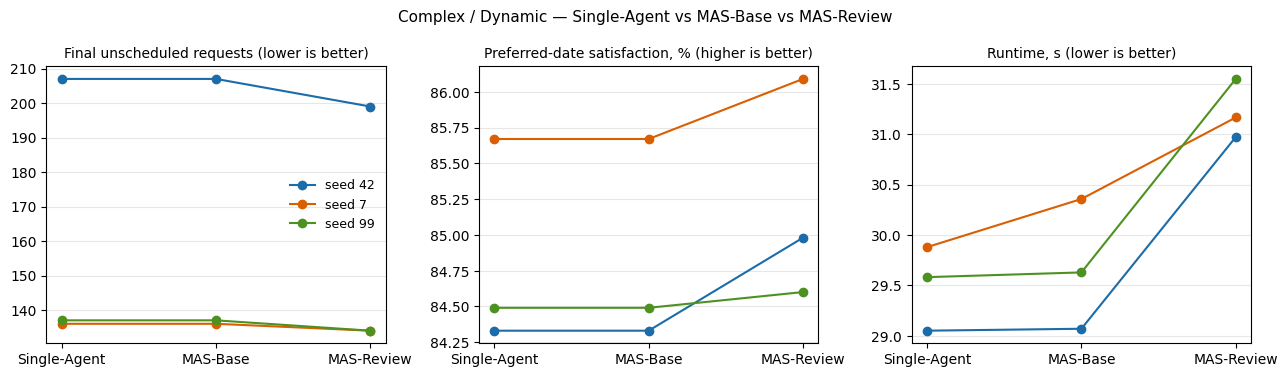

Figure saved to m6_outputs/m6_paired_results.png


In [57]:
# M6.9 — Figure: paired per-seed results (each line is one seed / one generated scenario)
try:
    import matplotlib
    import matplotlib.pyplot as plt

    _dyn = M6_RESULTS[M6_RESULTS["Environment"] == "Complex / Dynamic"]
    _panels = [("Final Unscheduled", "Final unscheduled requests (lower is better)"),
               ("Preferred Date Satisfaction (%)", "Preferred-date satisfaction, % (higher is better)"),
               ("Runtime (s)", "Runtime, s (lower is better)")]
    _colors = {42: "#1b6ca8", 7: "#d95f02", 99: "#4d9221"}
    _fig, _axes = plt.subplots(1, 3, figsize=(13, 3.8))
    for _ax, (_metric, _title) in zip(_axes, _panels):
        for _seed in M6_SEEDS:
            _vals = [float(_dyn[(_dyn["Seed"] == _seed) & (_dyn["Condition"] == c)][_metric].iloc[0]) for c in M6_CONDITIONS]
            _ax.plot(range(3), _vals, marker="o", color=_colors[_seed], label=f"seed {_seed}")
        _ax.set_xticks(range(3))
        _ax.set_xticklabels([M6_LABEL[c] for c in M6_CONDITIONS])
        _ax.set_title(_title, fontsize=10)
        _ax.grid(axis="y", alpha=.3)
    _axes[0].legend(frameon=False, fontsize=9)
    _fig.suptitle("Complex / Dynamic — Single-Agent vs MAS-Base vs MAS-Review", fontsize=11)
    _fig.tight_layout()
    _fig.savefig(M6_OUT_DIR / "m6_paired_results.png", dpi=150)
    try:
        from IPython import get_ipython
        if get_ipython() is not None:
            plt.show()
    except Exception:
        pass
    plt.close(_fig)
    print("Figure saved to", M6_OUT_DIR / "m6_paired_results.png")
except ImportError:
    print("matplotlib is not installed; figure skipped.")

### M6.10 — Failure analysis

In [58]:
# M6.10 — Failure analysis: where and why requests stay unscheduled

_event_rows = []
for _seed in M6_SEEDS:
    for _cond in M6_CONDITIONS:
        _ev = M6_RUNS["dynamic"][_seed]["runs"][_cond]["event_results_df"].copy()
        _ev["Seed"], _ev["Condition"] = _seed, M6_LABEL[_cond]
        _event_rows.append(_ev)
_events_all = pd.concat(_event_rows, ignore_index=True)
_events_all["Outcome"] = _events_all["event_type"] + " — " + _events_all["status"]
m6_event_table = (_events_all.groupby(["Outcome", "Condition"]).size().div(len(M6_SEEDS))
                  .unstack("Condition").reindex(columns=[M6_LABEL[c] for c in M6_CONDITIONS]).fillna(0)
                  .round(1).reset_index())
m6_show(m6_event_table, "M6.10a — Event outcomes (mean count per seed; 290 events per run)")

# Where do the final unscheduled requests concentrate, and did any of them have no feasible slot at all?
_diag_rows = []
for _seed in M6_SEEDS:
    _scenario = M6_COMPLEX_SCENARIOS[_seed]
    _index = _m6_build_complex_index(_scenario["doctors"], _scenario["slots"])
    _new_ids = set(_scenario["new_requests"]["request_id"].astype(str))
    for _cond in M6_CONDITIONS:
        _left = M6_RUNS["dynamic"][_seed]["runs"][_cond]["final_unscheduled_df"]
        for _req in _left.to_dict("records"):
            _pref = datetime.strptime(_req["preferred_date"], "%Y-%m-%d").date()
            _n = sum(abs((c["date_obj"] - _pref).days) <= int(_req["max_waiting_days"])
                     for c, _ in _index.get((_req["required_specialty"], int(_req["appointment_duration"])), []))
            _diag_rows.append({
                "Seed": _seed, "Condition": M6_LABEL[_cond],
                "Source": "New-request event" if str(_req["request_id"]) in _new_ids else "Initial request",
                "Duration": f"{int(_req['appointment_duration'])} min",
                "Waiting window": f"{int(_req['max_waiting_days'])} days",
                "Slot in window on the base grid": "none" if _n == 0 else "existed (taken or blocked)"})
_diag = pd.DataFrame(_diag_rows)
_blocks = []
for _col in ["Source", "Duration", "Waiting window", "Slot in window on the base grid"]:
    _t = (_diag.groupby([_col, "Condition"]).size().div(len(M6_SEEDS)).unstack("Condition")
          .reindex(columns=[M6_LABEL[c] for c in M6_CONDITIONS]).fillna(0).round(1).reset_index())
    _t.insert(0, "Group by", _col)
    _t = _t.rename(columns={_col: "Value"})
    _blocks.append(_t)
m6_failure_table = pd.concat(_blocks, ignore_index=True)
m6_show(m6_failure_table, "M6.10b — Final unscheduled requests, mean per seed")
m6_event_table.to_csv(M6_OUT_DIR / "failure_events.csv", index=False)
m6_failure_table.to_csv(M6_OUT_DIR / "failure_unscheduled.csv", index=False)
print("\nReading guide: 'existed (taken or blocked)' means the base slot grid had a slot inside the request's waiting window, "
      "but by the time the request was handled the slot was booked, over the doctor's daily limit, or blocked by an event. "
      "This is a diagnostic of the final state, not a proof that no better global assignment exists.")


M6.10a — Event outcomes (mean count per seed; 290 events per run)


Condition,Outcome,Single-Agent,MAS-Base,MAS-Review
0,Doctor Schedule Change — Recovered,30.0,30.0,30.0
1,Doctor Unavailability — No Affected Appointment,18.0,18.0,16.3
2,Doctor Unavailability — Recovered,22.0,22.0,23.7
3,New Appointment Request — Scheduled,97.0,97.0,97.7
4,New Appointment Request — Unscheduled,23.0,23.0,22.3
5,Patient Cancellation — No Affected Appointment,3.3,3.3,3.0
6,Patient Cancellation — Successful,96.7,96.7,97.0



M6.10b — Final unscheduled requests, mean per seed


Condition,Group by,Value,Single-Agent,MAS-Base,MAS-Review
0,Source,Initial request,137.0,137.0,133.3
1,Source,New-request event,23.0,23.0,22.3
2,Duration,30 min,95.0,95.0,88.0
3,Duration,60 min,65.0,65.0,67.7
4,Waiting window,3 days,65.0,65.0,61.7
5,Waiting window,5 days,57.0,57.0,55.3
6,Waiting window,7 days,38.0,38.0,38.7
7,Slot in window on the base grid,existed (taken or blocked),160.0,160.0,155.7



Reading guide: 'existed (taken or blocked)' means the base slot grid had a slot inside the request's waiting window, but by the time the request was handled the slot was booked, over the doctor's daily limit, or blocked by an event. This is a diagnostic of the final state, not a proof that no better global assignment exists.


### M6.11 — Evidence summary

In [59]:
# M6.11 — What the measurements support (generated from the results above)

def _paired(env, metric, cond_a="MAS-Review", cond_b="Single-Agent"):
    frame = M6_RESULTS[M6_RESULTS["Environment"] == env]
    a = frame[frame["Condition"] == cond_a].set_index("Seed")[metric]
    b = frame[frame["Condition"] == cond_b].set_index("Seed")[metric]
    return (a - b).astype(float)


def _direction(delta, lower_is_better):
    if (delta.abs() < 1e-9).all():
        return "no change in any seed"
    good = (delta < -1e-9) if lower_is_better else (delta > 1e-9)
    bad = (delta > 1e-9) if lower_is_better else (delta < -1e-9)
    if good.all():
        return "better in all 3 seeds"
    if bad.all():
        return "worse in all 3 seeds"
    return f"mixed ({int(good.sum())} better, {int(bad.sum())} worse, {int((~good & ~bad).sum())} same)"


_dyn, _easy = "Complex / Dynamic", "Easy / Static"
_ratio_dyn = (M6_RESULTS[(M6_RESULTS.Environment == _dyn) & (M6_RESULTS.Condition == "Multi-Agent")].set_index("Seed")["Runtime (s)"]
              / M6_RESULTS[(M6_RESULTS.Environment == _dyn) & (M6_RESULTS.Condition == "Single-Agent")].set_index("Seed")["Runtime (s)"])
_calls_dyn = M6_RESULTS[(M6_RESULTS.Environment == _dyn) & (M6_RESULTS.Condition == "Multi-Agent")]["Agent Calls"].mean()

print("EVIDENCE SUMMARY — each statement below is computed from the tables above")
print("-" * 78)
print("H1 (decomposition alone)")
print(f"  • MAS-Base produced identical schedules and event outcomes to Single-Agent in all 6 paired runs (integrity check PASS).")
print(f"  • Its cost: ≈{_calls_dyn:,.0f} agent calls per dynamic run and runtime {_ratio_dyn.mean():.2f}× Single-Agent "
      f"(range {_ratio_dyn.min():.2f}–{_ratio_dyn.max():.2f}×). API cost USD 0.")
print("\nH2 (Reviewer authority) — MAS-Review minus Single-Agent, per-seed differences")
for _env, _metric, _lower, _label in [
        (_easy, "Scheduled Patients", False, "Easy: scheduled patients"),
        (_easy, "Preferred Date Satisfaction (%)", False, "Easy: preferred-date satisfaction"),
        (_dyn, "Final Unscheduled", True, "Dynamic: final unscheduled requests"),
        (_dyn, "Final Assignment Rate (%)", False, "Dynamic: final assignment rate"),
        (_dyn, "Preferred Doctor Satisfaction (%)", False, "Dynamic: preferred-doctor satisfaction"),
        (_dyn, "Preferred Date Satisfaction (%)", False, "Dynamic: preferred-date satisfaction"),
        (_dyn, "Schedule Churn (%)", True, "Dynamic: schedule churn")]:
    _d = _paired(_env, _metric)
    print(f"  • {_label}: mean Δ {_d.mean():+.2f} (per seed: {', '.join(f'{v:+.2f}' for v in _d)}) → {_direction(_d, _lower)}")
_rt = _paired(_dyn, "Runtime (s)")
print(f"  • Dynamic runtime: mean Δ {_rt.mean():+.2f} s; Reviewer overrides per dynamic run: "
      f"{M6_RESULTS[(M6_RESULTS.Environment == _dyn) & (M6_RESULTS.Condition == 'MAS-Review')]['Reviewer Overrides'].mean():,.0f}.")
print("  • Constraint violations: 0 in all 18 runs.")
print("\nLimits of these claims")
print("  • Only 3 seeds: no significance test is attempted; differences are descriptive, and 'mixed' means the data do not settle direction.")
print("  • Seeds are different generated scenarios; all agents are deterministic, so the spread is scenario variation, not agent noise.")
print("  • The Reviewer acts on the initial allocation only; event handlers are shared M5 code.")
print("  • θ = 0.80 and δ = 10 were fixed before the first run and not tuned; other values were not explored.")
print("  • Events are generated independently of any schedule, so Single-Agent dynamic numbers differ from the M5 baseline "
      "(whose events were anchored to the baseline schedule). Only the initial schedule is expected to match M5 (checked in M6.5b).")

EVIDENCE SUMMARY — each statement below is computed from the tables above
------------------------------------------------------------------------------
H1 (decomposition alone)
  • MAS-Base produced identical schedules and event outcomes to Single-Agent in all 6 paired runs (integrity check PASS).
  • Its cost: ≈10,386 agent calls per dynamic run and runtime 1.01× Single-Agent (range 1.00–1.02×). API cost USD 0.

H2 (Reviewer authority) — MAS-Review minus Single-Agent, per-seed differences
  • Easy: scheduled patients: mean Δ +0.00 (per seed: +0.00, +0.00, +0.00) → no change in any seed
  • Easy: preferred-date satisfaction: mean Δ +0.00 (per seed: +0.00, +0.00, +0.00) → no change in any seed
  • Dynamic: final unscheduled requests: mean Δ -4.33 (per seed: -8.00, -2.00, -3.00) → better in all 3 seeds
  • Dynamic: final assignment rate: mean Δ +0.13 (per seed: +0.24, +0.06, +0.09) → better in all 3 seeds
  • Dynamic: preferred-doctor satisfaction: mean Δ +4.71 (per seed: +3.27, +5.32, 

### M6.12 — Notes carried into the paper (M7)

**Threats to validity**
1. **Few seeds, synthetic data.** Three generated scenarios and no real hospital data; the results describe this generator, not hospitals.
2. **Rule-based agents.** No language model is involved, so these results say nothing about LLM-based multi-agent systems; "agents" here are components of one deterministic policy.
3. **Hand-set Reviewer parameters.** θ and δ were chosen a priori and not tuned; a different rule could give different results.
4. **Timing.** Wall-clock times come from a shared machine; conditions were run in rotating order to avoid a fixed first-run effect, but three runs per condition cannot separate machine noise from architecture overhead.

**Responsible use**
- **Data:** fully synthetic (generated by the notebook), no personal or patient data; provenance is the generators in M1–M5 and the fixed seeds.
- **Cost:** zero external API cost; local compute only.
- **Safety:** this is a research simulation, not a clinical scheduling tool. Any real deployment would need privacy review, fairness checks (e.g. which patients lose preferences when capacity is protected) and human override.